# Nettoyage

Les données téléchargées sont dans `../data/` .
Dans ce notebook, on centre sur paris, on gardes les bonnes colonnes, et on nettoie les données. Les modifications sont enregistrées  `../data_cleans/`.

# Bibliothéque 

In [1]:
import geopandas as gpd
from IPython.display import display
import pandas as pd
import pyarrow.parquet as pq
import os
import numpy as np
import matplotlib.pyplot as plt

Variables Globales

In [2]:
# dossier a parcourrir
LIST_FILES = "../data/"
SOUS_DOSSIERS = ["Couches SIG air-bruit 2024_9_classes/AirBruit_2024.shp", "base-ic-activite-residents-2022_csv/base-ic-activite-residents-2022.CSV",
                 "IDFM-gtfs/stops.txt", "IDFM-gtfs/stop_times.txt", "IDFM-gtfs/trips.txt", "IDFM-gtfs/routes.txt", "IDFM-gtfs/calendar.txt", "IDFM-gtfs/calendar_dates.txt"]

#colonne à garder
COLUMNS_TO_KEEP_ESPACE_VERT = ['nom_ev', 'type_ev', 'categorie', 'adresse_libellevoie', 'adresse_codepostal', 'surface_totale_reelle', 'surface_horticole', 'ouvert_ferme', 'geom']
COLUMNS_TO_KEEP_SIRET = ['siret', 'x', 'y', 'qualite_xy', 'plg_iris', 'plg_code_commune']
COLUMNS_TO_KEEP_IRIS = ['code_iris', 'nom_iris', 'typ_iris', 'nom_com', 'geometry']
COLUMNS_TO_KEEP_IRIS2 = ['typ_iris', 'code_iris', 'nom_iris', 'nom_com', 'insee_com', 'geometry']
COLUMNS_TO_KEEP_ARBRE = ['domanialite', 'arrondissement', 'libellefrancais', 'genre', 'espece', 'circonferenceencm', 'hauteurenm', 'stadedeveloppement', 'remarquable', 'geo_point_2d']
COLUMNS_TO_KEEP_LIEUX_MUNICIPAUX = ['id', 'name', 'categorie', 'address_street', 'address_postcode', 'address_city', 'accessibility', 'latitude', 'longitude', 'geo']
COLUMNS_TO_KEEP_LOYER = ['annee', 'id_zone', 'id_quartier', 'nom_quartier', 'piece', 'epoque', 'meuble_txt', 'ref', 'max', 'min', 'ville', 'geometry']
COLUMNS_TO_KEEP_STATIONNEMENT_RESIDENCE = ['nom', 'st_area_shape', 'st_perimeter_shape', 'geo_point_2d', 'geometry']
COLUMNS_TO_KEEP_STATIONNEMENT_EMPLACEMENT = ['regpri', 'typsta', 'plarel', 'arrond', 'zoneres', 'locsta', 'numvoie', 'typevoie', 'nomvoie', 'parite', 'lon', 'lar', 'surface_calculee', 'geo_shape', 'geo_point_2d']
COLUMNS_TO_KEEP_VELO = ['stationcode', 'name', 'capacity', 'geometry']
COLUMNS_TO_KEEP_ANNUAIRE = ['identifiant_de_l_etablissement', 'nom_etablissement', 'type_etablissement', 'statut_public_prive', 'appartenance_education_prioritaire', 'libelle_departement', 'latitude', 'longitude', 'geometry']
COLUMNS_TO_KEEP_VA_COLLEGES = ['Session', 'UAI', 'Département', 'Taux de réussite G', 'VA du taux de réussite G', "Note à l'écrit G", "Taux d'accès 6eme 3eme"]
COLUMNS_TO_KEEP_IPS = ['Rentrée scolaire', 'UAI', 'Département', 'IPS', "IPS de l'établissement"]
COLUMNS_TO_KEEP_LOGEMENT = ['IRIS', 'COM', 'P22_LOG', 'P22_RP', 'P22_MAISON', 'P22_APPART', 'P22_RP_PROP', 'P22_RP_LOC', 'P22_RP_LOCHLMV', 'P22_LOGVAC', 'P22_RSECOCC',
                            'P22_RP_1P', 'P22_RP_2P', 'P22_RP_5PP', 'P22_RP_100120M2', 'P22_RP_120M2P', 'P22_RP_ACH1919', 'P22_RP_ACH1945', 'P22_RP_ACH2019', 'P22_RP_ACHTOT',
                            'P22_MEN_ANEM10P', 'P22_MEN', 'P22_RP_VOIT1P', 'P22_RP_GARL',
                            'C22_RP_NORME', 'C22_RP_SUROCC_MOD', 'C22_RP_SUROCC_ACC', 'C22_RP_SOUSOCC_MOD', 'C22_RP_SOUSOCC_ACC', 'C22_RP_SOUSOCC_TACC']
COLUMNS_TO_KEEP_ACTIVITE = ['IRIS', 'COM', 'P22_POP1564', 'P22_POP1524', 'P22_POP5564', 'P22_ACT1564', 'P22_CHOM1564', 'P22_ETUD1564', 'P22_RETR1564',
                            'C22_ACT1564', 'C22_ACT1564_STAT_GSEC12_22', 'C22_ACT1564_STAT_GSEC13_23', 'C22_ACT1564_STAT_GSEC14_24', 'C22_ACT1564_STAT_GSEC15_25', 'C22_ACT1564_STAT_GSEC16_26',
                            'P22_ACTOCC15P', 'P22_SAL15P', 'P22_NSAL15P', 'P22_SAL15P_TP', 'P22_ACTOCC15P_ILT1',
                            'C22_ACTOCC15P', 'C22_ACTOCC15P_TCOM', 'C22_ACTOCC15P_VOIT', 'C22_ACTOCC15P_VELO', 'C22_ACTOCC15P_MAR']
COLUMNS_TO_KEEP_AIR_BRUIT = ['9', 'geometry']
COLUMNS_TO_KEEP_DVF = ['id_mutation', 'date_mutation', 'nature_mutation', 'valeur_fonciere', 'type_local', 'surface_reelle_bati', 'nombre_pieces_principales', 'code_commune', 'longitude', 'latitude']
COLUMNS_TO_KEEP_SIRENE_STOCK = ['siret', 'codeCommuneEtablissement', 'etatAdministratifEtablissement', 'activitePrincipaleEtablissement', 'enseigne1Etablissement']
COLUMNS_TO_KEEP_UNITE_LEGALE = ['siren', 'categorieEntreprise', 'trancheEffectifsUniteLegale', 'categorieJuridiqueUniteLegale', 'etatAdministratifUniteLegale']
COLUMNS_TO_KEEP_GTFS = ['stop_id', 'stop_name', 'stop_lon', 'stop_lat', 'location_type', 'parent_station', 'wheelchair_boarding',
                        'trip_id', 'departure_time',
                        'route_id', 'service_id', 'route_short_name', 'route_type',
                        'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date',
                        'date', 'exception_type']

COLUMNS_T0_KEEP = [COLUMNS_TO_KEEP_ESPACE_VERT + COLUMNS_TO_KEEP_SIRET + COLUMNS_TO_KEEP_IRIS + COLUMNS_TO_KEEP_IRIS2 + COLUMNS_TO_KEEP_ARBRE + COLUMNS_TO_KEEP_LIEUX_MUNICIPAUX + COLUMNS_TO_KEEP_LOYER + COLUMNS_TO_KEEP_STATIONNEMENT_RESIDENCE + COLUMNS_TO_KEEP_STATIONNEMENT_EMPLACEMENT + COLUMNS_TO_KEEP_VELO
                   + COLUMNS_TO_KEEP_ANNUAIRE + COLUMNS_TO_KEEP_VA_COLLEGES + COLUMNS_TO_KEEP_IPS + COLUMNS_TO_KEEP_LOGEMENT + COLUMNS_TO_KEEP_ACTIVITE + COLUMNS_TO_KEEP_AIR_BRUIT
                   + COLUMNS_TO_KEEP_DVF + COLUMNS_TO_KEEP_SIRENE_STOCK + COLUMNS_TO_KEEP_UNITE_LEGALE + COLUMNS_TO_KEEP_GTFS]

#filter pour garder que paris
FILTRE_PARIS = ['75', 'paris']
COLUMNS_PARIS = ['dep', 'ville', 'address_city', 'plg_code_commune', 'COM', 'Département', 'libelle_departement', 'code_commune', 'codeCommuneEtablissement']


L93 = 2154 
#sortie
OUTPUT_DIR = "../data_cleans/"

In [3]:
paris = gpd.read_file(os.path.join(LIST_FILES, "iris.geojson")).query("dep == '75'")
contour_paris = paris.to_crs(L93).union_all()
ids_paris = {}

def filtre_paris(df):
    for col in COLUMNS_PARIS:
        if col in df.columns:

            valeurs = df[col].astype(str)
            df = df[valeurs.str.startswith(FILTRE_PARIS[0]) | valeurs.str.lower().str.contains(FILTRE_PARIS[1])]
    
    
    if {"stop_lon", "stop_lat"} <= set(df.columns):
        
        arrets = gpd.GeoSeries(gpd.points_from_xy(df["stop_lon"], df["stop_lat"]), index=df.index, crs=4326).to_crs(L93)
        
        df = df[arrets.within(contour_paris)]
    
    for col, ids in ids_paris.items():
        if col in df.columns and "siret" not in df.columns:
            df = df[df[col].isin(ids)]

    return df

Skipping field geo_point_2d: unsupported OGR type: 3


In [4]:
file_load = {}
for files in sorted(os.listdir(LIST_FILES)) + SOUS_DOSSIERS:
    path = os.path.join(LIST_FILES, files)
    
    if files.endswith(".parquet"):
        parquet = pq.ParquetFile(path)
        colonnes = [c for c in parquet.schema_arrow.names if c in COLUMNS_T0_KEEP[0]]
        morceaux = (b.to_pandas() for b in parquet.iter_batches(batch_size=1_000_000, columns=colonnes or None))
    
    elif files.endswith(".csv") or files.endswith(".CSV") or files.endswith(".txt"):
        with open(path, encoding="utf-8") as f:
            sep = ";" if ";" in f.readline() else ","
        morceaux = pd.read_csv(path, sep=sep, usecols=lambda c: c in COLUMNS_T0_KEEP[0], chunksize=1_000_000,
                               dtype={"IRIS": str, "COM": str, "UAI": str, "code_commune": str, "code_iris": str, "parent_station": str})

    
    elif files.endswith((".geojson", ".shp")):
        morceaux = [gpd.read_file(path, bbox=paris)]

    else:
        continue

    #découpe le fichier car mon pc n'est pas assez puissant, spark n'est pas utile car une fois nettoyer, c'est bon
    df = pd.concat([filtre_paris(m) for m in morceaux])
    file_load[os.path.basename(files)] = df

    if "siret" in df.columns:
        ids_paris["siren"] = set(df["siret"].str[:9])

    for col in ["stop_id", "trip_id", "route_id", "service_id"]:
        if col in df.columns and col not in ids_paris:
            ids_paris[col] = set(df[col])

display(pd.DataFrame({f: df.shape for f, df in file_load.items()}, index=["lignes", "colonnes"]).T)

Skipping field geo_point_2d: unsupported OGR type: 3
Skipping field geo_point_2d: unsupported OGR type: 3


,lignes,colonnes
base-ic-logement-2022.CSV,992,30
espaces_verts.parquet,2535,9
fr-en-annuaire-education.geojson,1459,72
fr-en-indicateurs-valeur-ajoutee-colleges.csv,672,7
fr-en-ips-ecoles-ap2022.csv,1367,4
fr-en-ips-lycees-ap2023.csv,474,4
full-2025.csv,86190,10
geoloc-geolocalisationetablissement-sirene-pour-etudes-statistiques-parquet.parquet,3319807,6
iris.geojson,992,9
iris_paris_dataset.csv,992,5


In [5]:
for i, df in file_load.items():
    display(df.dtypes)

IRIS                       str
COM                        str
P22_LOG                float64
P22_RP                 float64
P22_RSECOCC            float64
P22_LOGVAC             float64
P22_MAISON             float64
P22_APPART             float64
P22_RP_1P              float64
P22_RP_2P              float64
P22_RP_5PP             float64
P22_RP_100120M2        float64
P22_RP_120M2P          float64
P22_RP_ACHTOT          float64
P22_RP_ACH1919         float64
P22_RP_ACH1945         float64
P22_RP_ACH2019         float64
P22_MEN                float64
P22_MEN_ANEM10P        float64
P22_RP_PROP            float64
P22_RP_LOC             float64
P22_RP_LOCHLMV         float64
P22_RP_GARL            float64
P22_RP_VOIT1P          float64
C22_RP_NORME           float64
C22_RP_SOUSOCC_MOD     float64
C22_RP_SOUSOCC_ACC     float64
C22_RP_SOUSOCC_TACC    float64
C22_RP_SUROCC_MOD      float64
C22_RP_SUROCC_ACC      float64
dtype: object

nom_ev                    object
type_ev                   object
categorie                 object
adresse_libellevoie       object
adresse_codepostal        object
surface_totale_reelle    float64
surface_horticole        float64
ouvert_ferme              object
geom                      object
dtype: object

identifiant_de_l_etablissement             str
nom_etablissement                          str
type_etablissement                         str
statut_public_prive                        str
adresse_1                                  str
                                        ...   
code_zone_animation_pedagogique            str
libelle_zone_animation_pedagogique         str
code_bassin_formation                      str
libelle_bassin_formation                   str
geometry                              geometry
Length: 72, dtype: object

Session                       int64
UAI                             str
Département                     str
Taux de réussite G          float64
VA du taux de réussite G    float64
Note à l'écrit G            float64
Taux d'accès 6eme 3eme      float64
dtype: object

Rentrée scolaire    str
Département         str
UAI                 str
IPS                 str
dtype: object

Rentrée scolaire              str
Département                   str
UAI                           str
IPS de l'établissement    float64
dtype: object

... (19 outputs left out)

route_id      str
service_id    str
trip_id       str
dtype: object

route_id              str
route_short_name      str
route_type          int64
dtype: object

service_id      str
monday        int64
tuesday       int64
wednesday     int64
thursday      int64
friday        int64
saturday      int64
sunday        int64
start_date    int64
end_date      int64
dtype: object

service_id          str
date              int64
exception_type    int64
dtype: object

 On garde que les colonnes qui nous intéresse

In [6]:
list_df = {} 

for i, df in file_load.items():
    valid_cols = [c for c in dict.fromkeys(COLUMNS_T0_KEEP[0]) if c in df.columns]
    if len(valid_cols) > 0 and len(df) > 0:
        list_df[i] = df[valid_cols]
        display(df[valid_cols].head())

,IRIS,COM,P22_LOG,P22_RP,P22_MAISON,P22_APPART,P22_RP_PROP,P22_RP_LOC,P22_RP_LOCHLMV,P22_LOGVAC,...,P22_MEN_ANEM10P,P22_MEN,P22_RP_VOIT1P,P22_RP_GARL,C22_RP_NORME,C22_RP_SUROCC_MOD,C22_RP_SUROCC_ACC,C22_RP_SOUSOCC_MOD,C22_RP_SOUSOCC_ACC,C22_RP_SOUSOCC_TACC
37728,751010101,75101,738.983338,531.544449,15.497402,714.878401,107.509133,385.419938,100.208225,75.437459,...,204.682050,531.544449,139.402158,84.927265,197.687648,105.711658,6.304702,160.633089,29.151425,26.711984
37729,751010102,75101,228.689855,98.947192,3.256307,225.433549,53.610757,40.281691,0.000000,35.409462,...,49.290500,98.947192,40.109056,26.076275,41.084976,15.795800,0.000000,28.100223,4.746688,0.000000
37730,751010103,75101,208.841733,168.958560,0.000000,208.841733,20.376671,138.514505,7.026940,16.365868,...,88.090999,168.958560,42.018289,23.730758,56.119252,30.154513,3.491377,25.767989,21.902311,18.712196
37731,751010104,75101,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
37732,751010105,75101,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


,nom_ev,type_ev,categorie,adresse_libellevoie,adresse_codepostal,surface_totale_reelle,surface_horticole,ouvert_ferme,geom
0,JARDINIERES DE LA RUE DE NICE,Végétalisation d'espace public,Jardiniere,DE NICE,75011,83.0,83.0,None,"b""\x01\x06\x00\x00\x00\x02\x00\x00\x00\x01\x03..."
1,PARC DES RIVES DE SEINE,Promenades ouvertes,Parc,HENRI IV,75004,4769.0,3334.0,Oui,b'\x01\x06\x00\x00\x00\x17\x00\x00\x00\x01\x03...
2,JARDINIERE DU MONUMENT FRANCOIS COPPEE,Végétalisation d'espace public,Jardiniere,ESTREES,75007,172.0,172.0,None,b'\x01\x06\x00\x00\x00\x02\x00\x00\x00\x01\x03...
3,JARDINIERES EVQ DU 69 RUE JEAN-BAPTISTE PIGALLE,Végétalisation d'espace public,Jardiniere,JEAN-BAPTISTE PIGALLE,75009,157.0,157.0,None,b'\x01\x06\x00\x00\x00\x03\x00\x00\x00\x01\x03...
4,JARDINIERES EVQ RUE DELAMBRE,Végétalisation d'espace public,Jardiniere,DELAMBRE,75014,100.0,100.0,None,b'\x01\x06\x00\x00\x00\x0c\x00\x00\x00\x01\x03...


,geometry,latitude,longitude,identifiant_de_l_etablissement,nom_etablissement,type_etablissement,statut_public_prive,appartenance_education_prioritaire,libelle_departement,code_commune
34,POINT (2.31365 48.84967),48.849673,2.313650,0750185U,E.P.PR SAINTE-JEANNE ELISABETH 49 avenue duquesne,Ecole,Privé,NaN,Paris,75107
36,POINT (2.31794 48.82988),48.829878,2.317936,0755498U,E.P.PR GEORGES GUSDORF 98 rue Didot,Ecole,Privé,NaN,Paris,75114
38,POINT (2.30784 48.88448),48.884477,2.307843,0750704H,Lycée Carnot,Lycée,Public,NaN,Paris,75117
69,POINT (2.27216 48.86698),48.866984,2.272161,0752919R,Collège privé Pascal,Collège,Privé,NaN,Paris,75116
70,POINT (2.28549 48.85958),48.859582,2.285485,0752917N,Collège privé Saint-Louis de Gonzague,Collège,Privé,NaN,Paris,75116


,Session,UAI,Département,Taux de réussite G,VA du taux de réussite G,Note à l'écrit G,Taux d'accès 6eme 3eme
1449,2025,0750609E,PARIS,88.0,-4.0,10.7,95.0
1450,2025,0750610F,PARIS,84.0,-3.0,11.1,92.0
1451,2025,0750611G,PARIS,96.0,2.0,12.0,95.0
1452,2025,0751563S,PARIS,78.0,-10.0,10.1,86.0
1453,2025,0751706X,PARIS,92.0,8.0,10.8,96.0


,UAI,Département,Rentrée scolaire,IPS
23562,0750132L,PARIS,2022-2023,144.5
23563,0750136R,PARIS,2022-2023,139.8
23564,0750138T,PARIS,2022-2023,142.7
23565,0750141W,PARIS,2022-2023,146.4
23566,0750142X,PARIS,2022-2023,134.5


,UAI,Département,Rentrée scolaire,IPS de l'établissement
507,0750463W,PARIS,2023-2024,119.8
508,0750558Z,PARIS,2023-2024,118.3
509,0750651A,PARIS,2023-2024,104.4
510,0750657G,PARIS,2023-2024,136.1
511,0750660K,PARIS,2023-2024,145.4


... (17 outputs left out)

,trip_id,route_id,service_id
0,IDFM:RATP:COU_RATP_388795_313950_446,IDFM:C01385,IDFM:1
1,IDFM:MARNE_ET_OURCQ:22098258,IDFM:C01639,IDFM:1
10,IDFM:RATP:COU_RATP_03DILAUTREC1_2026_Gall01Lev...,IDFM:C01373,IDFM:1
11,IDFM:RATP:COU_RATP_03DILAUTREC1_2026_Leva01Cha...,IDFM:C01373,IDFM:1
13,IDFM:RATP:COU_RATP_03DILAUTREC1_2026_Leva02Gal...,IDFM:C01373,IDFM:1


,route_id,route_short_name,route_type
6,IDFM:C02317,T9,0
11,IDFM:C01094,57,3
22,IDFM:C01639,N141,3
26,IDFM:C01640,N142,3
27,IDFM:C01642,N134,3


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,IDFM:1,1,1,1,1,1,1,1,20261106,20261205
1,IDFM:1409,0,1,0,1,0,0,0,20261112,20261203
2,IDFM:10000,1,1,1,1,1,0,0,20261106,20261204
4,IDFM:14348,0,0,0,0,0,1,1,20261107,20261205
5,IDFM:14349,0,0,0,0,1,0,0,20261106,20261204


,service_id,date,exception_type
0,IDFM:10000,20261111,2
2,IDFM:14348,20261111,1
3,IDFM:14349,20261110,1
4,IDFM:14646,20261110,2
5,IDFM:15429,20261110,1


## Profil des données

On aurait pu utiliser ydata_profiling mais ceci aurait été de la triche.

Nettoyage :  les manquants, les zéros, les valeurs uniques, les valeurs convertibles en nombre  et le min / max pour repérer les valeurs absurdes.

In [7]:
def profile_dataframe(df, name=None):
    df = df.loc[:, ~df.columns.duplicated()]

    profile = {}
    profile['name_df'] = name
    profile['num_rows'] = len(df)
    profile['num_columns'] = len(df.columns)
    profile['columns'] = {}
    profile['num_duplicated_rows'] = df.duplicated().sum()

    for col in df.columns:
        numerique = pd.api.types.is_numeric_dtype(df[col])
        texte = df[col].dtype == object

        col_profile = {}
        col_profile['dtype'] = str(df[col].dtype)
        col_profile['num_missing'] = df[col].isnull().sum()
        col_profile['num_unique'] = df[col].nunique()
        col_profile['num_unique_normalized'] = df[col].dropna().map(str).str.strip().str.lower().nunique() if texte else None
        col_profile['num_convertible_numeric'] = pd.to_numeric(df[col], errors='coerce').notna().sum() if texte else None
        col_profile['num_zeros'] = (df[col] == 0).sum() if numerique else None
        col_profile['min'] = df[col].min() if numerique else None
        col_profile['max'] = df[col].max() if numerique else None
        col_profile['value_counts'] = df[col].value_counts().head(5)

        profile['columns'][col] = col_profile

    return profile

def global_profile(lst):
    return [profile_dataframe(df, name=name) for name, df in lst]

profile_results = global_profile(list_df.items())
display(profile_results)


[{'name_df': 'base-ic-logement-2022.CSV',
  'num_rows': 992,
  'num_columns': 30,
  'columns': {'IRIS': {'dtype': 'str',
    'num_missing': np.int64(0),
    'num_unique': 992,
    'num_unique_normalized': None,
    'num_convertible_numeric': None,
    'num_zeros': None,
    'min': None,
    'max': None,
    'value_counts': IRIS
    751010101    1
    751010102    1
    751010103    1
    751010104    1
    751010105    1
    Name: count, dtype: int64},
   'COM': {'dtype': 'str',
    'num_missing': np.int64(0),
    'num_unique': 20,
    'num_unique_normalized': None,
    'num_convertible_numeric': None,
    'num_zeros': None,
    'min': None,
    'max': None,
    'value_counts': COM
    75115    96
    75116    83
    75118    75
    75119    75
    75113    73
    Name: count, dtype: int64},
   'P22_LOG': {'dtype': 'float64',
    'num_missing': np.int64(0),
    'num_unique': 941,
    'num_unique_normalized': None,
    'num_convertible_numeric': None,
    'num_zeros': np.int64(52),
    

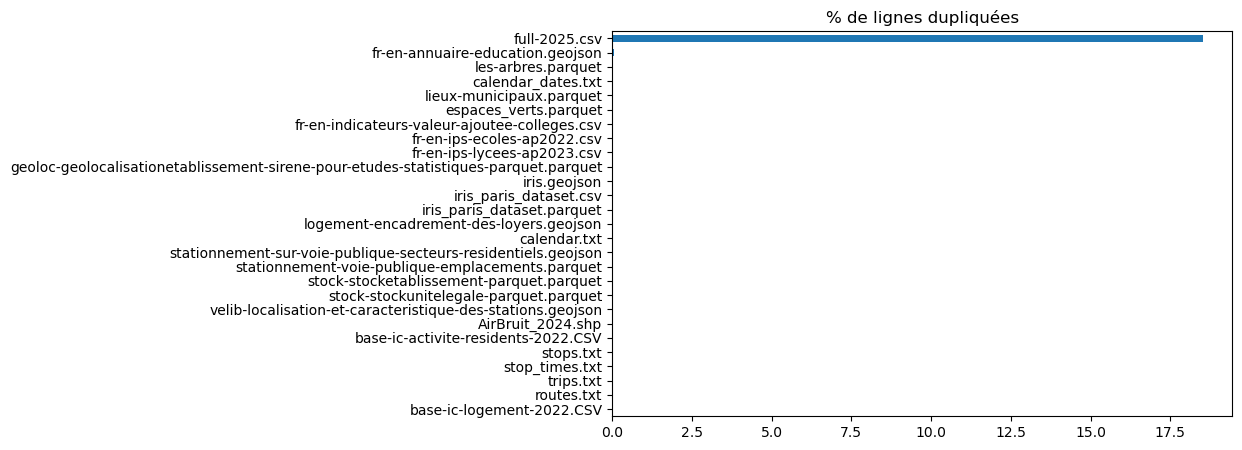

/var/folders/5g/lb5rqdn537gdsvb2ylrqtblm0000gn/T/ipykernel_98552/3981692290.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


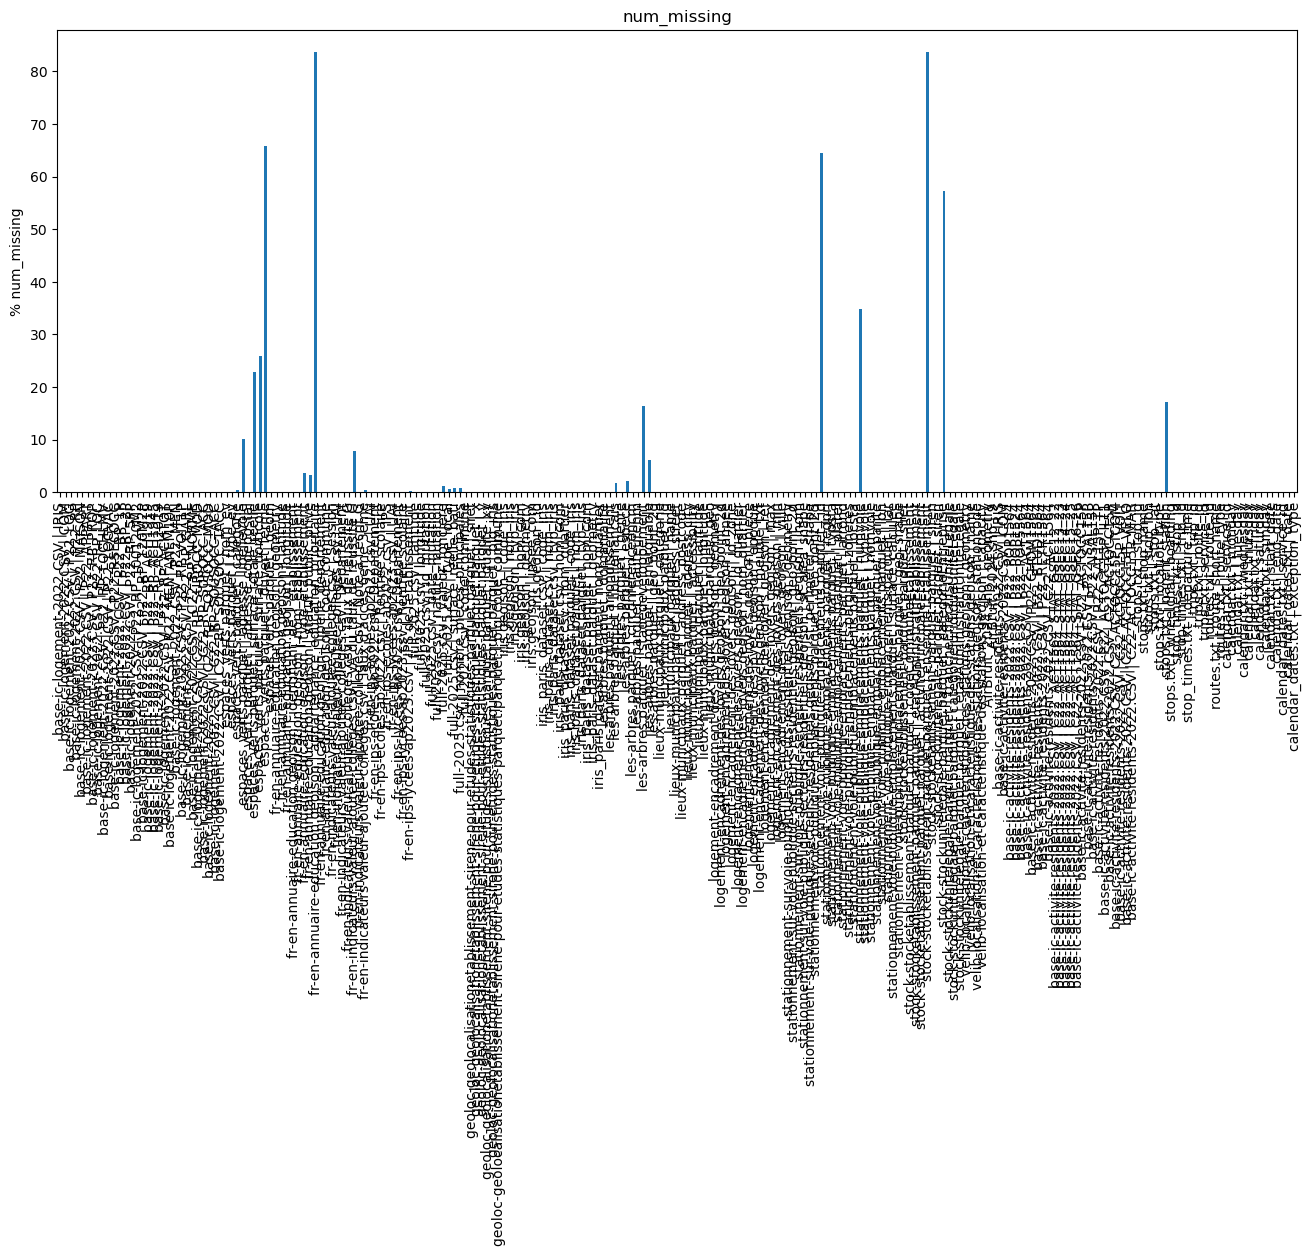

/var/folders/5g/lb5rqdn537gdsvb2ylrqtblm0000gn/T/ipykernel_98552/3981692290.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


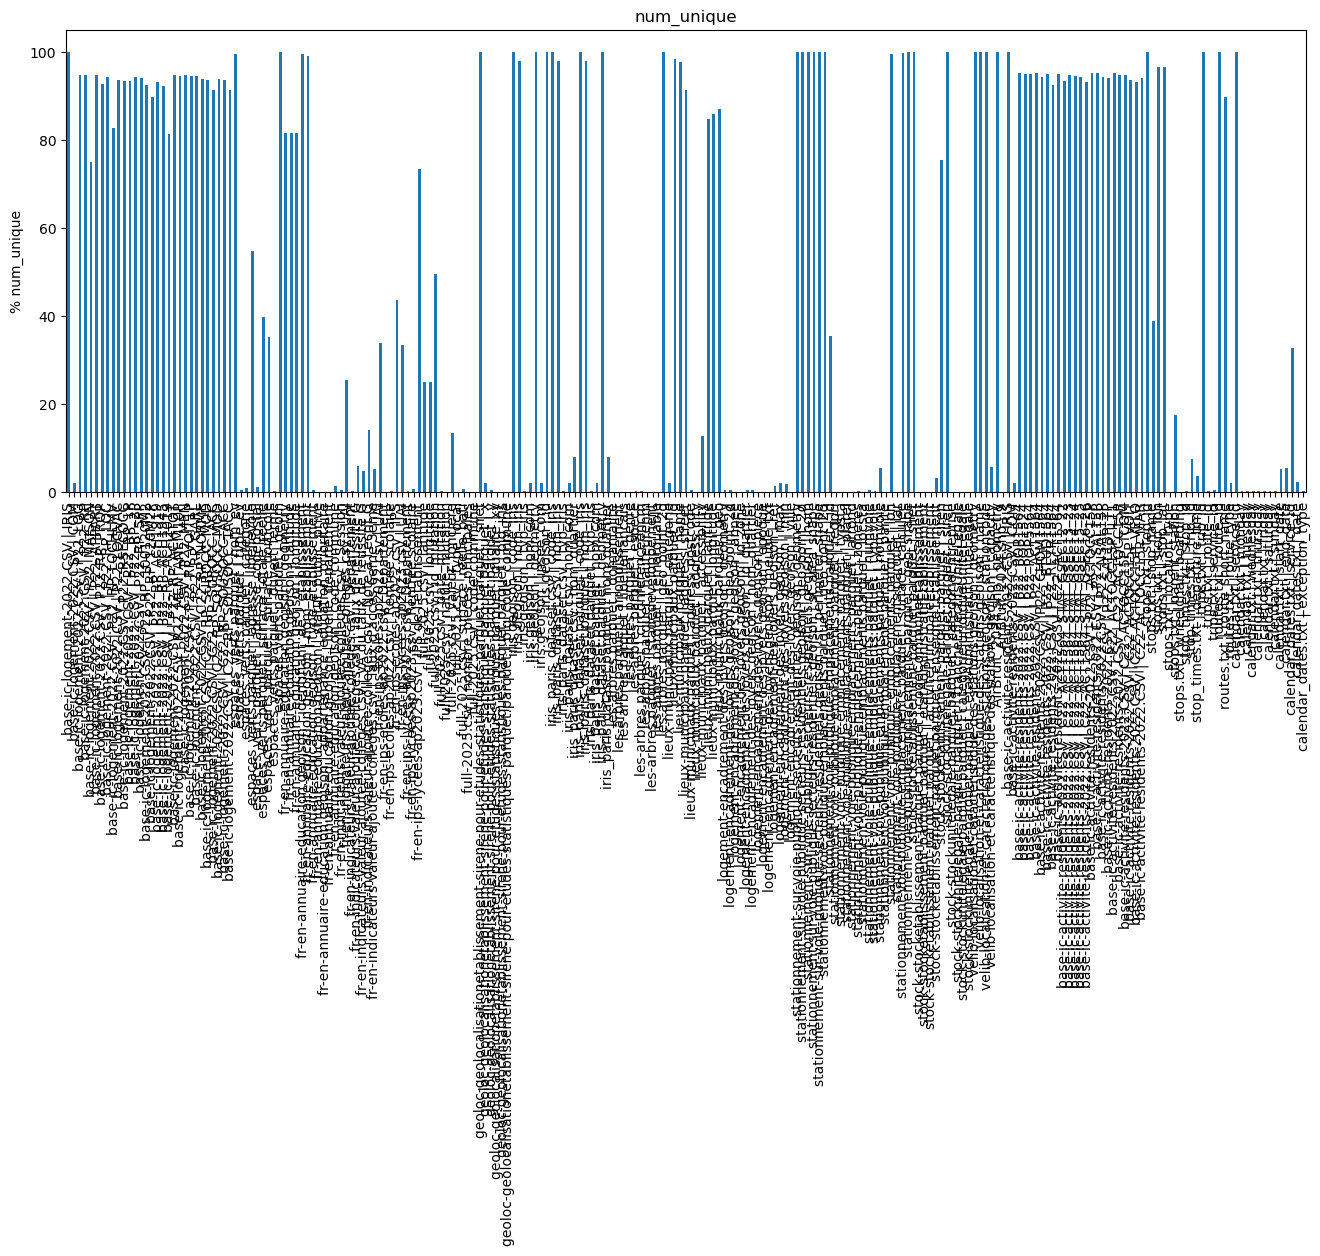

/var/folders/5g/lb5rqdn537gdsvb2ylrqtblm0000gn/T/ipykernel_98552/3981692290.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


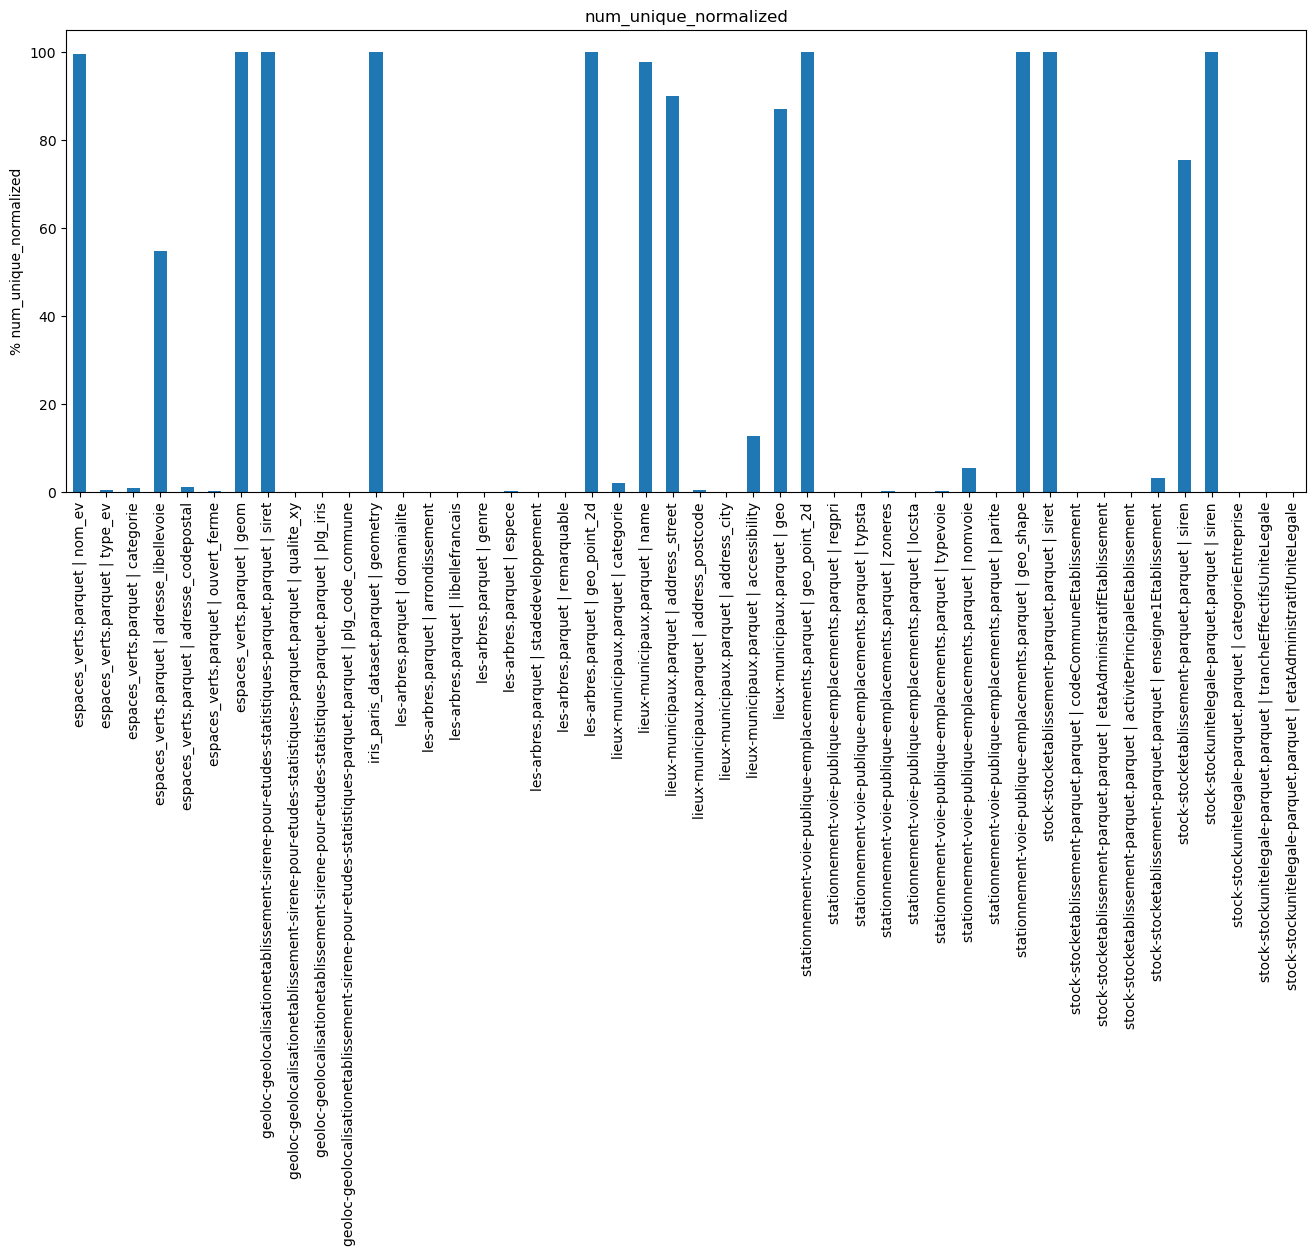

/var/folders/5g/lb5rqdn537gdsvb2ylrqtblm0000gn/T/ipykernel_98552/3981692290.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


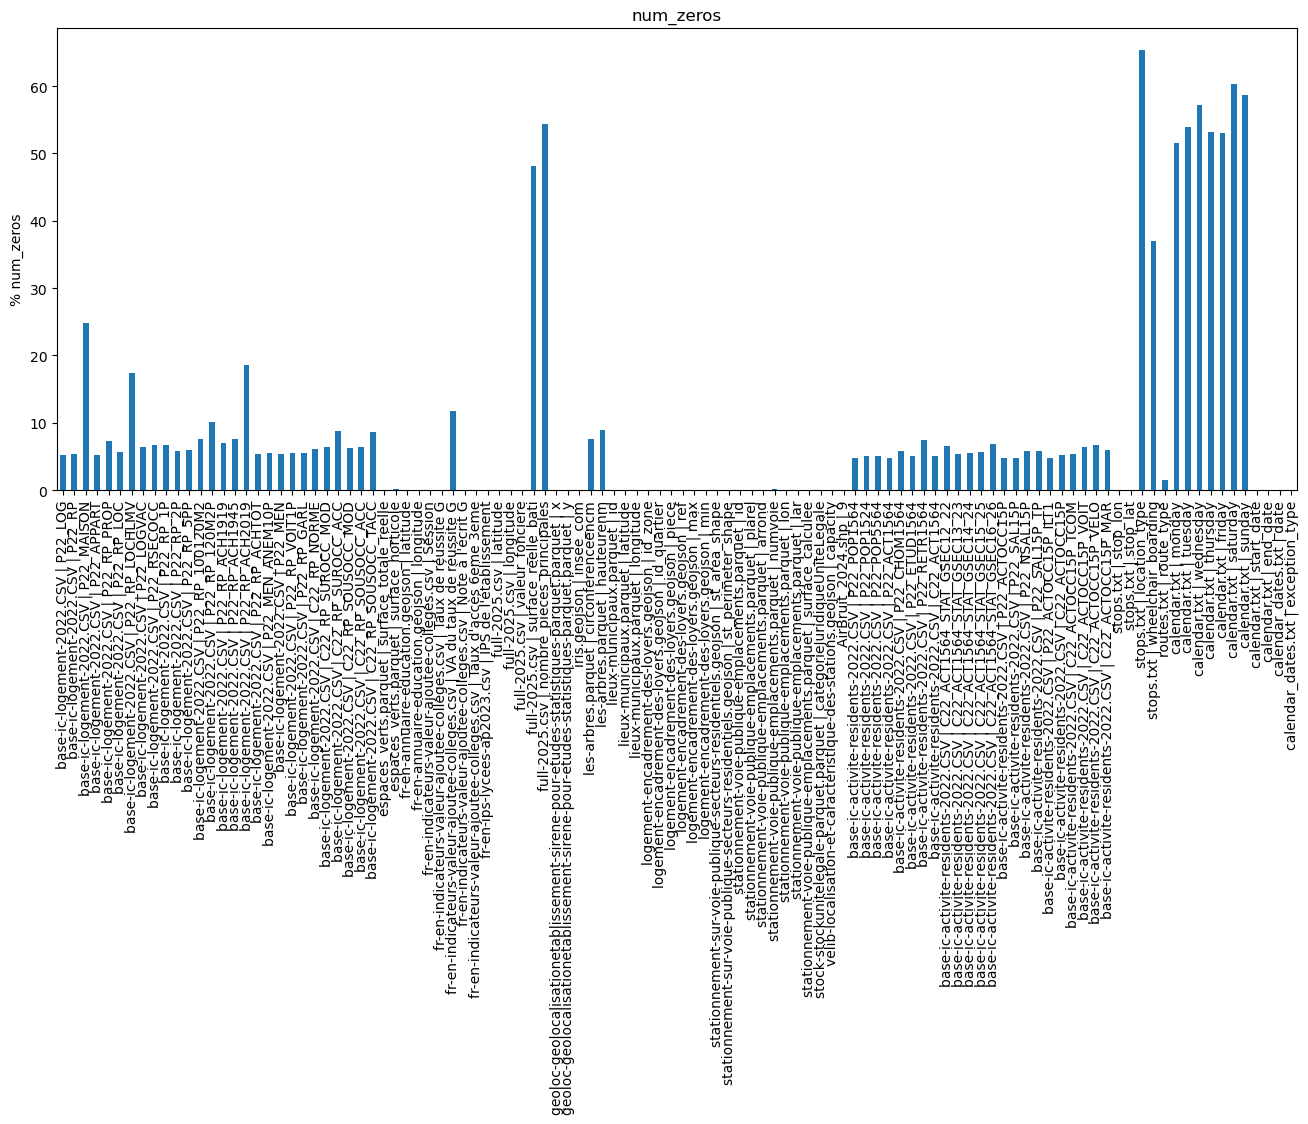

/var/folders/5g/lb5rqdn537gdsvb2ylrqtblm0000gn/T/ipykernel_98552/3981692290.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


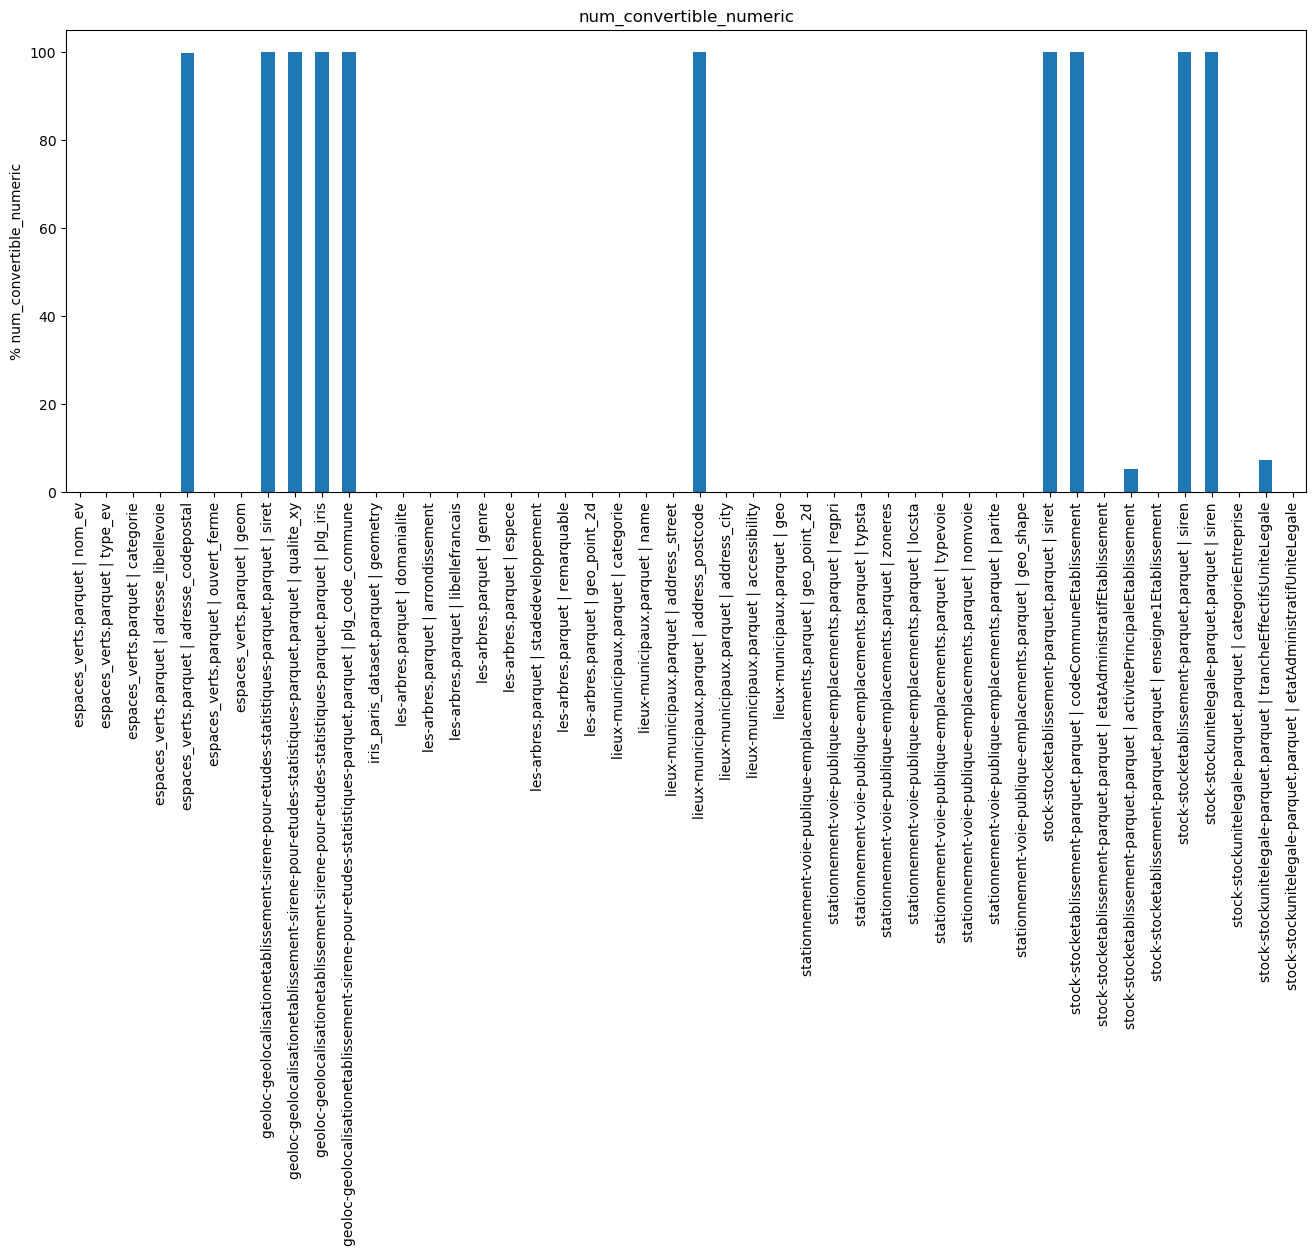

base-ic-logement-2022.CSV : 992 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
IRIS,0.0,100.0,,,
COM,0.0,2.0,,,
P22_LOG,0.0,94.9,,5.2,
P22_RP,0.0,94.8,,5.3,
P22_MAISON,0.0,75.1,,24.8,
P22_APPART,0.0,94.9,,5.2,
P22_RP_PROP,0.0,92.7,,7.4,
P22_RP_LOC,0.0,94.5,,5.6,
P22_RP_LOCHLMV,0.0,82.7,,17.3,
P22_LOGVAC,0.0,93.8,,6.4,


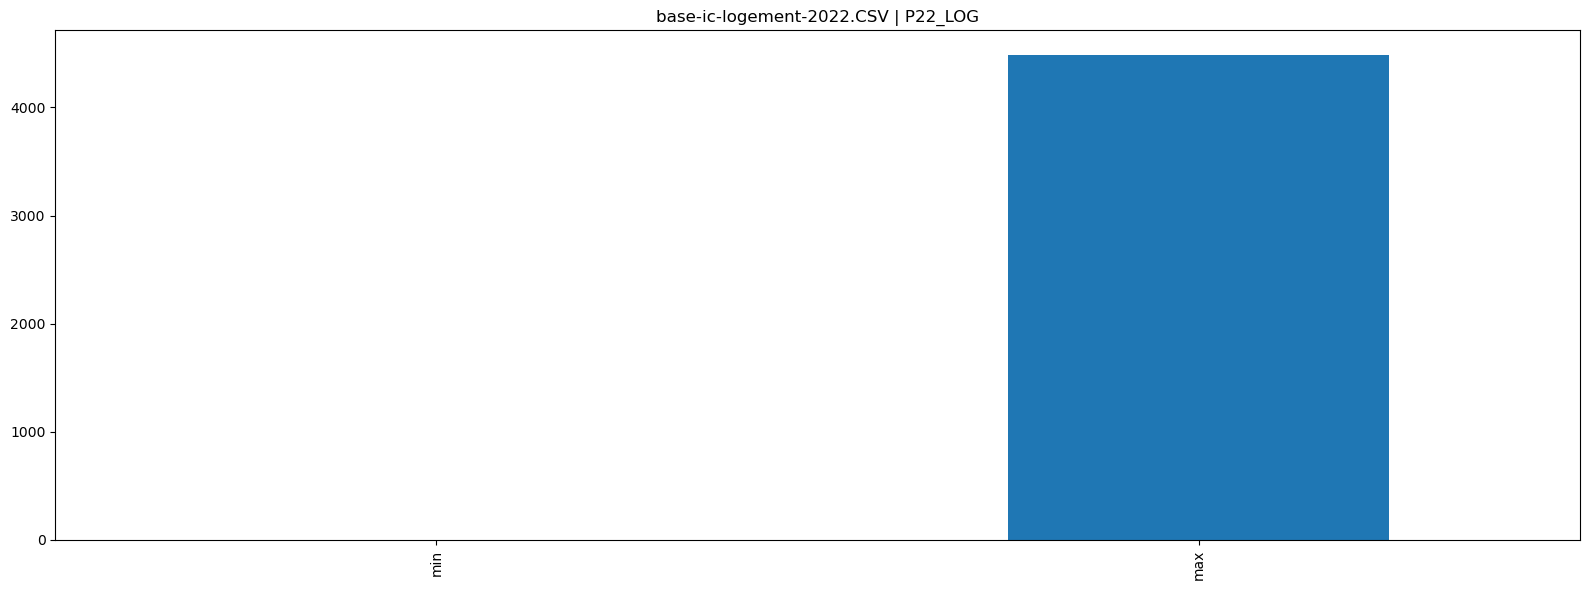

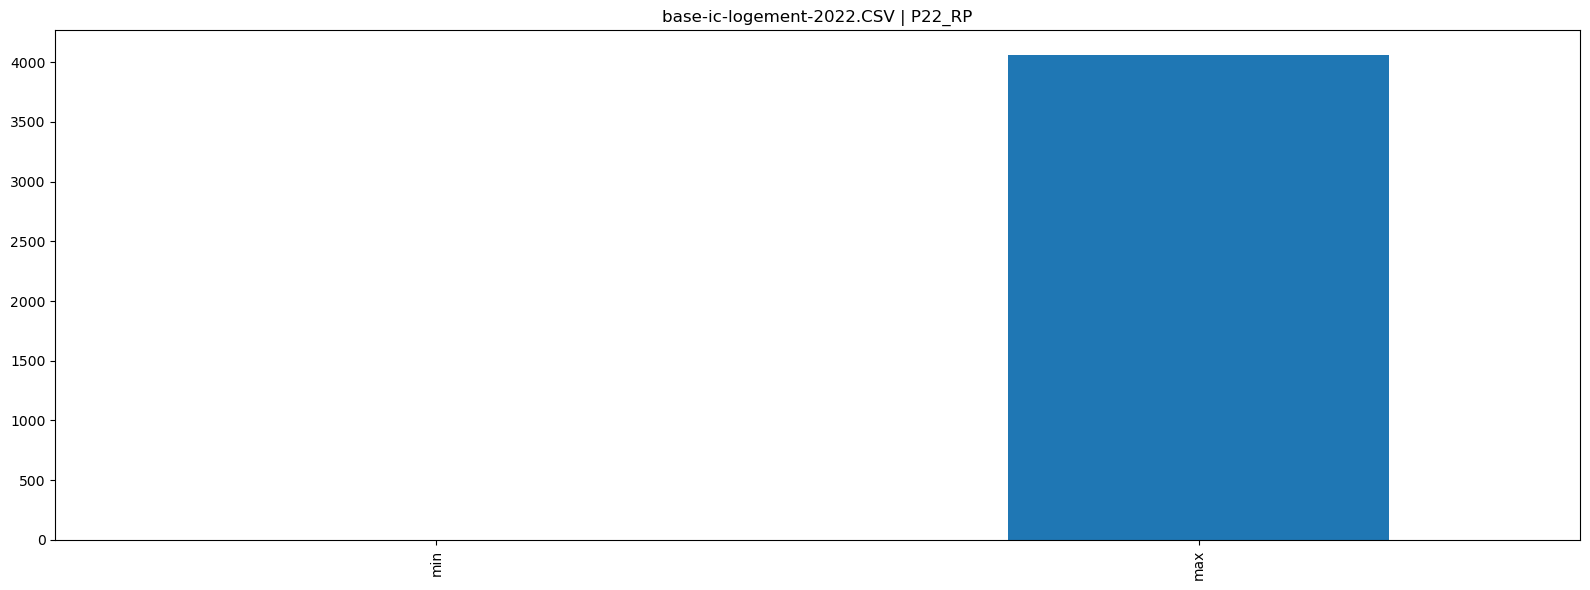

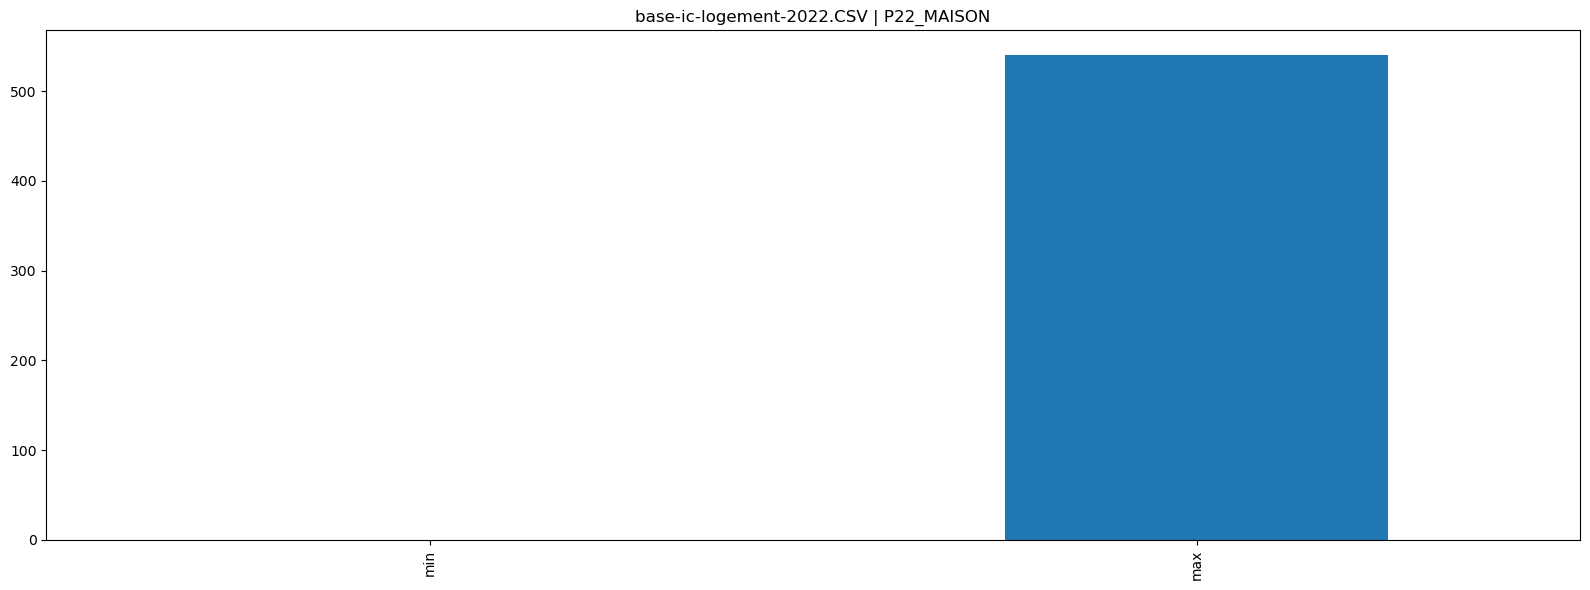

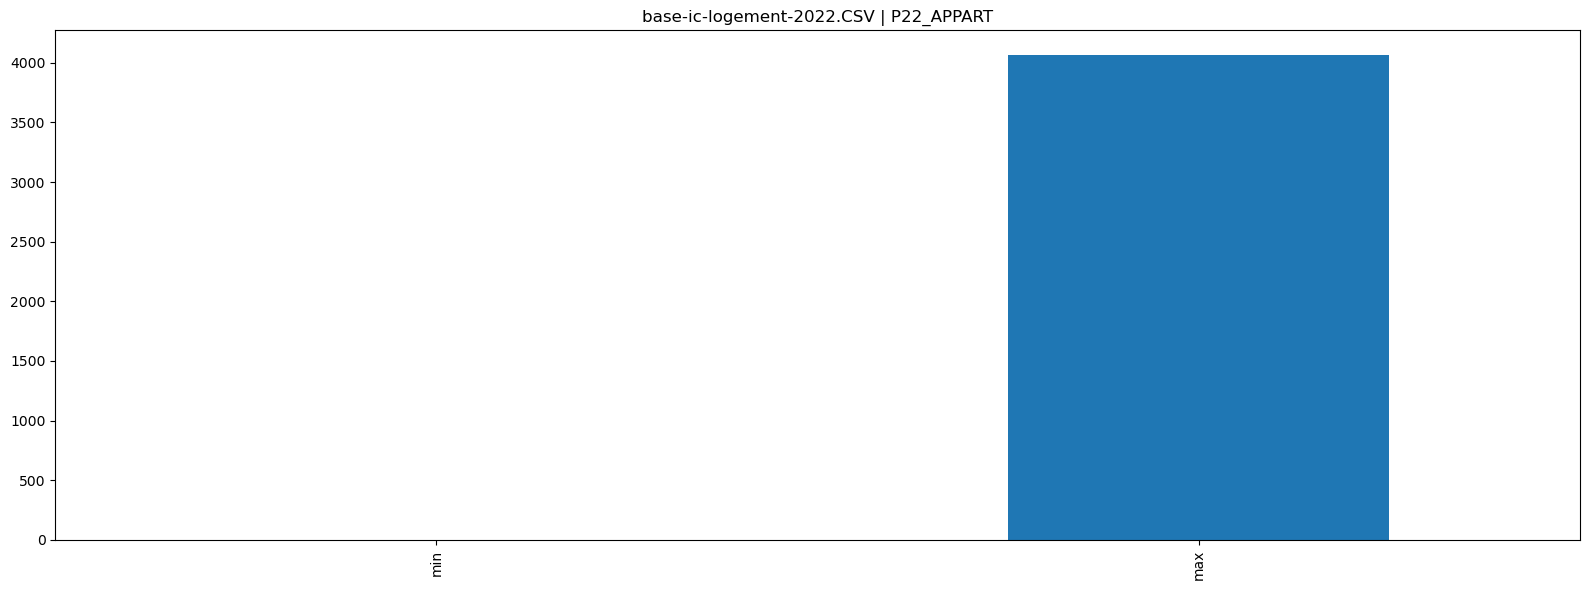

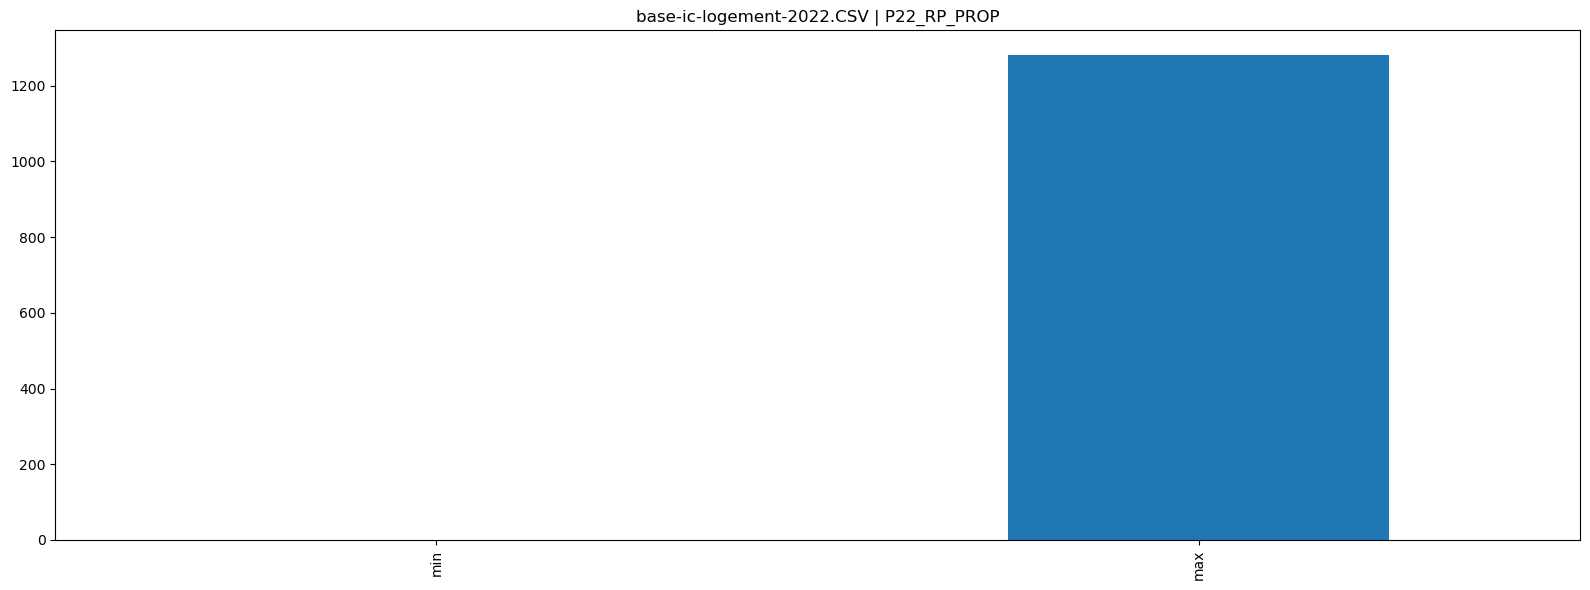

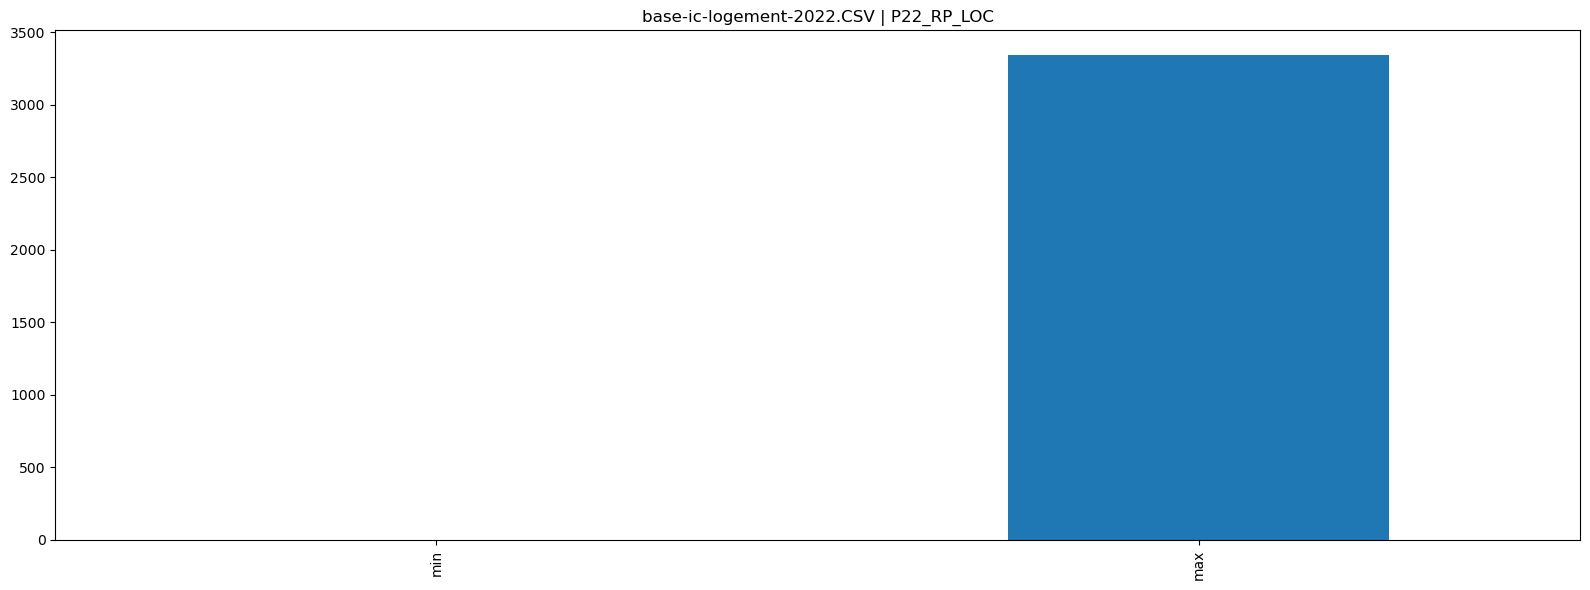

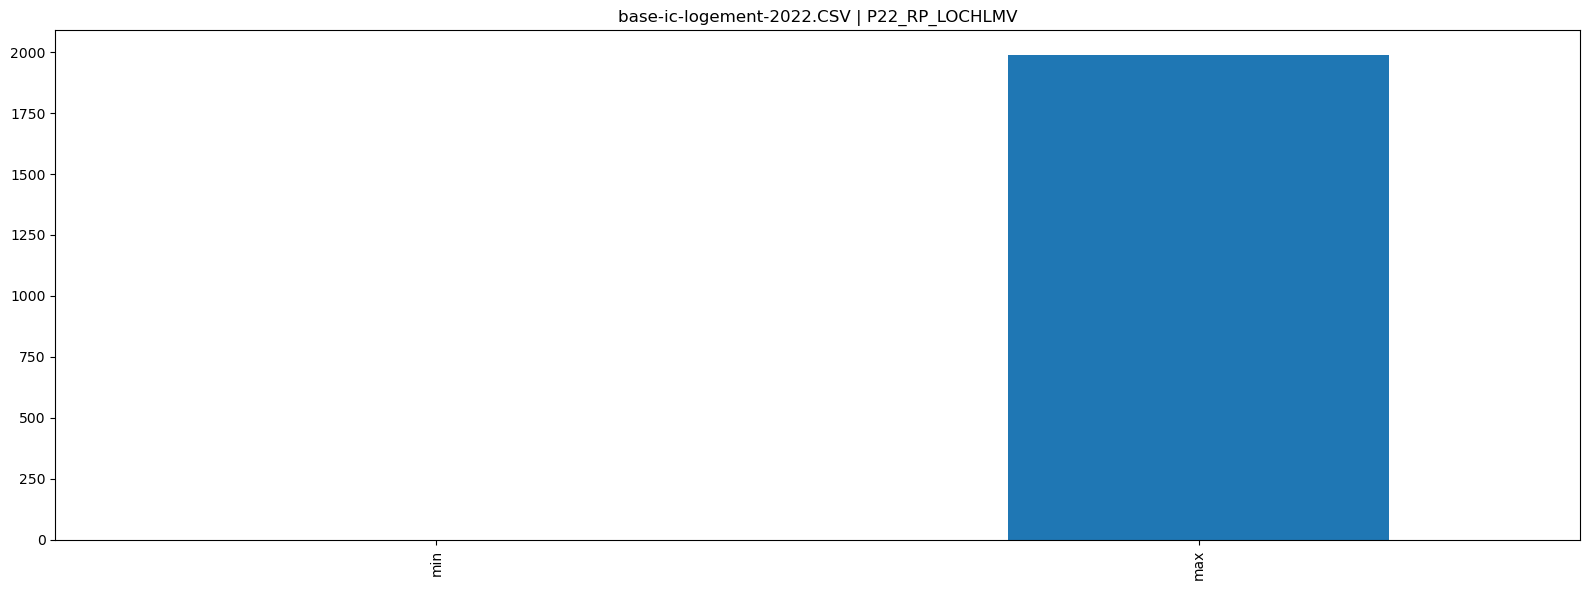

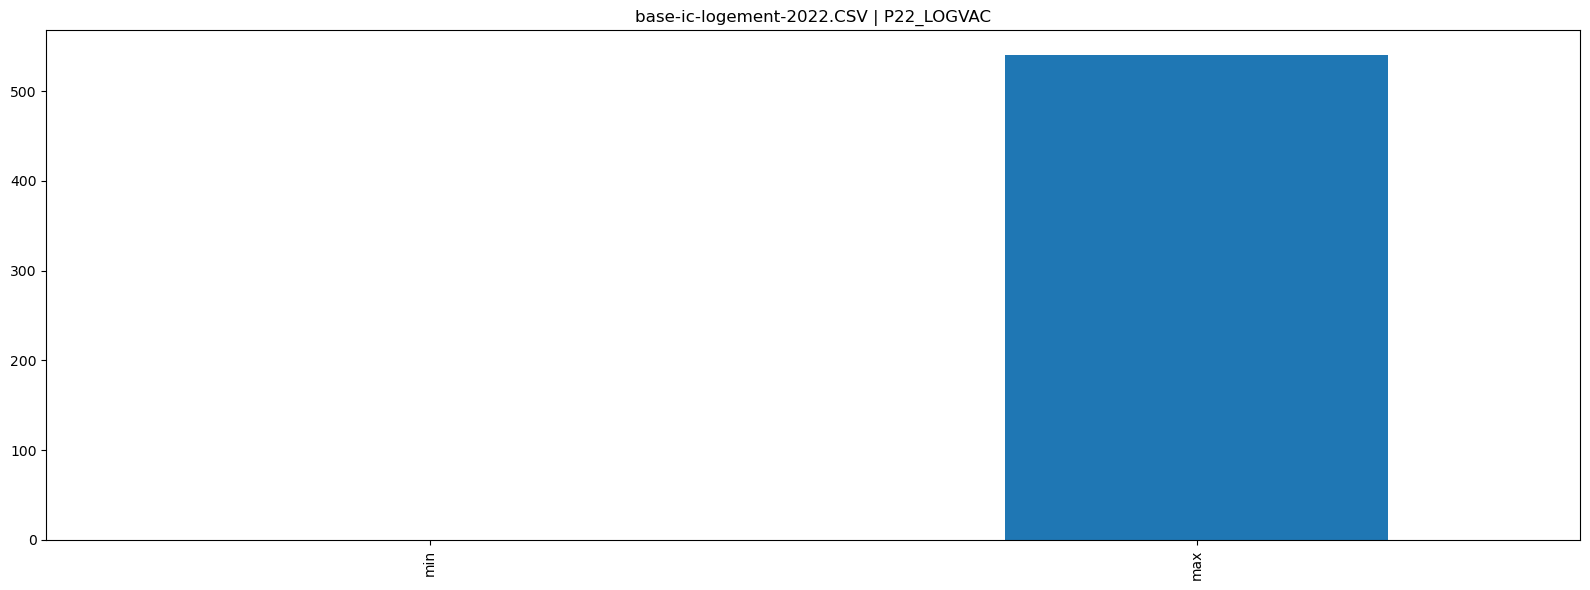

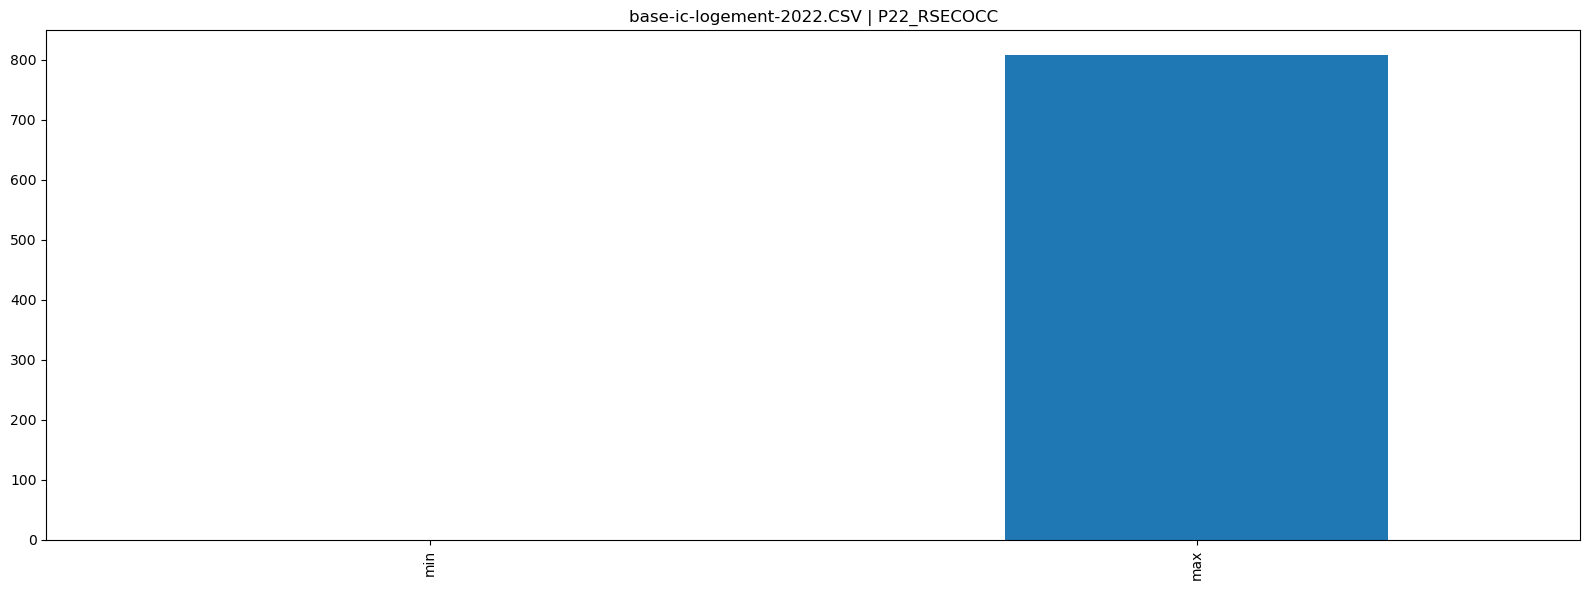

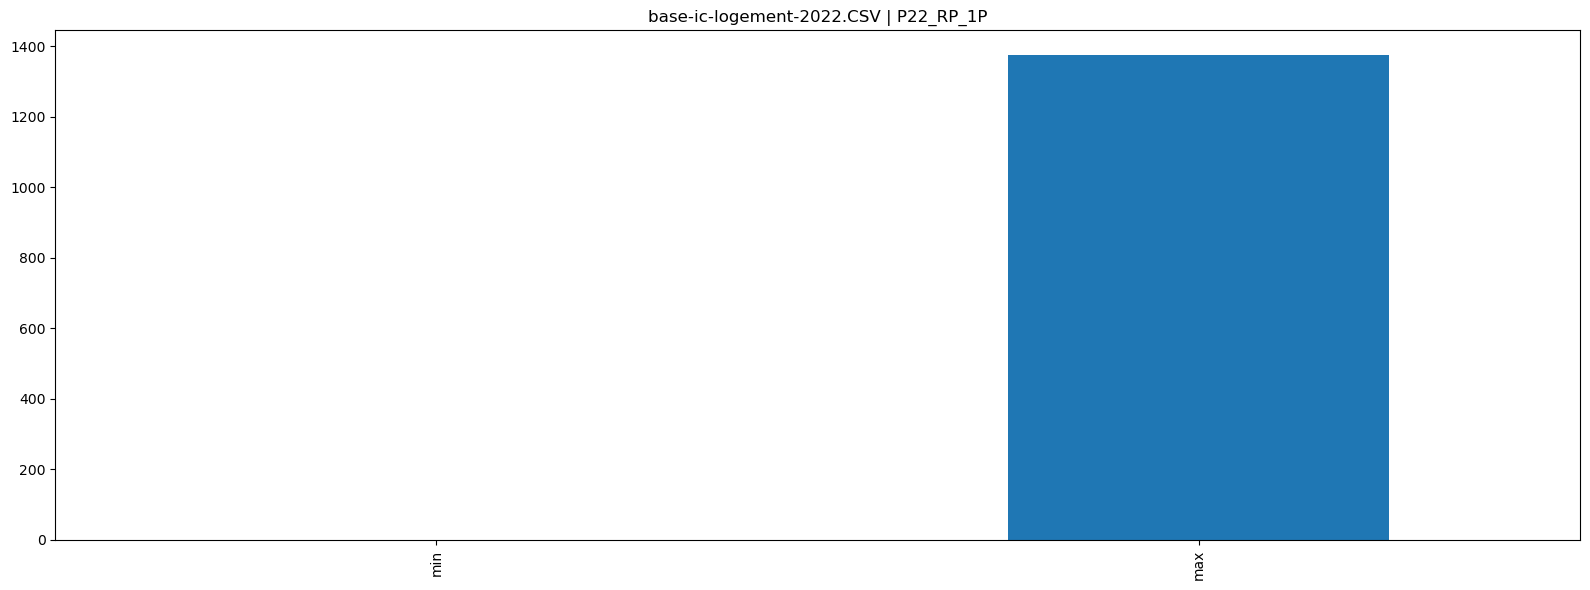

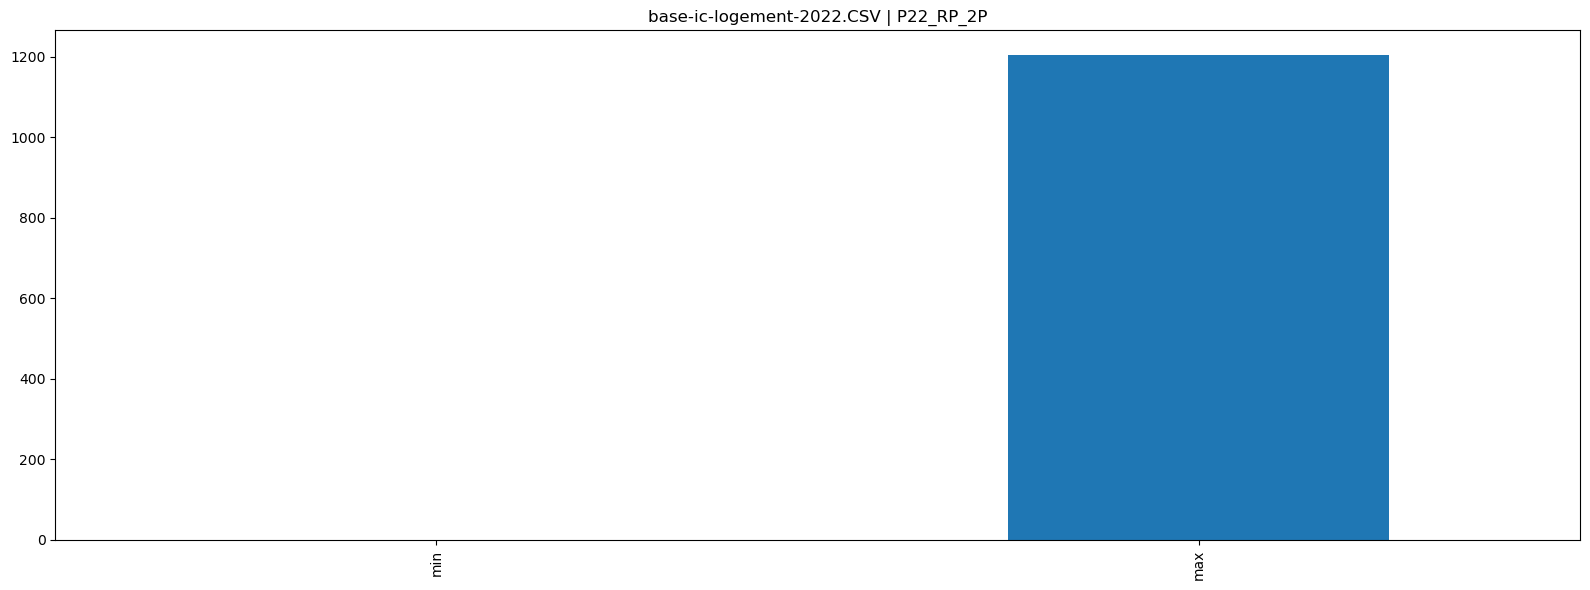

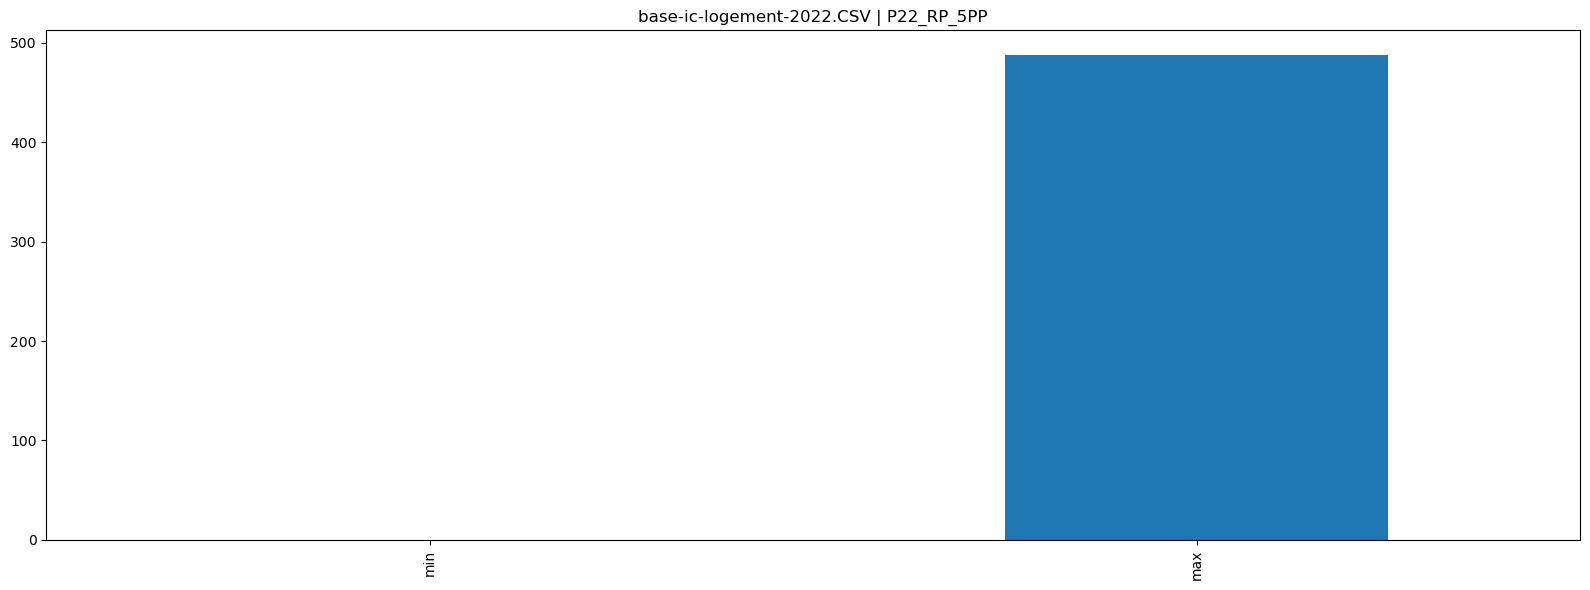

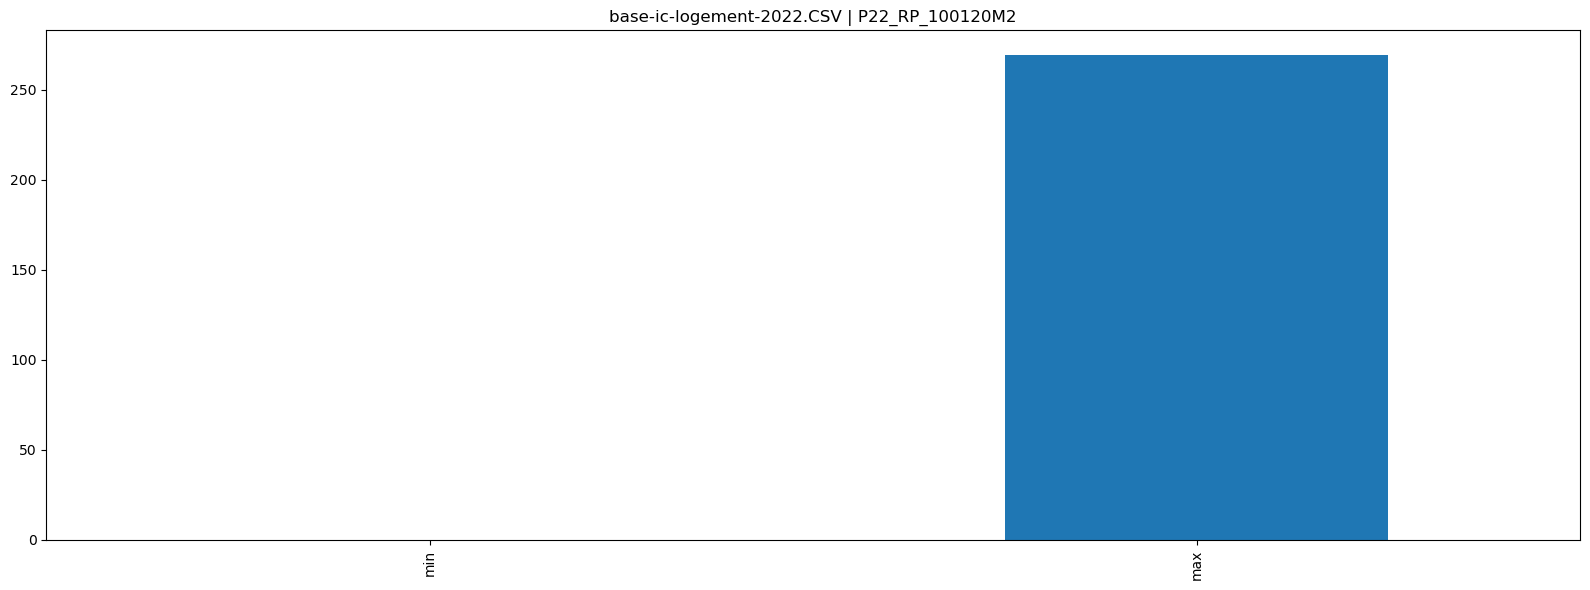

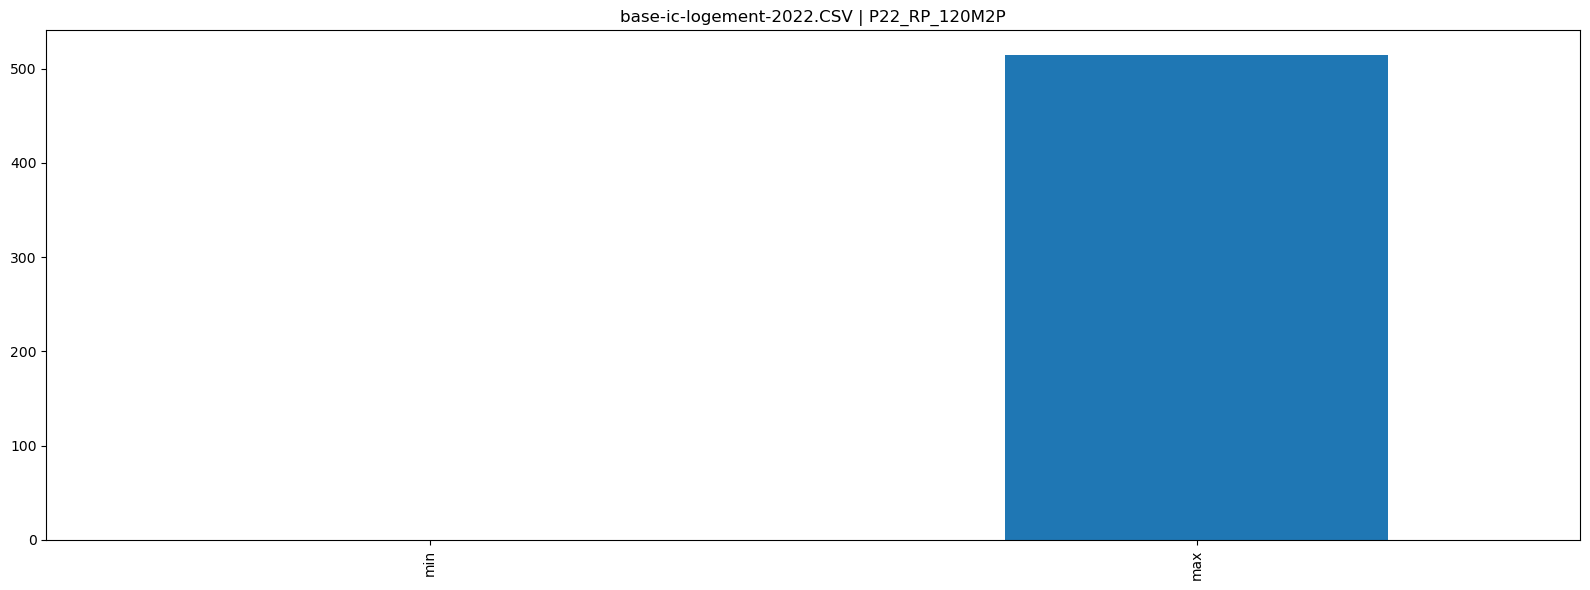

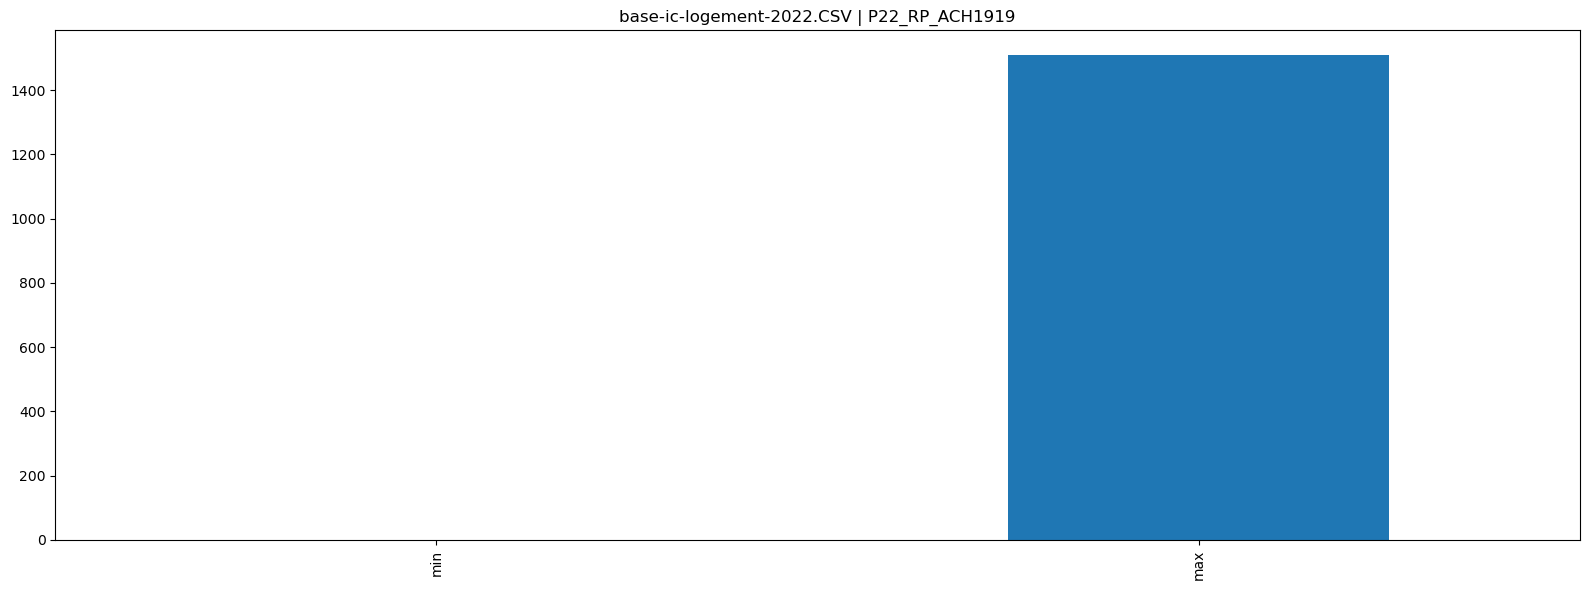

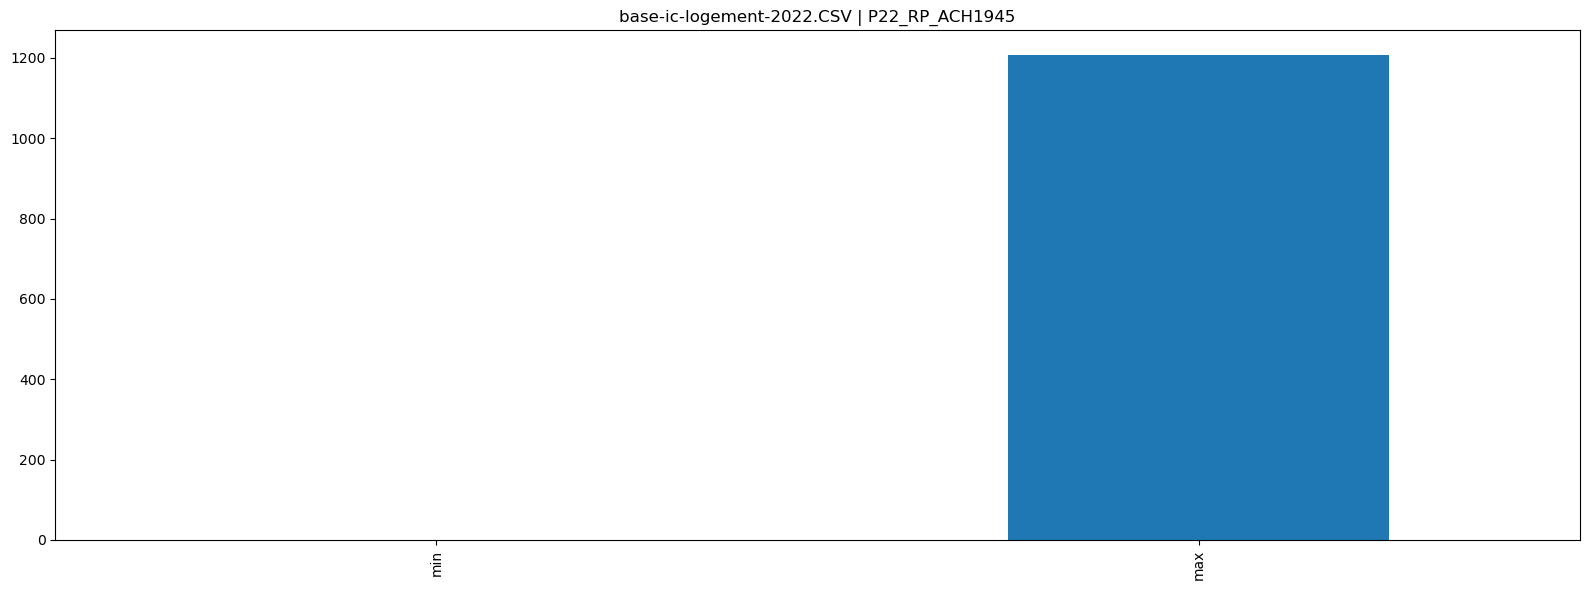

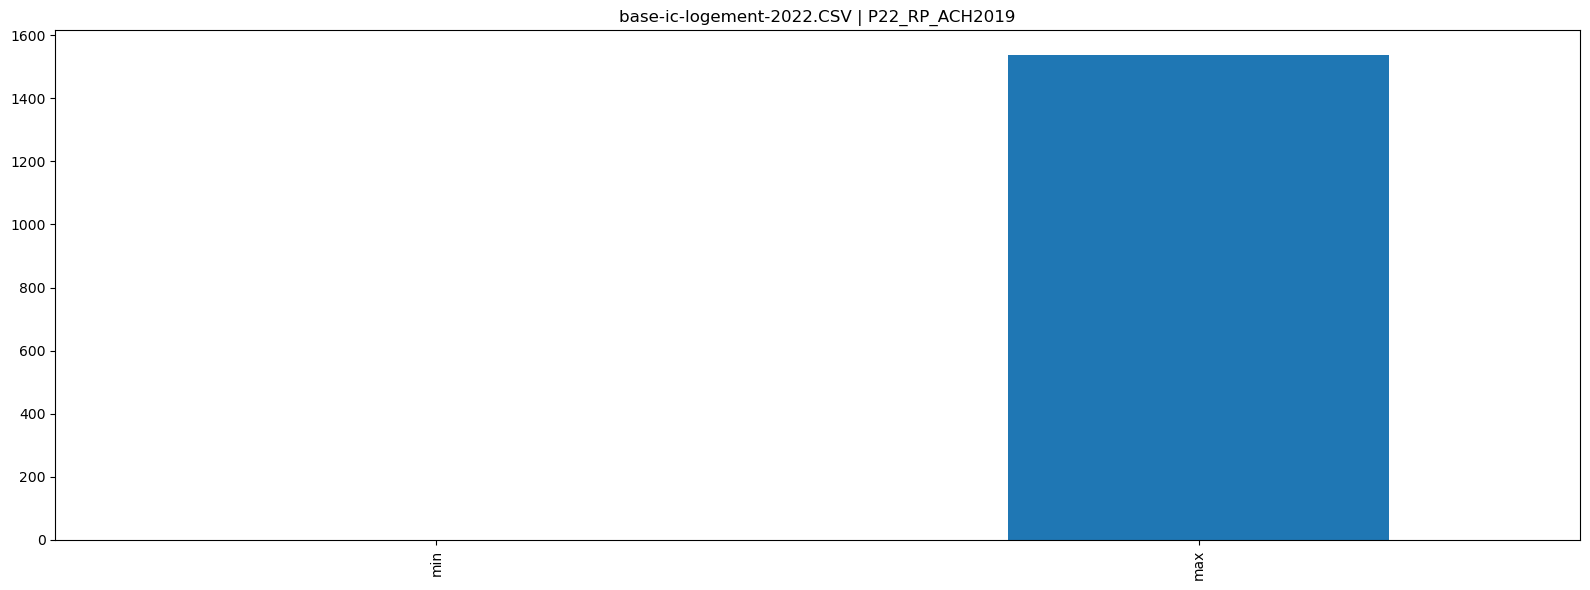

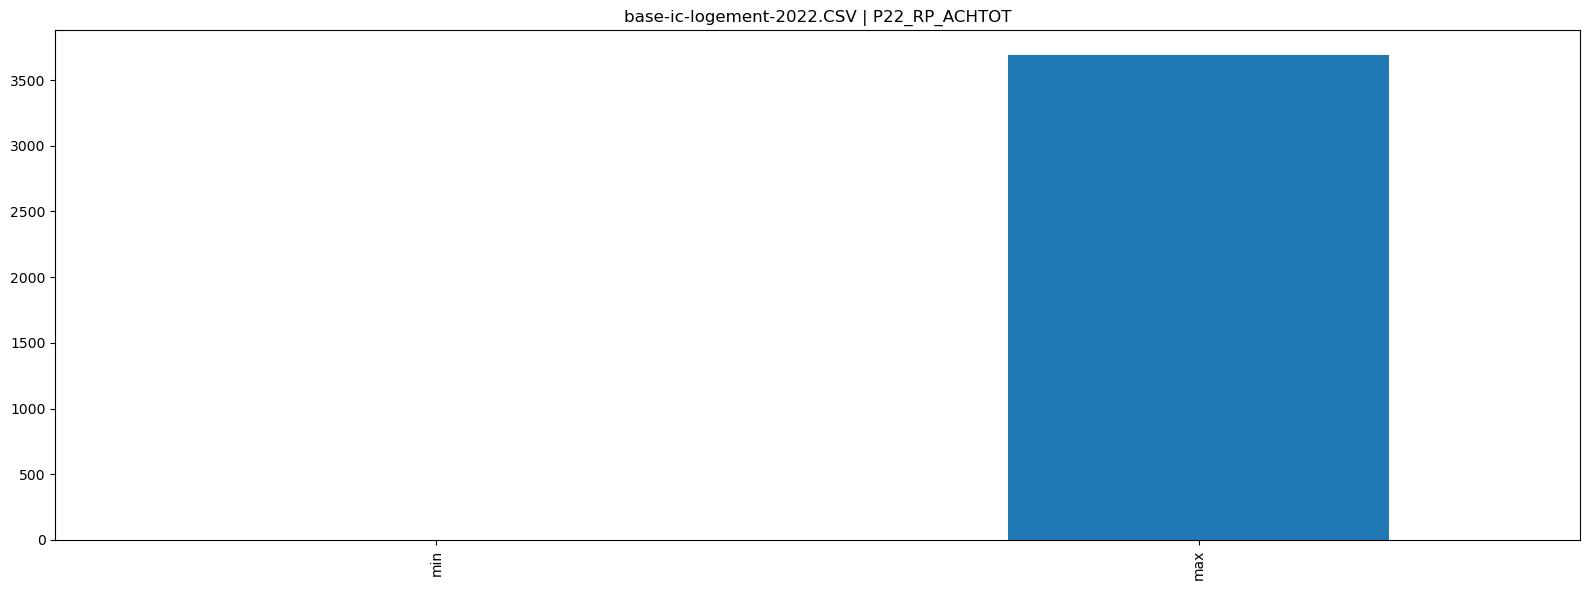

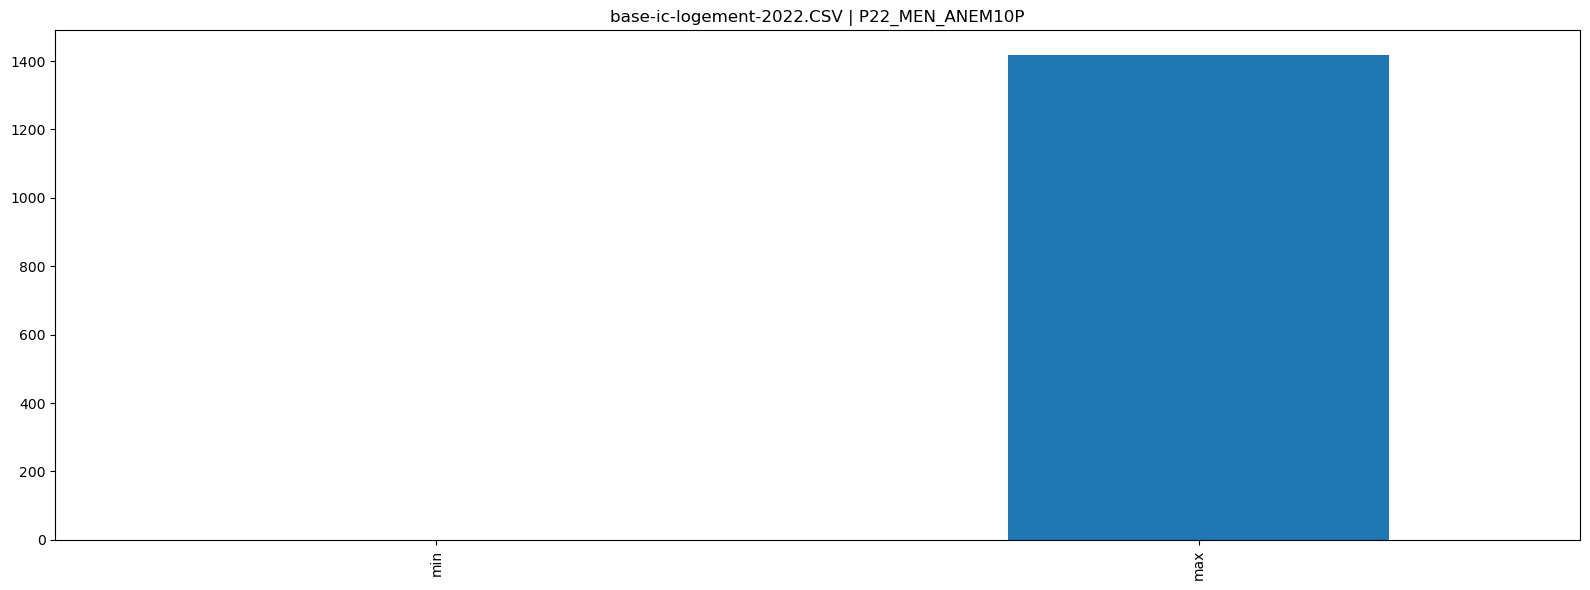

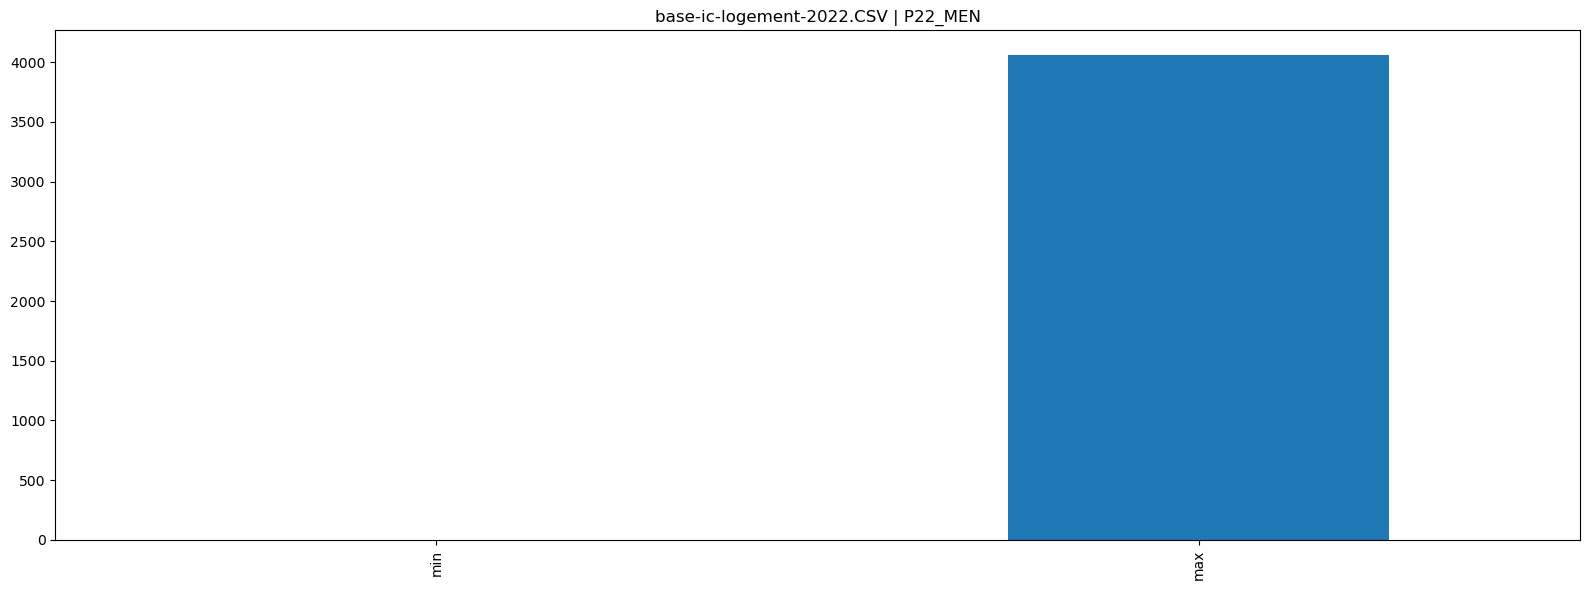

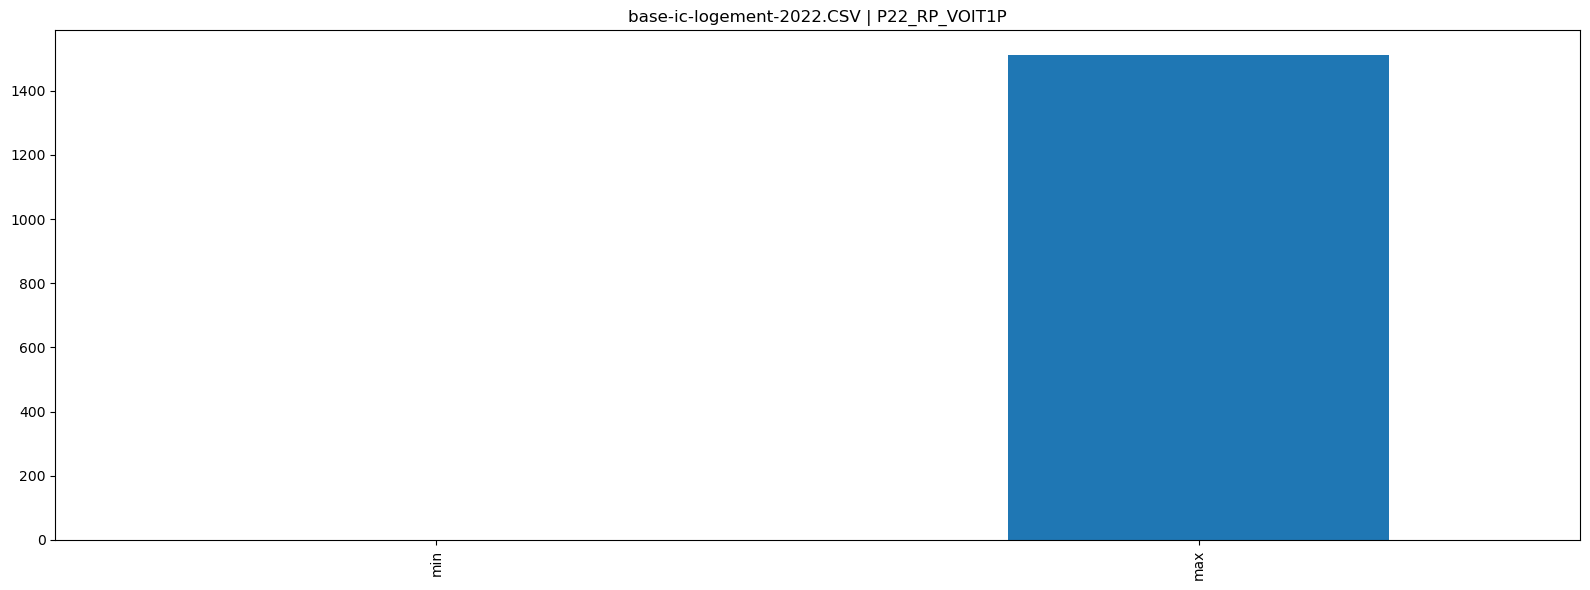

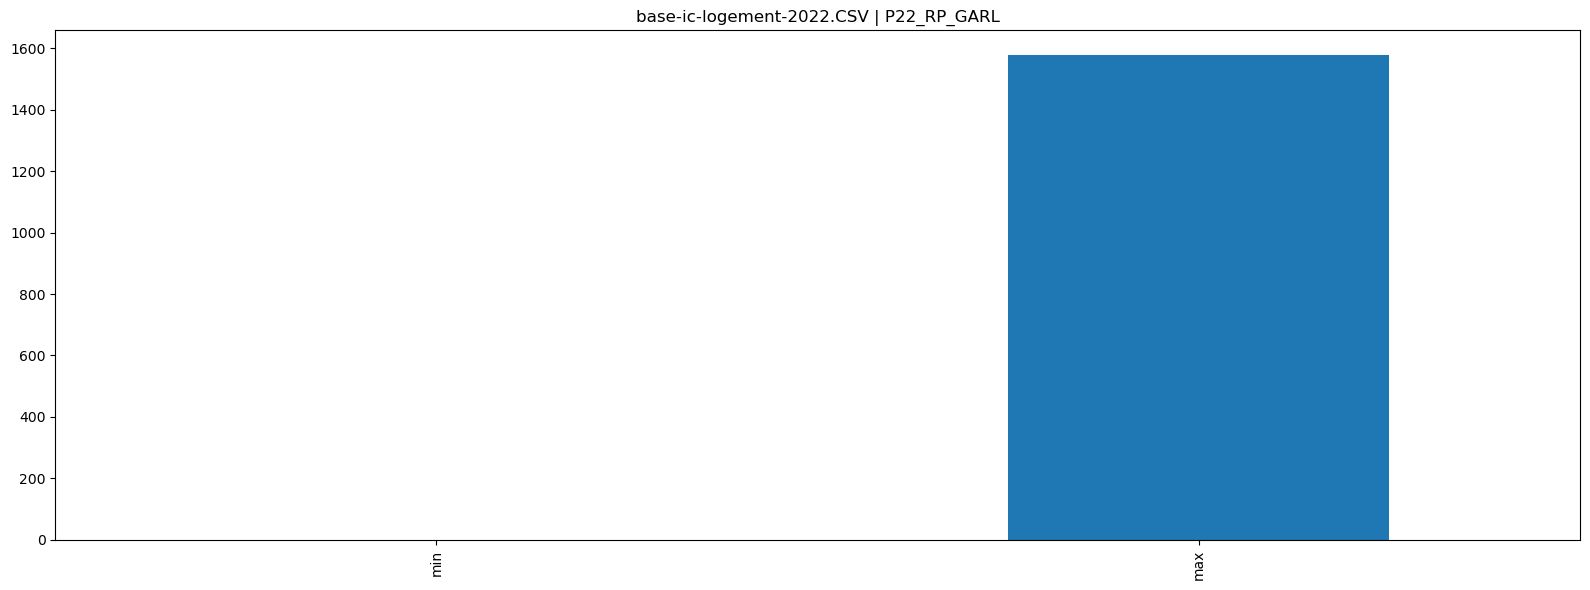

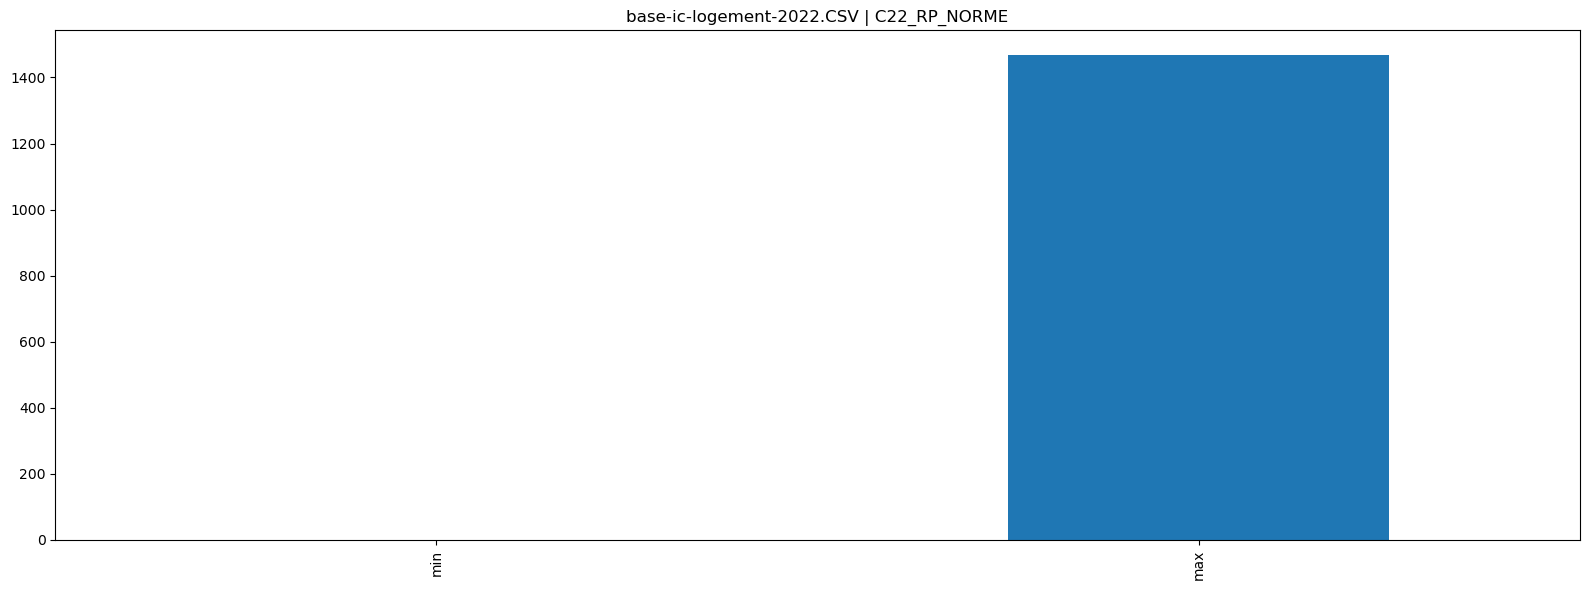

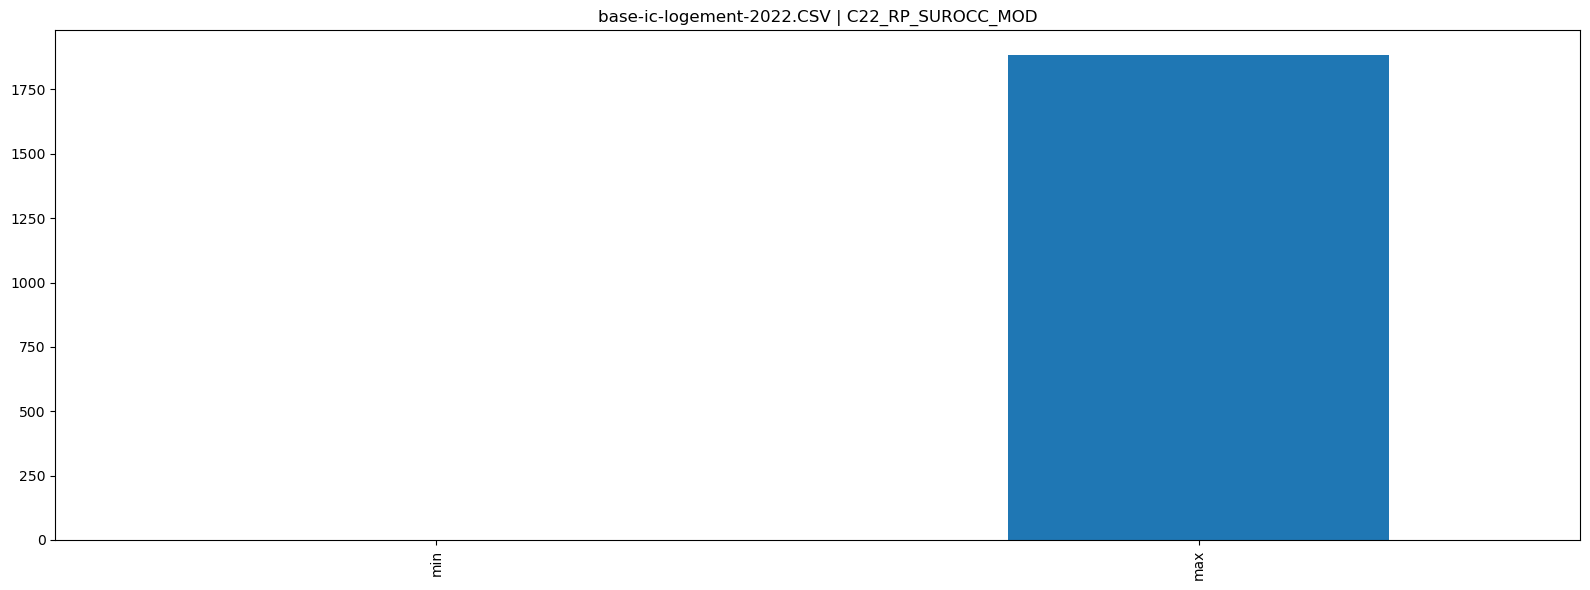

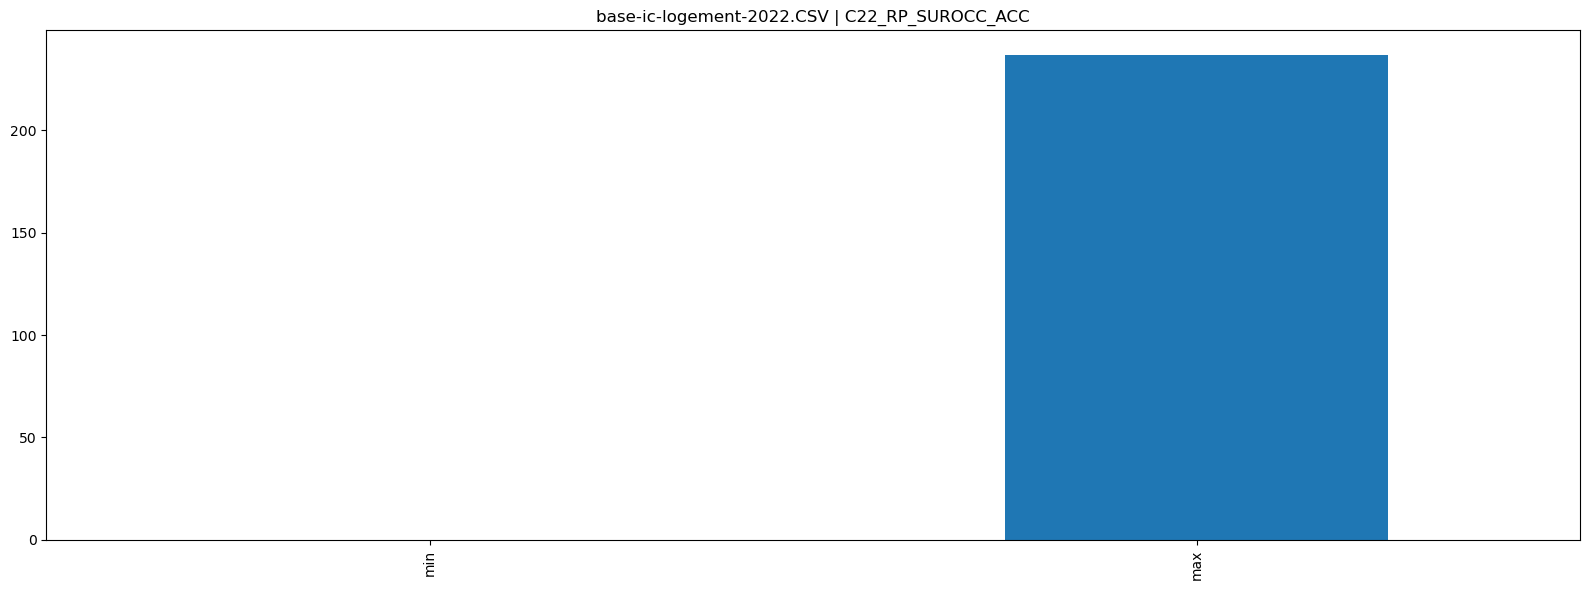

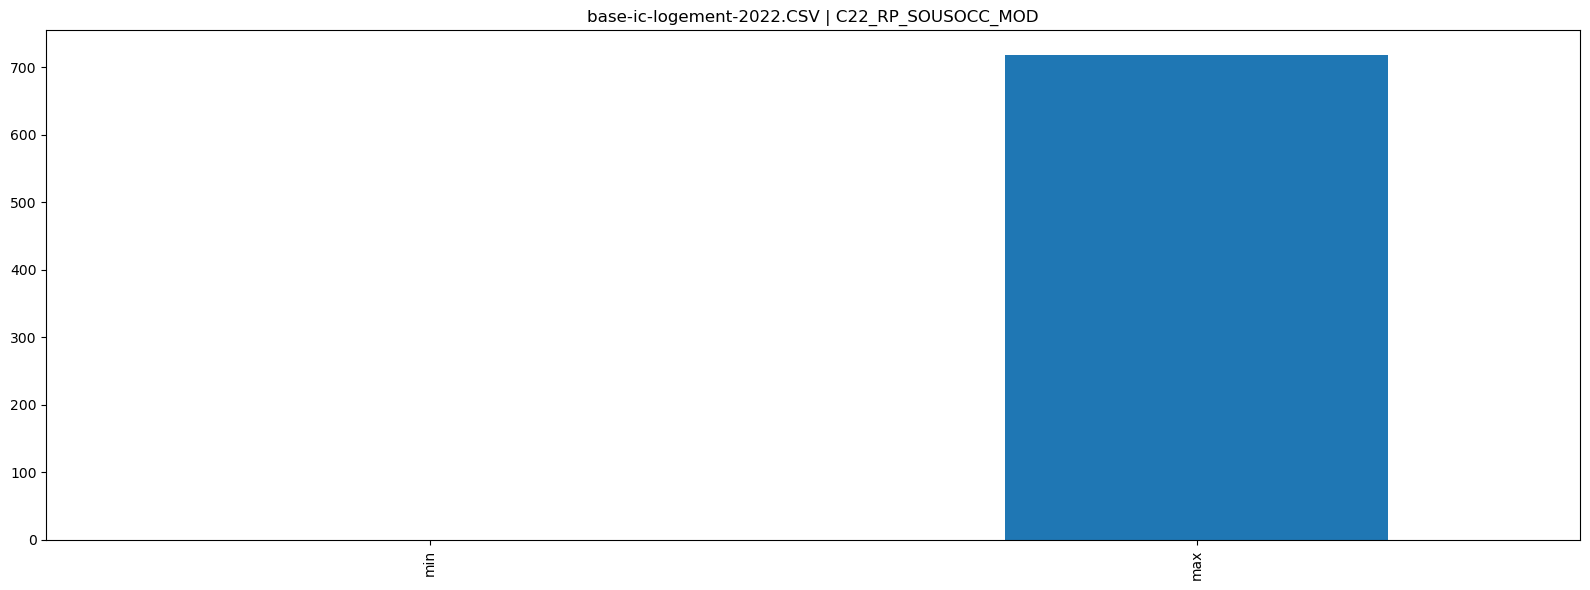

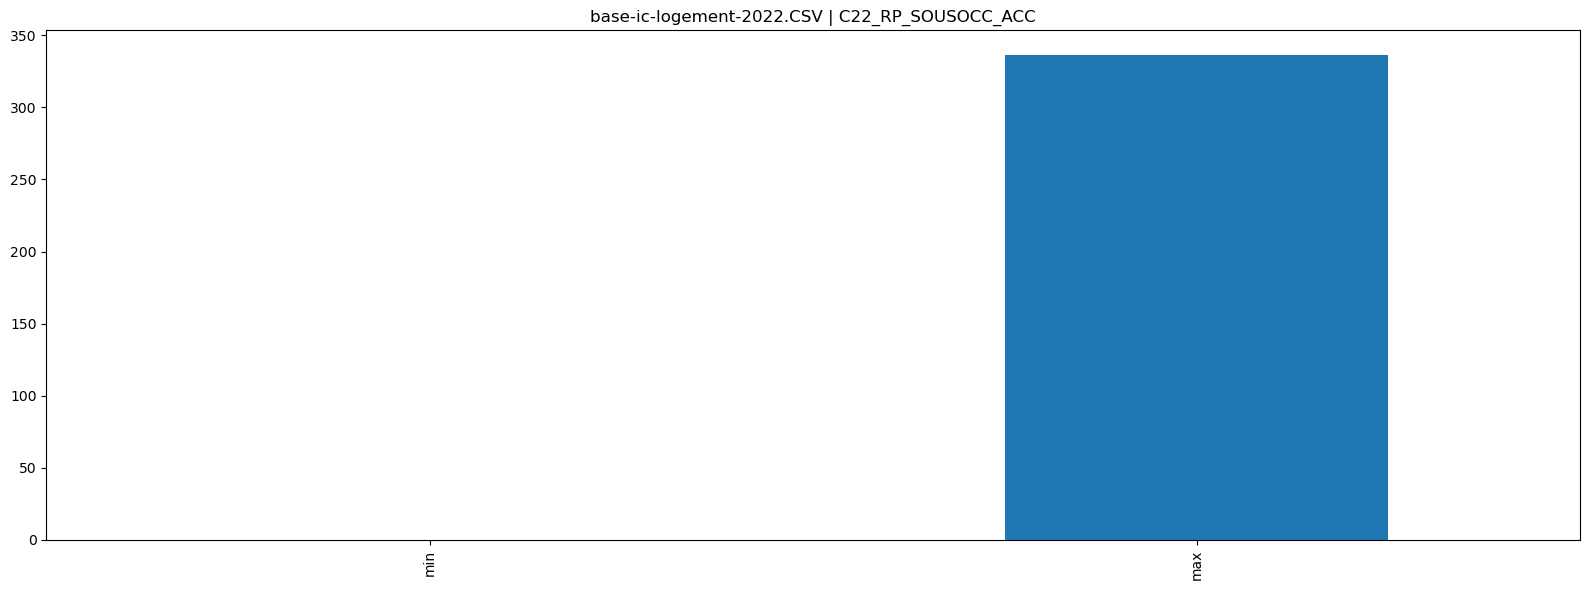

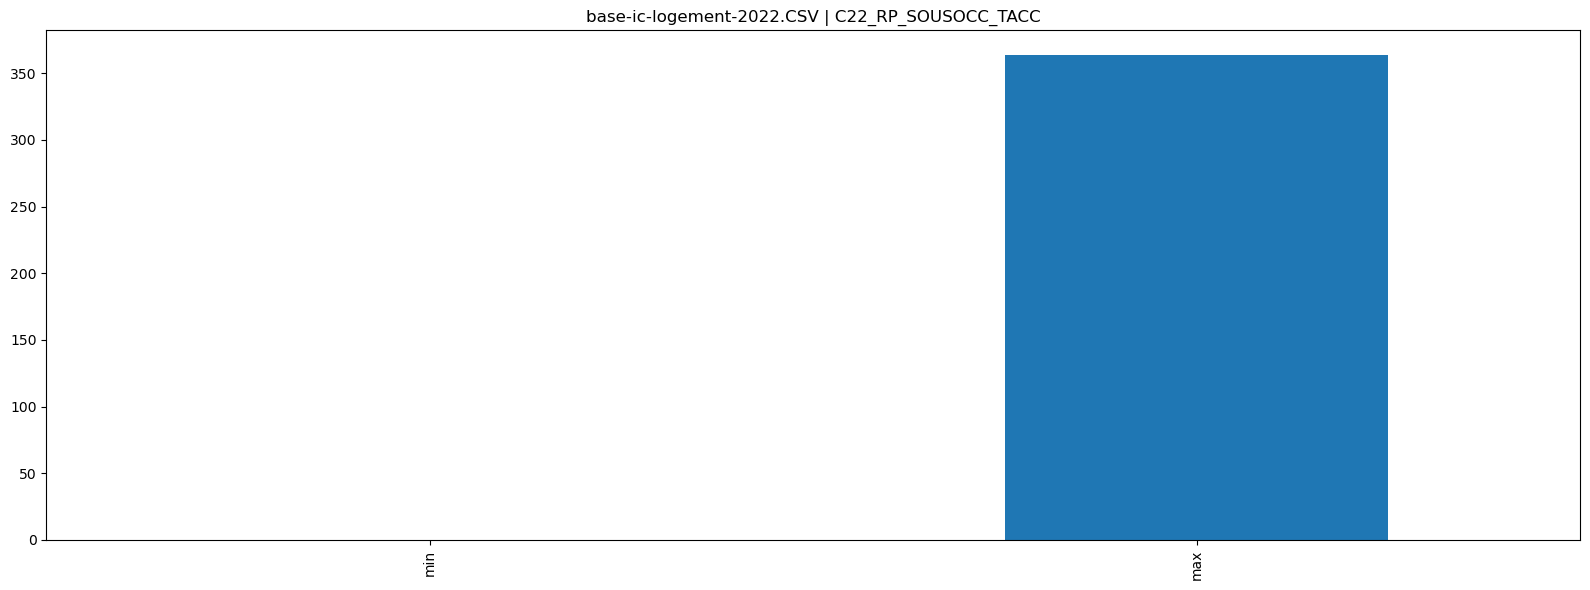

espaces_verts.parquet : 2,535 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
nom_ev,0.0,99.6,99.6,,0.0
type_ev,0.0,0.4,0.4,,0.0
categorie,0.3,1.0,0.9,,0.0
adresse_libellevoie,10.1,54.9,54.9,,0.0
adresse_codepostal,0.1,1.1,1.1,,99.9
surface_totale_reelle,22.9,39.8,,0.0,
surface_horticole,26.0,35.2,,0.2,
ouvert_ferme,65.8,0.3,0.2,,0.0
geom,0.0,100.0,100.0,,0.0


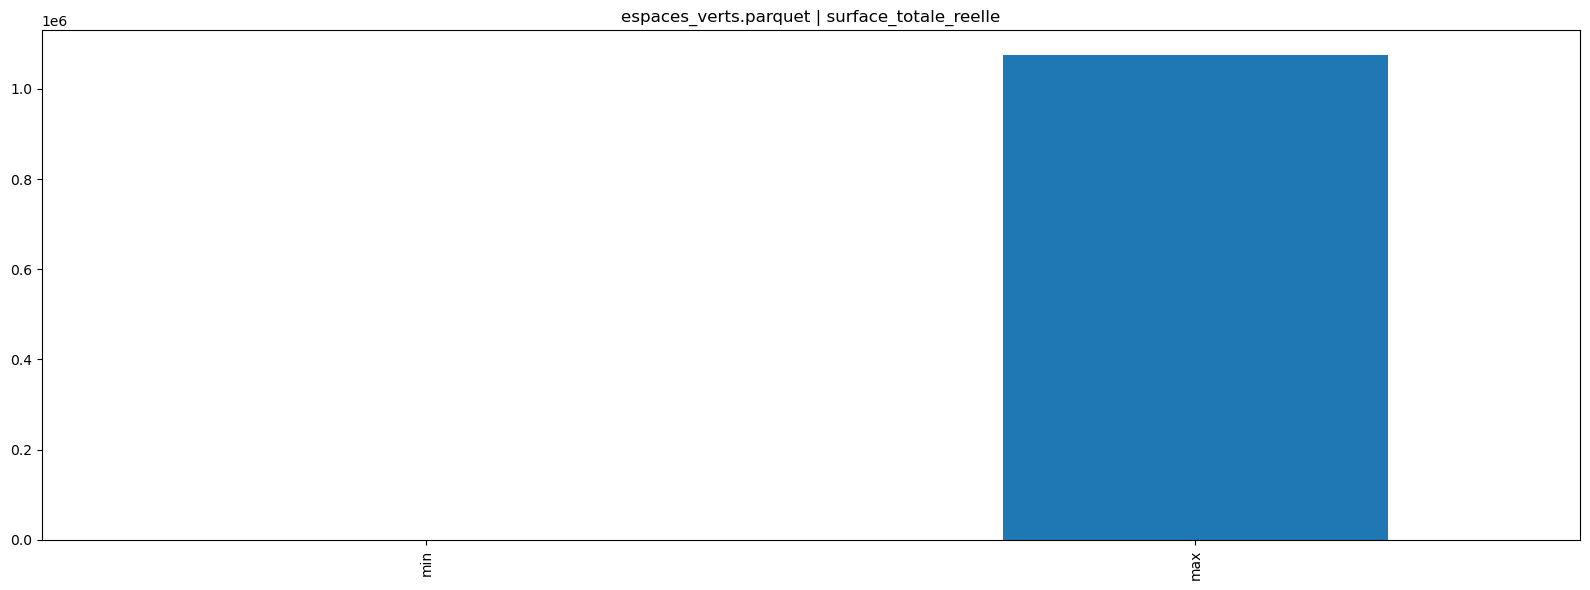

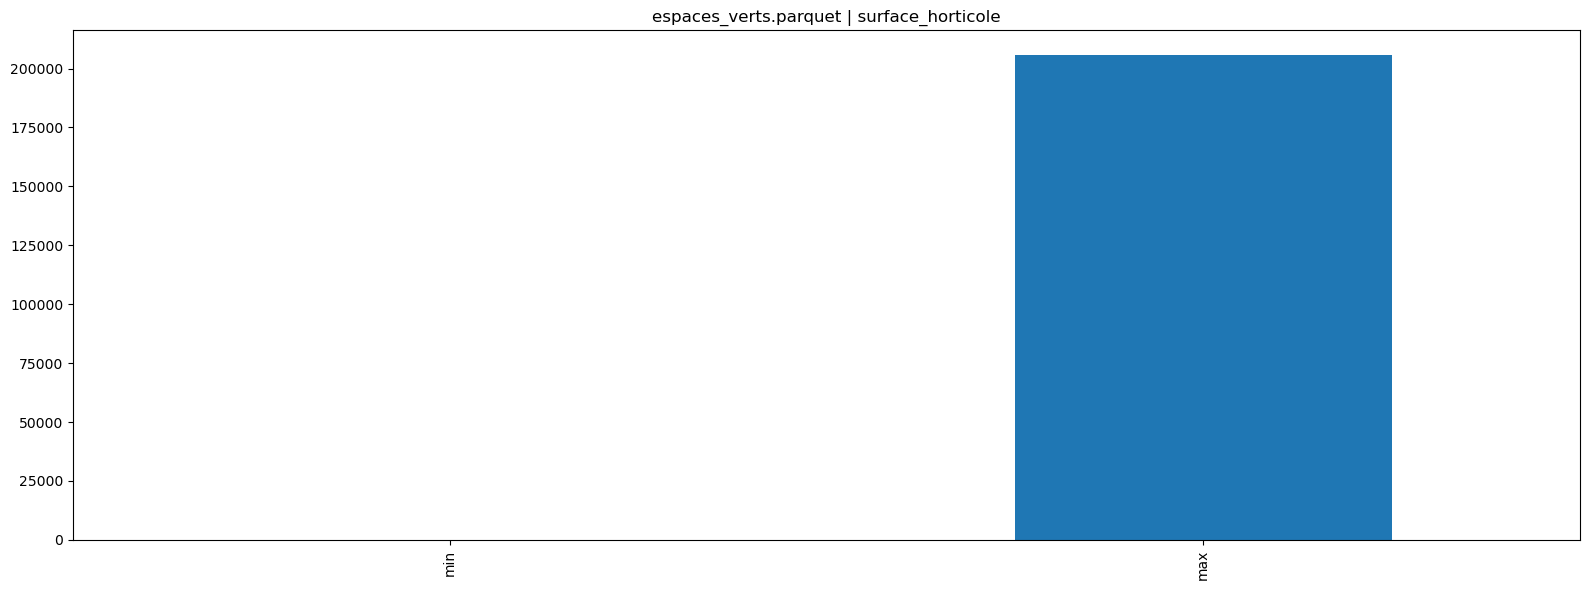

fr-en-annuaire-education.geojson : 1,459 lignes, 1 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
geometry,0.0,81.7,,,
latitude,0.0,81.7,,0.0,
longitude,0.0,81.7,,0.0,
identifiant_de_l_etablissement,0.0,99.6,,,
nom_etablissement,0.0,99.2,,,
type_etablissement,3.6,0.5,,,
statut_public_prive,3.2,0.1,,,
appartenance_education_prioritaire,83.6,0.1,,,
libelle_departement,0.0,0.1,,,
code_commune,0.0,1.4,,,


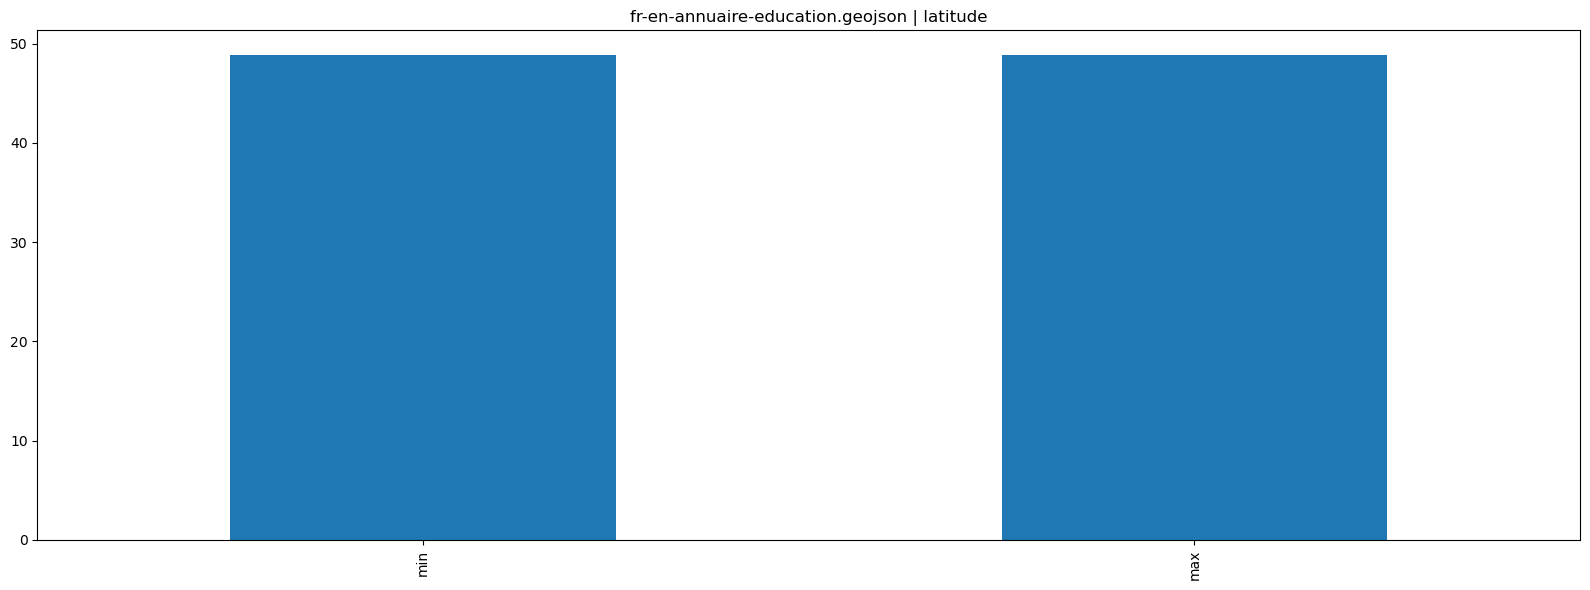

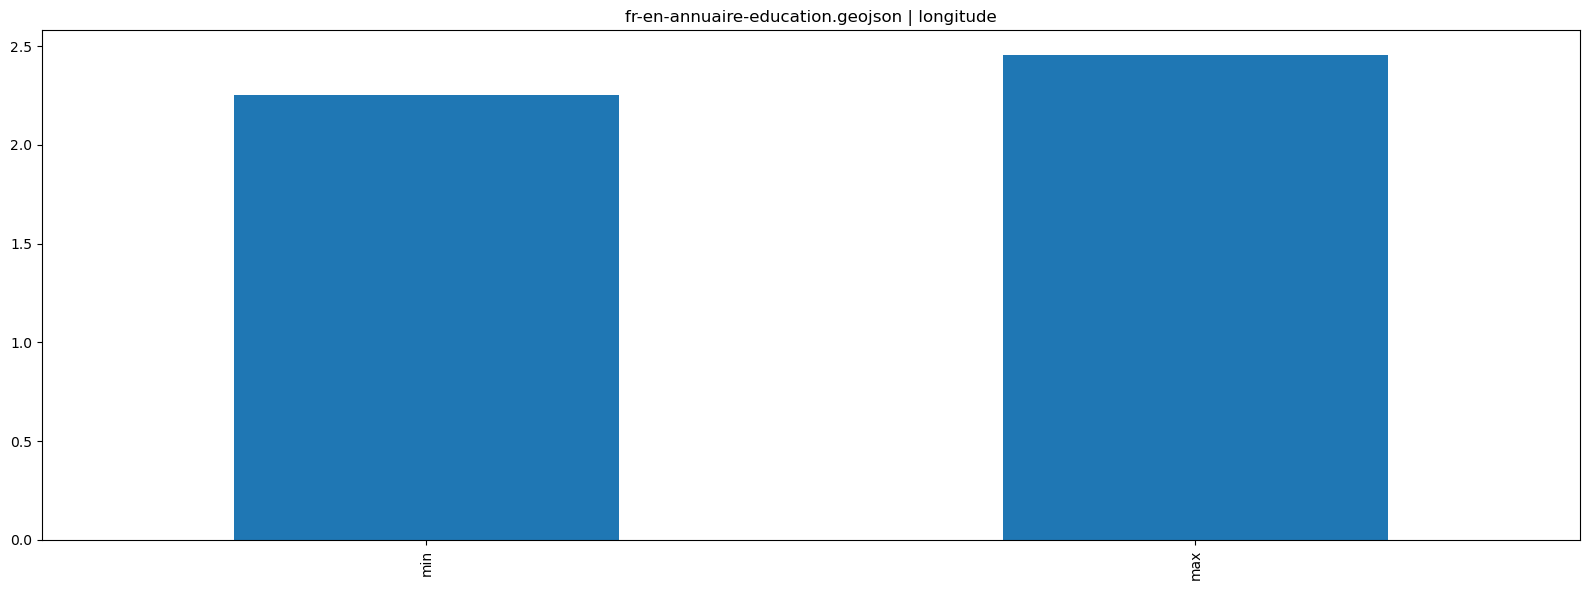

fr-en-indicateurs-valeur-ajoutee-colleges.csv : 672 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
Session,0.0,0.6,,0.0,
UAI,0.0,25.6,,,
Département,0.0,0.1,,,
Taux de réussite G,0.0,6.0,,0.0,
VA du taux de réussite G,7.7,4.8,,11.8,
Note à l'écrit G,0.0,14.1,,0.0,
Taux d'accès 6eme 3eme,0.4,5.4,,0.0,


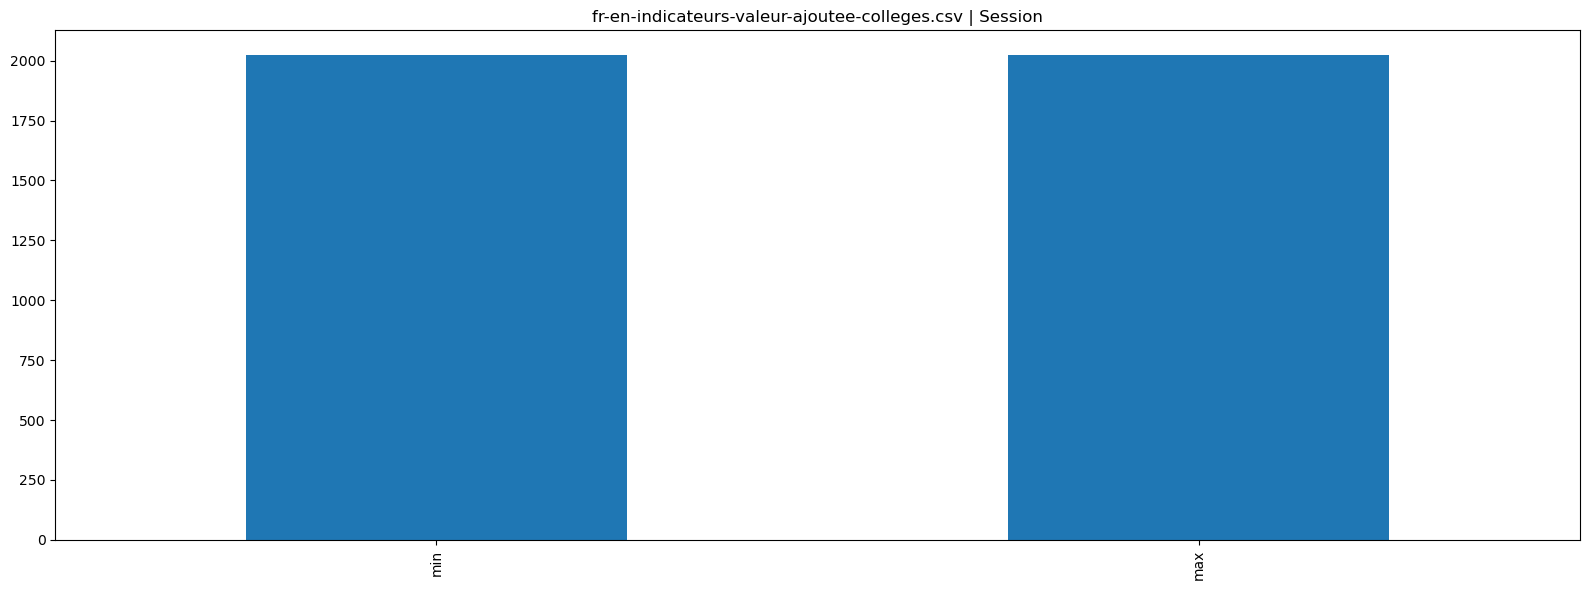

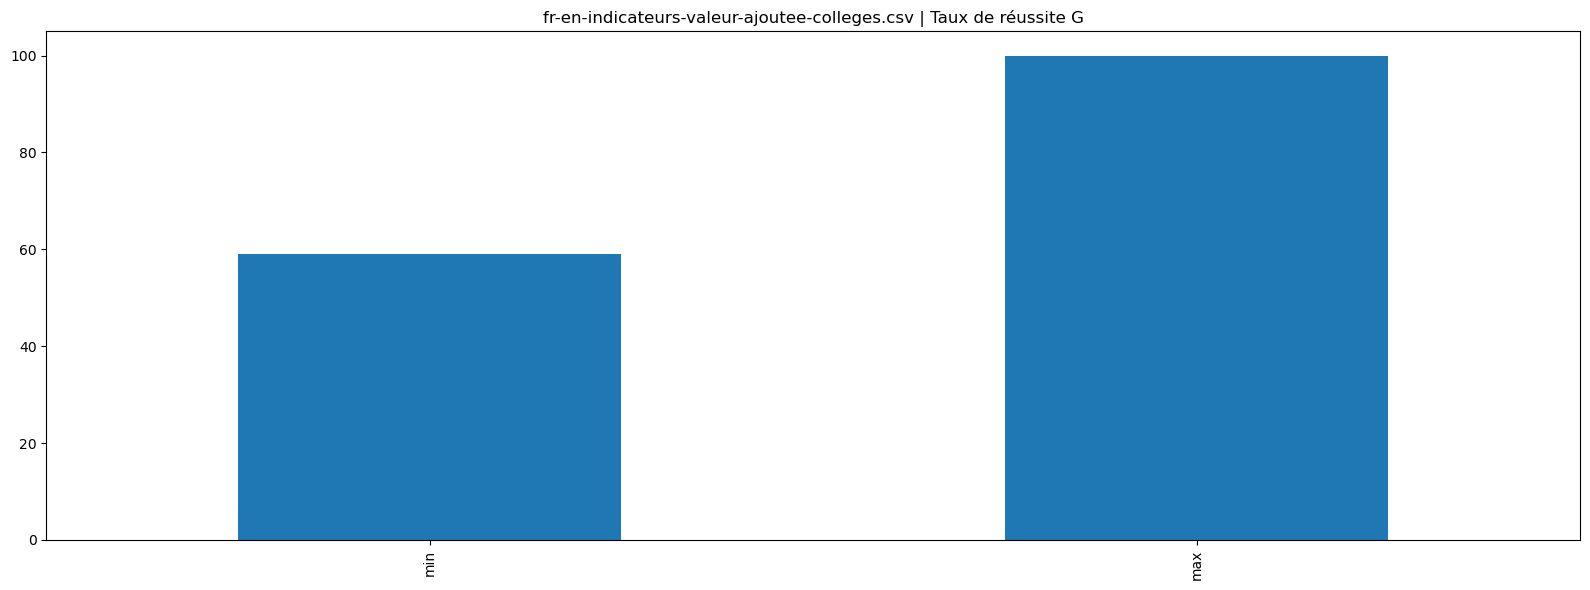

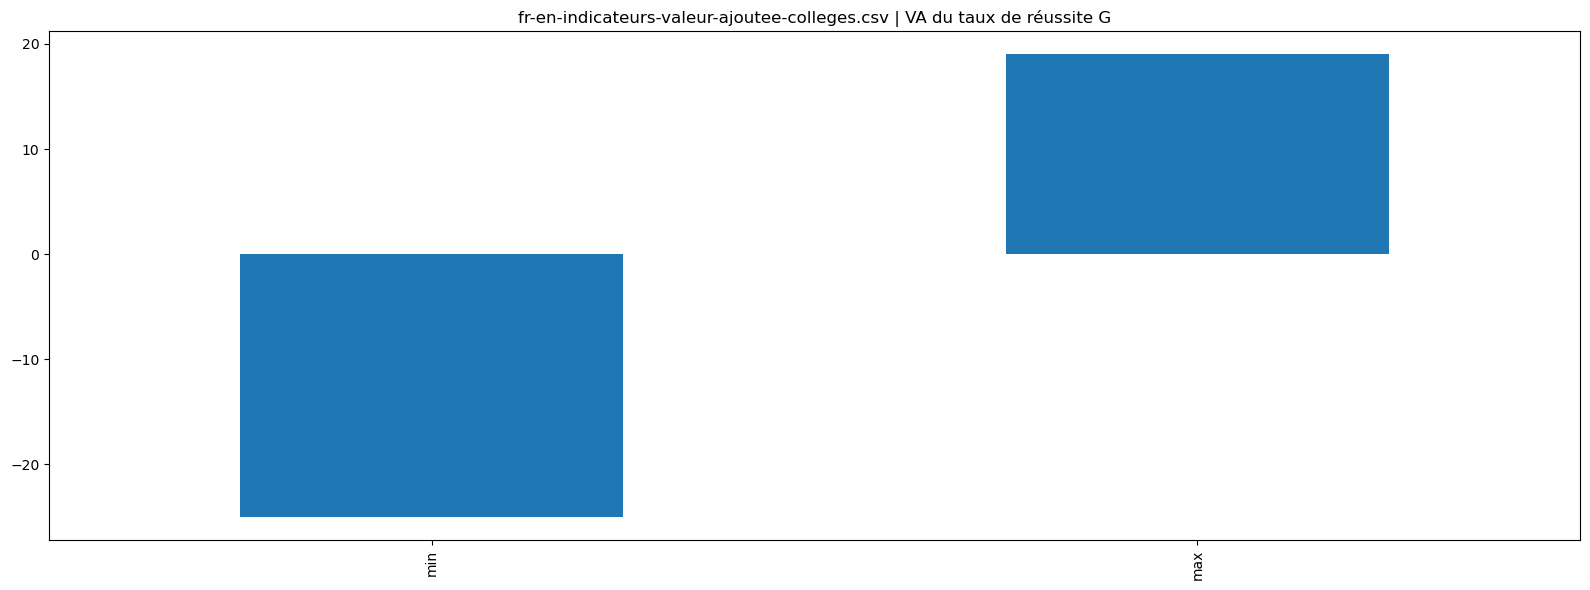

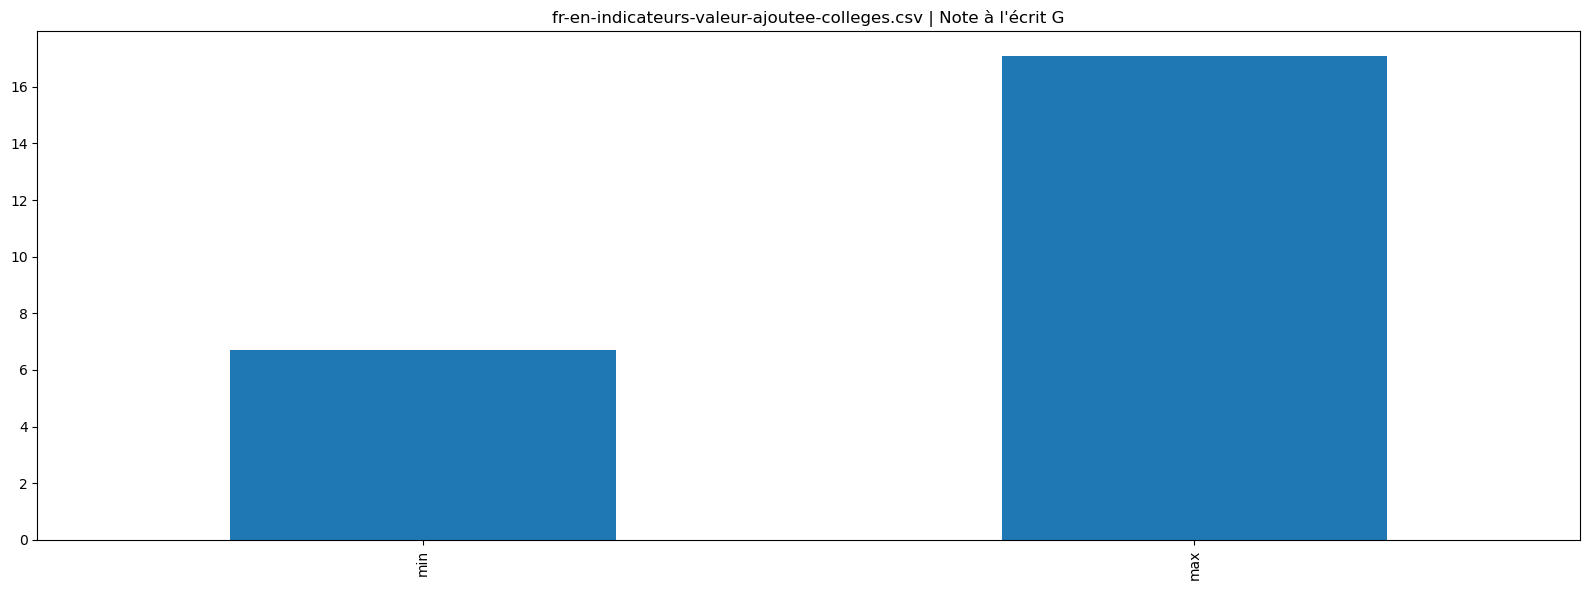

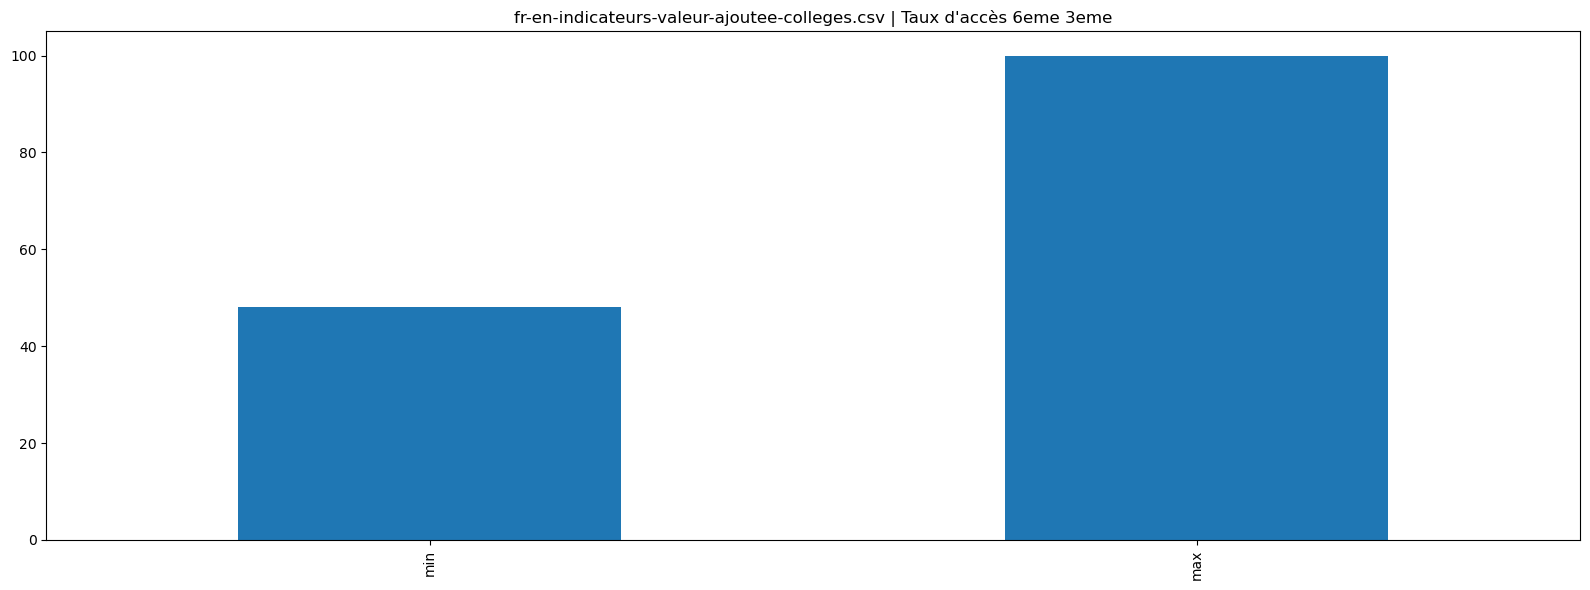

fr-en-ips-ecoles-ap2022.csv : 1,367 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
UAI,0.0,33.9,,,
Département,0.0,0.1,,,
Rentrée scolaire,0.0,0.2,,,
IPS,0.0,43.7,,,


fr-en-ips-lycees-ap2023.csv : 474 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
UAI,0.0,33.3,,,
Département,0.0,0.2,,,
Rentrée scolaire,0.0,0.6,,,
IPS de l'établissement,0.2,73.4,,0.0,


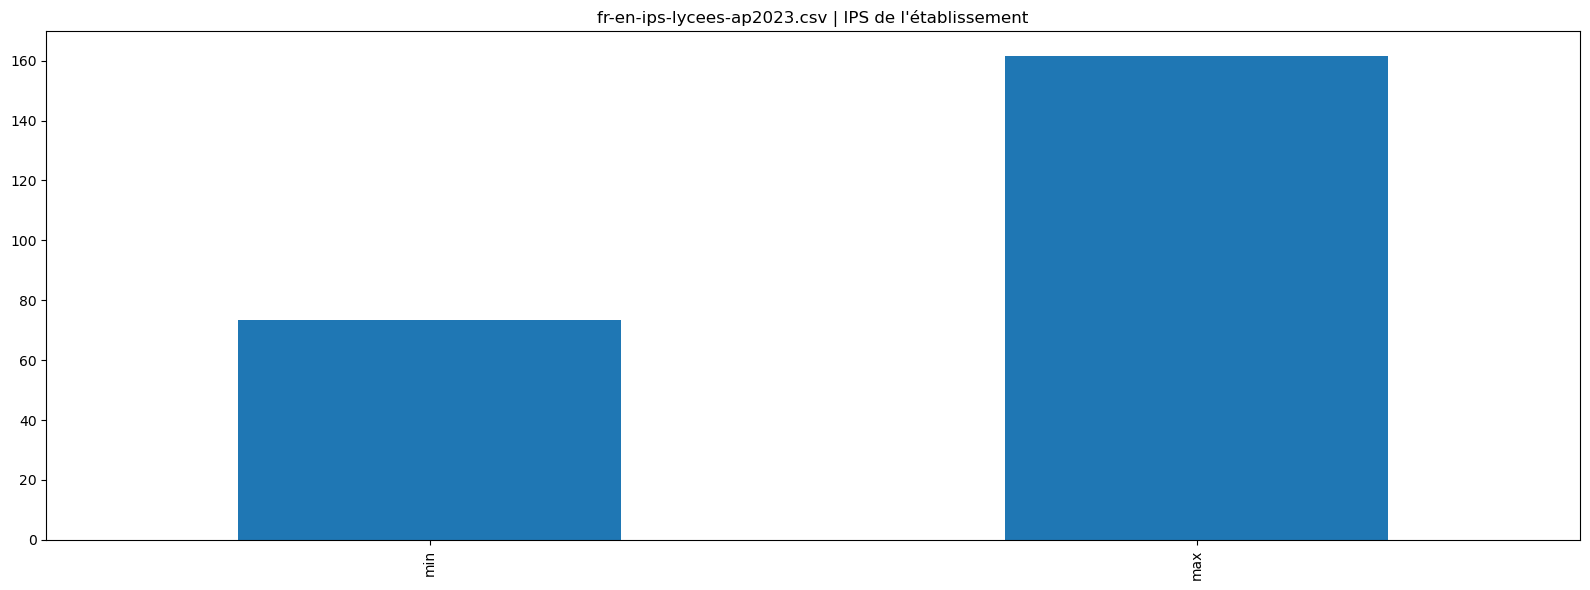

full-2025.csv : 86,190 lignes, 15,961 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
latitude,0.0,25.1,,0.0,
longitude,0.0,25.0,,0.0,
id_mutation,0.0,49.5,,,
date_mutation,0.0,0.3,,,
nature_mutation,0.0,0.0,,,
valeur_fonciere,1.2,13.5,,0.0,
type_local,0.7,0.0,,,
surface_reelle_bati,0.7,0.8,,48.1,
nombre_pieces_principales,0.7,0.0,,54.4,
code_commune,0.0,0.0,,,


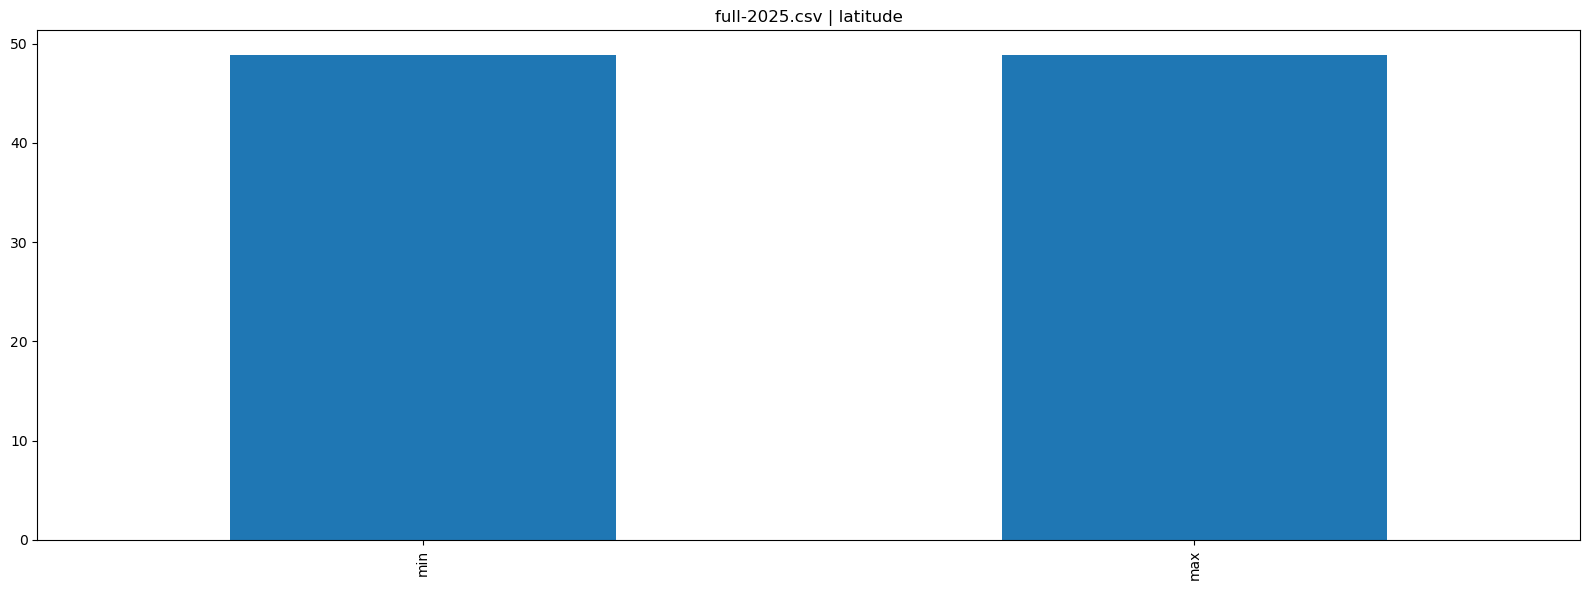

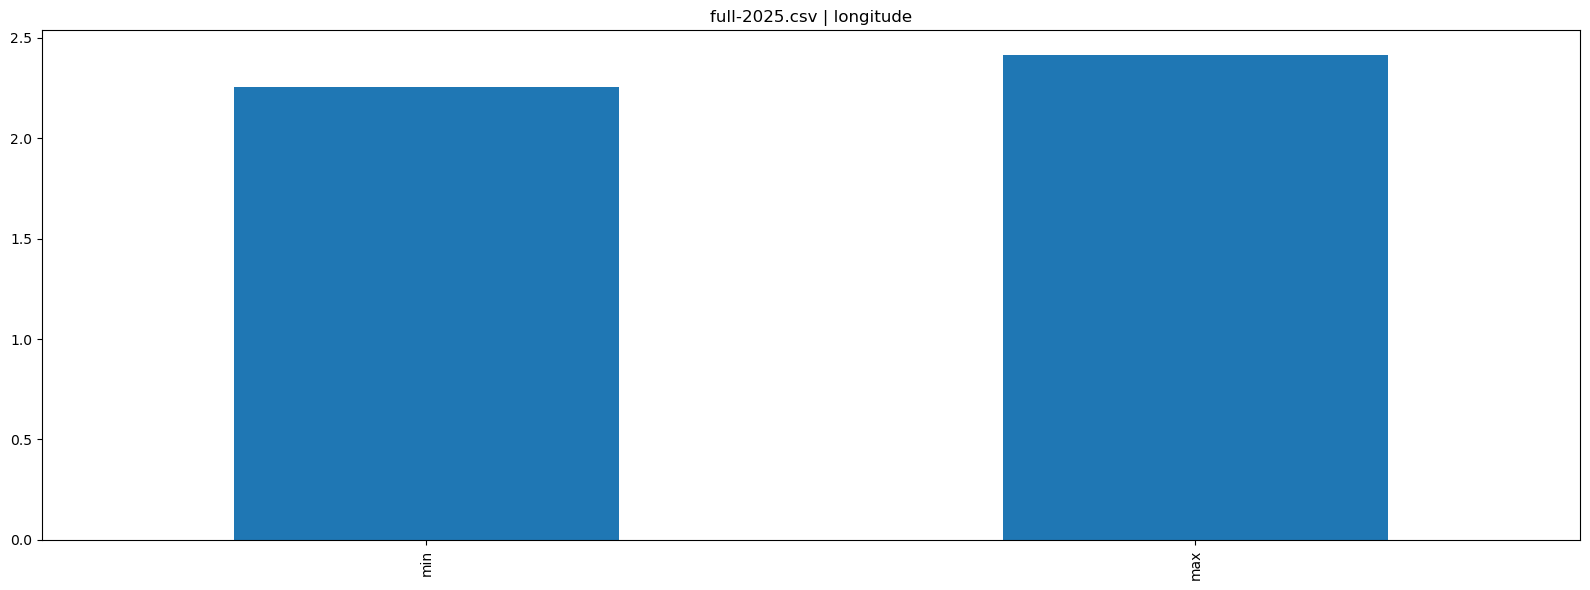

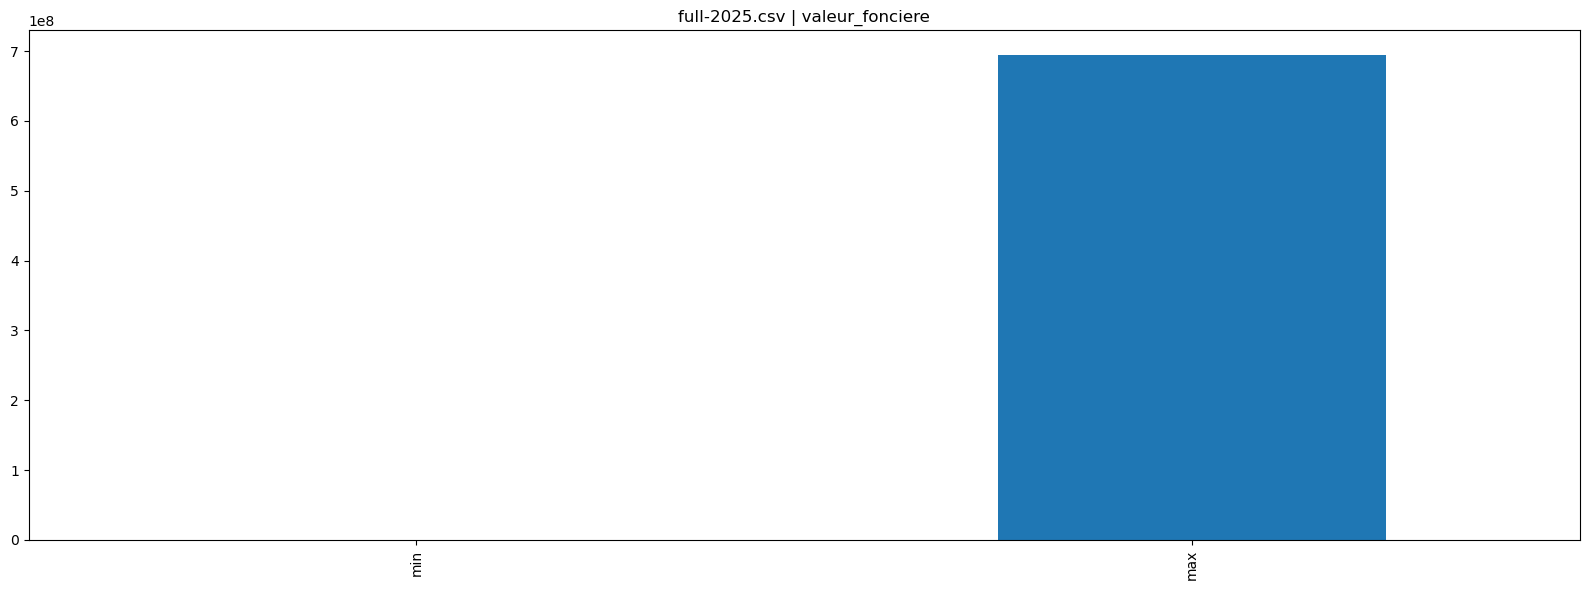

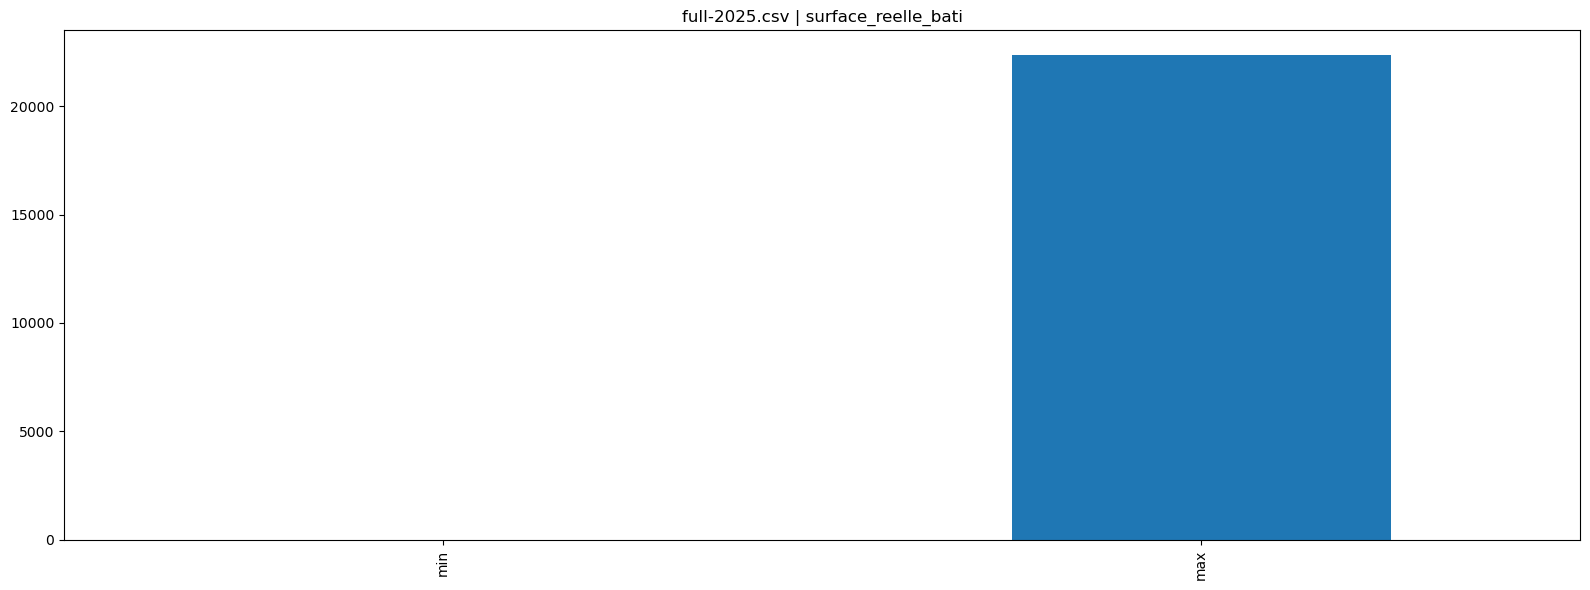

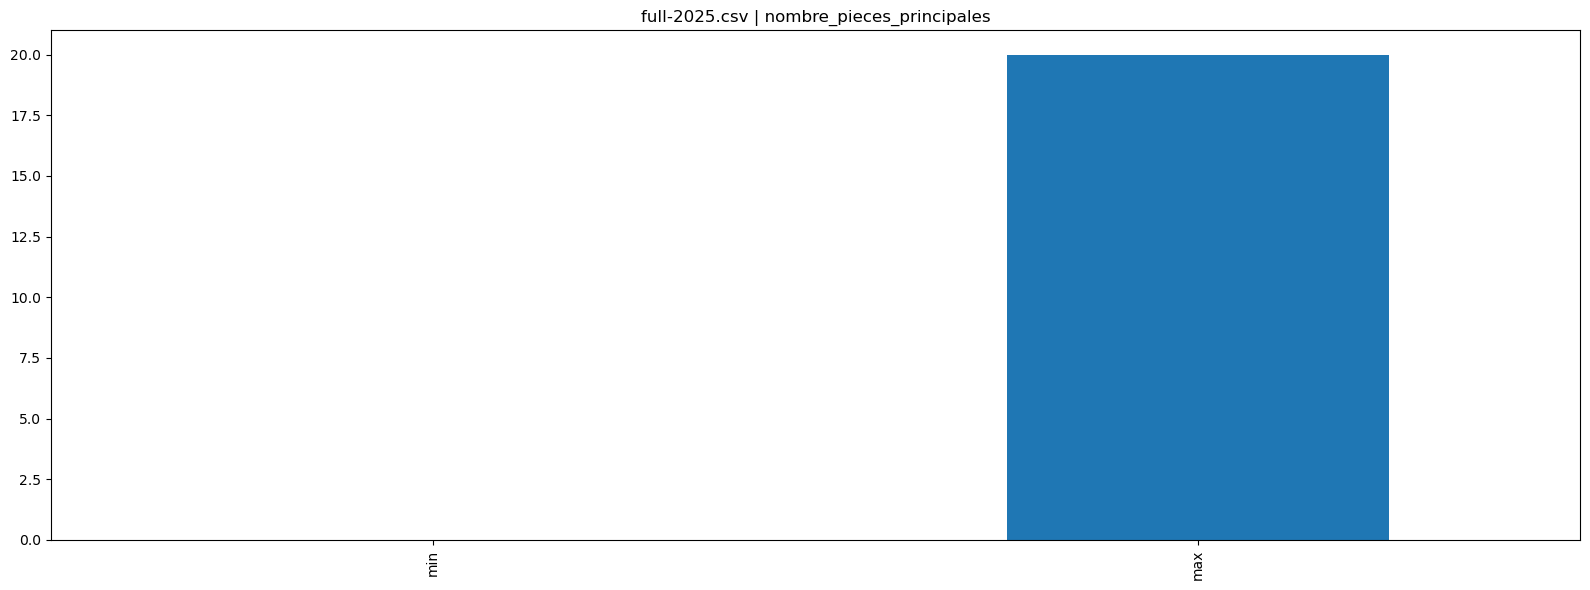

geoloc-geolocalisationetablissement-sirene-pour-etudes-statistiques-parquet.parquet : 3,319,807 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
siret,0.0,100.0,100.0,,100.0
x,0.0,2.2,,0.0,
y,0.0,0.5,,0.0,
qualite_xy,0.0,0.0,0.0,,100.0
plg_iris,0.1,0.0,0.0,,99.9
plg_code_commune,0.0,0.0,0.0,,100.0


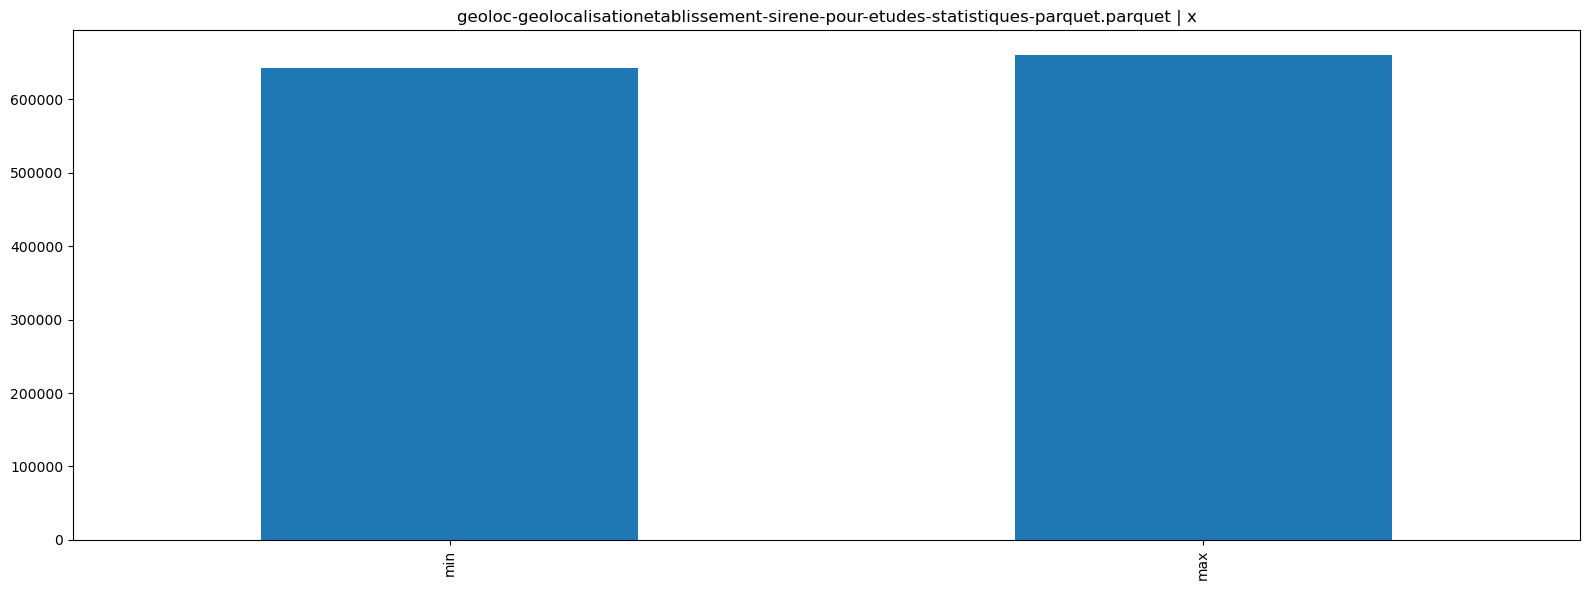

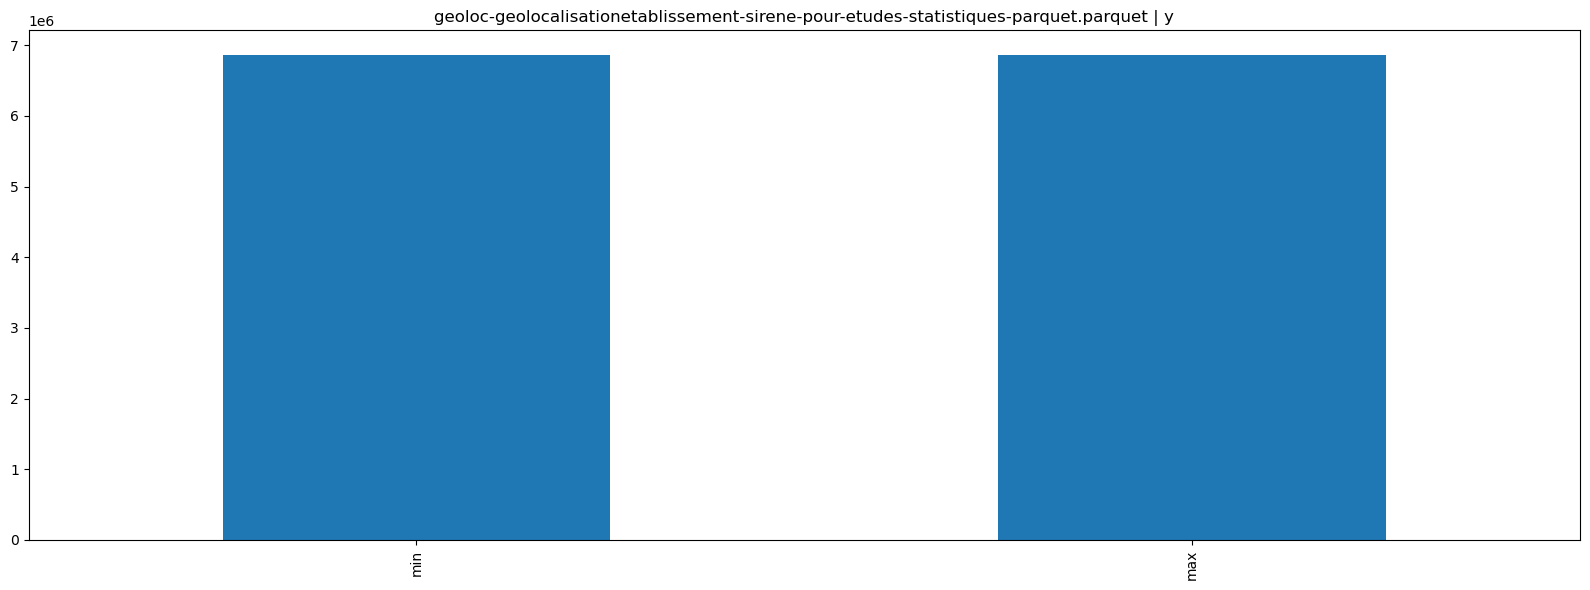

iris.geojson : 992 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
code_iris,0.0,100.0,,,
nom_iris,0.0,98.1,,,
typ_iris,0.0,0.3,,,
nom_com,0.0,2.0,,,
geometry,0.0,100.0,,,
insee_com,0.0,2.0,,0.0,
id,0.0,100.0,,,


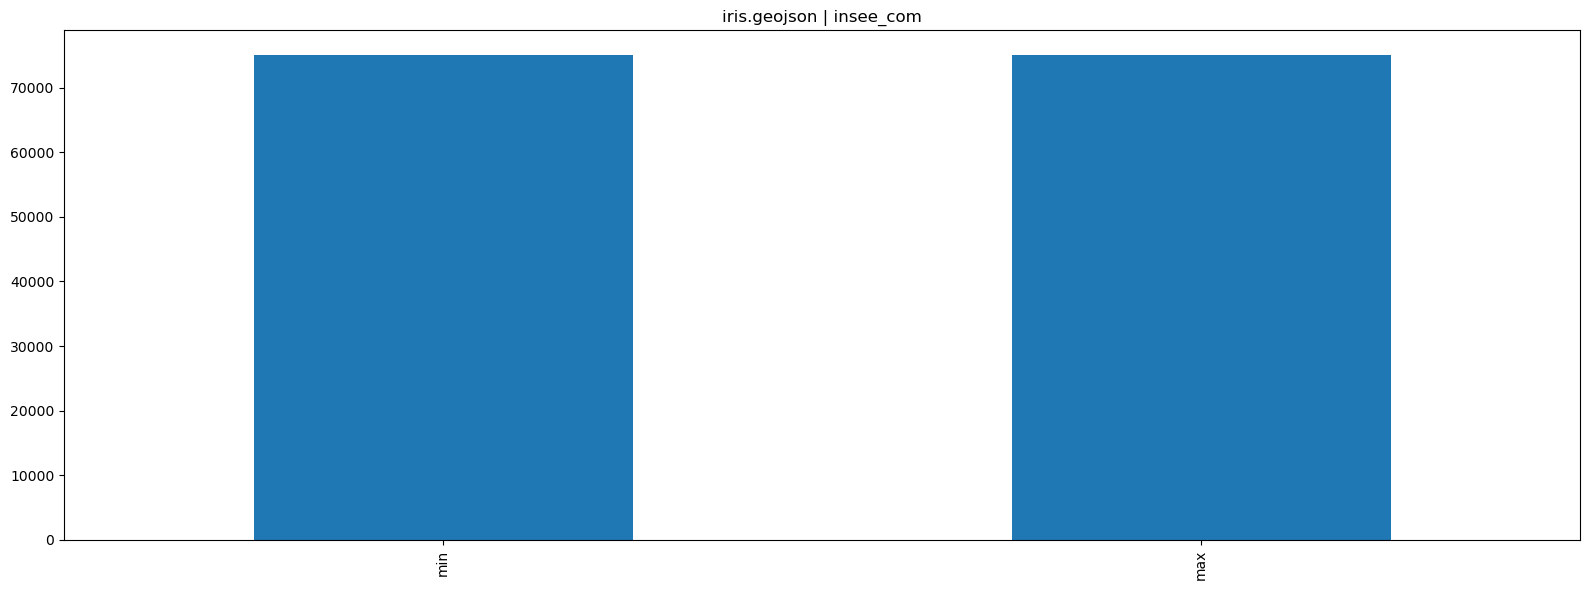

iris_paris_dataset.csv : 992 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
code_iris,0.0,100.0,,,
nom_iris,0.0,98.1,,,
typ_iris,0.0,0.3,,,
nom_com,0.0,2.0,,,
nom_quartier,0.0,8.1,,,


iris_paris_dataset.parquet : 992 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
code_iris,0.0,100.0,,,
nom_iris,0.0,98.1,,,
typ_iris,0.0,0.3,,,
nom_com,0.0,2.0,,,
geometry,0.0,100.0,100.0,,0.0
nom_quartier,0.0,8.1,,,


les-arbres.parquet : 220,181 lignes, 3 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
domanialite,0.0,0.0,0.0,,0.0
arrondissement,0.0,0.0,0.0,,0.0
libellefrancais,1.7,0.1,0.1,,0.0
genre,0.0,0.1,0.1,,0.0
espece,2.2,0.3,0.3,,0.0
circonferenceencm,0.0,0.2,,7.6,
hauteurenm,0.0,0.0,,9.0,
stadedeveloppement,16.5,0.0,0.0,,0.0
remarquable,6.1,0.0,0.0,,0.0
geo_point_2d,0.0,100.0,100.0,,0.0


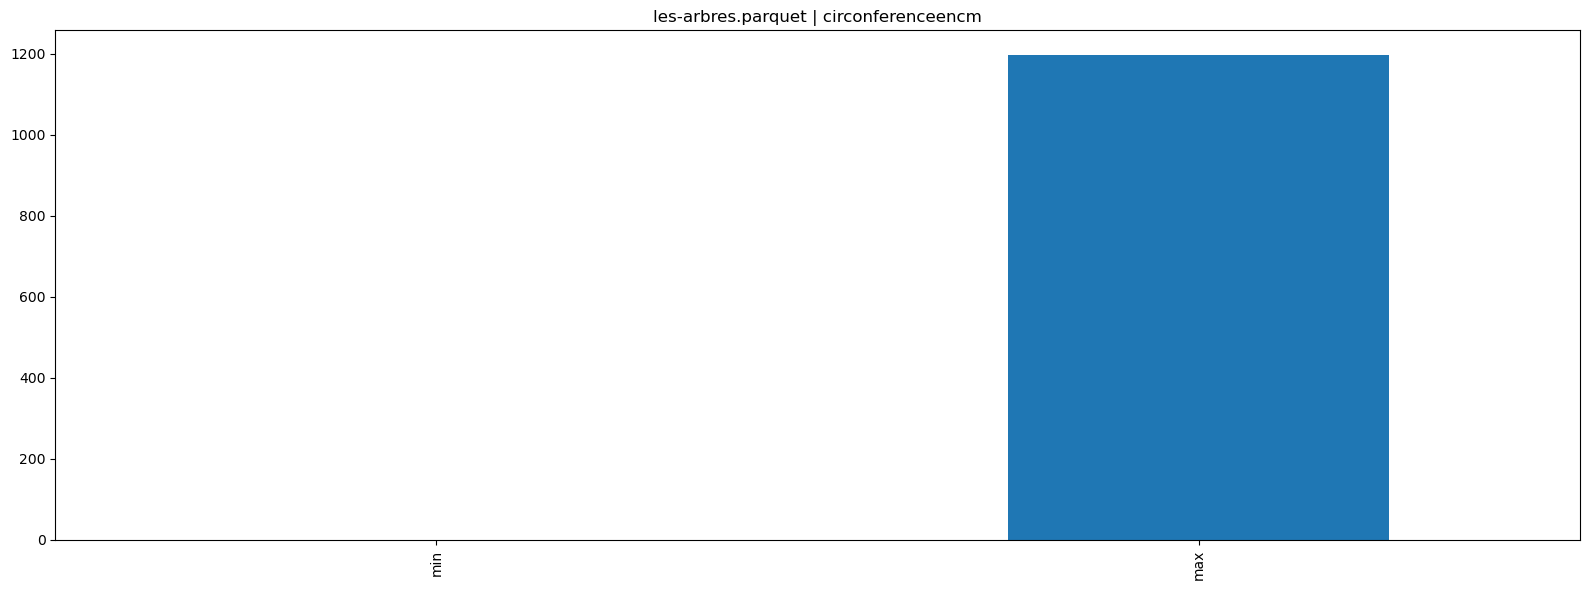

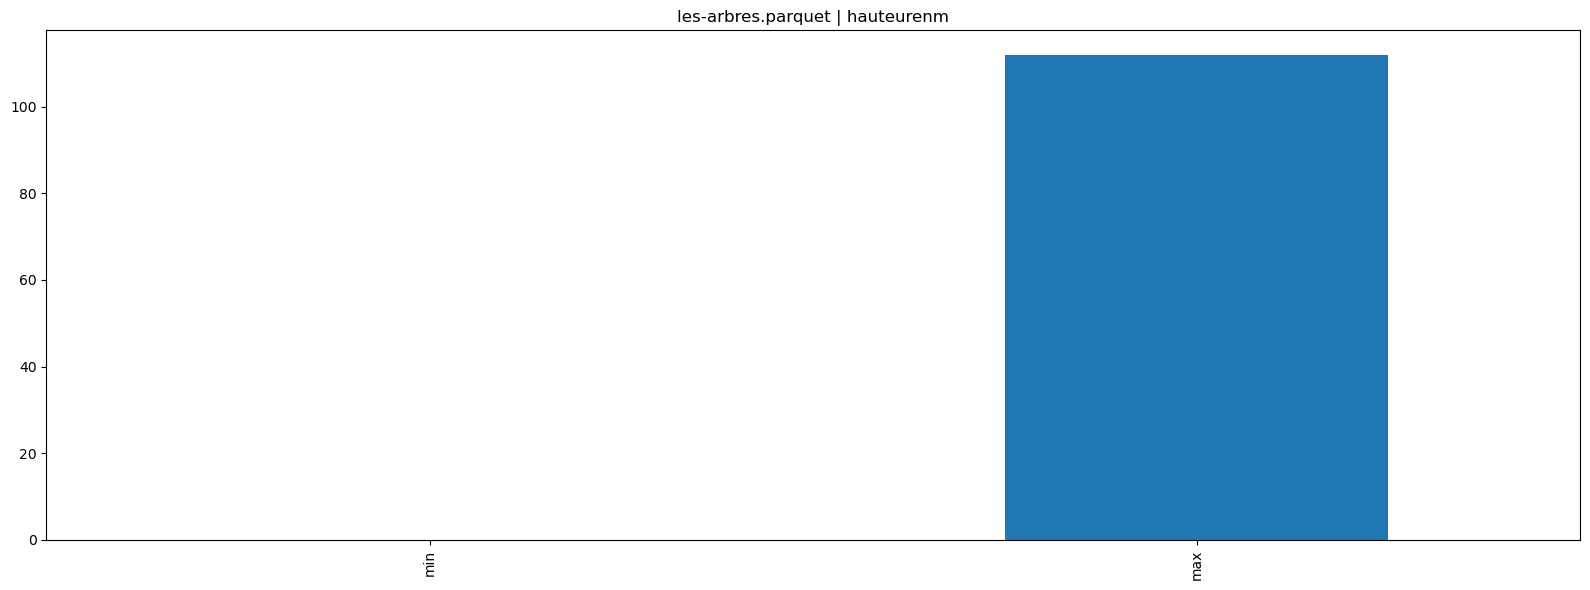

lieux-municipaux.parquet : 3,671 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
categorie,0.0,2.1,2.1,,0.0
id,0.0,98.5,,0.0,
name,0.0,97.8,97.8,,0.0
address_street,0.0,91.4,90.1,,0.0
address_postcode,0.0,0.6,0.6,,100.0
address_city,0.0,0.1,0.1,,0.0
accessibility,0.0,12.7,12.7,,0.0
latitude,0.0,84.8,,0.0,
longitude,0.0,86.0,,0.0,
geo,0.0,87.2,87.2,,0.0


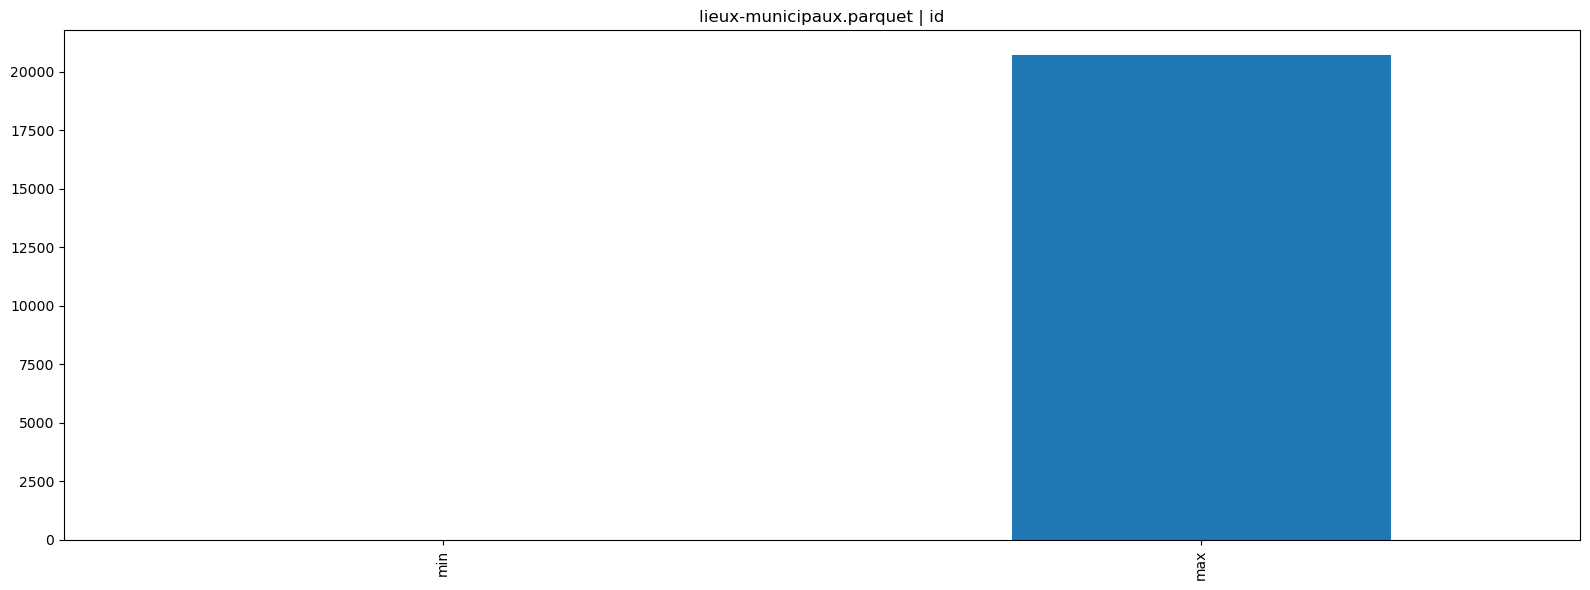

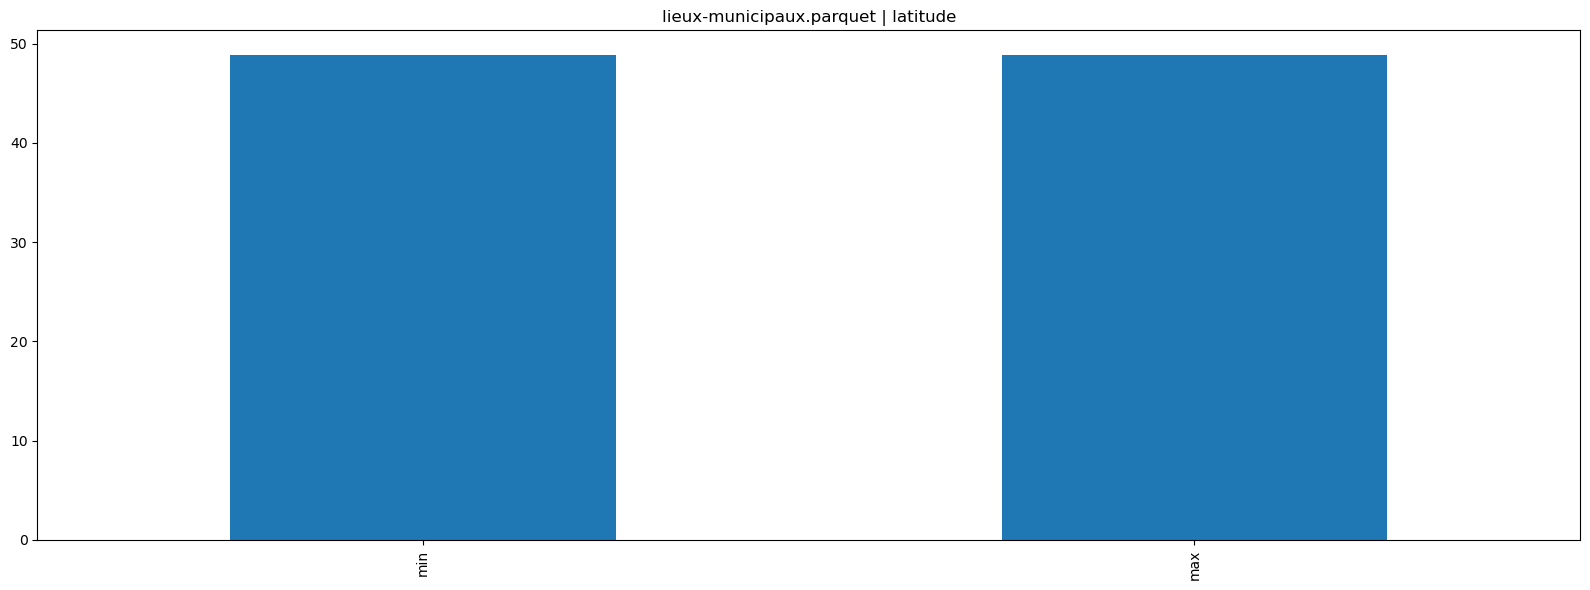

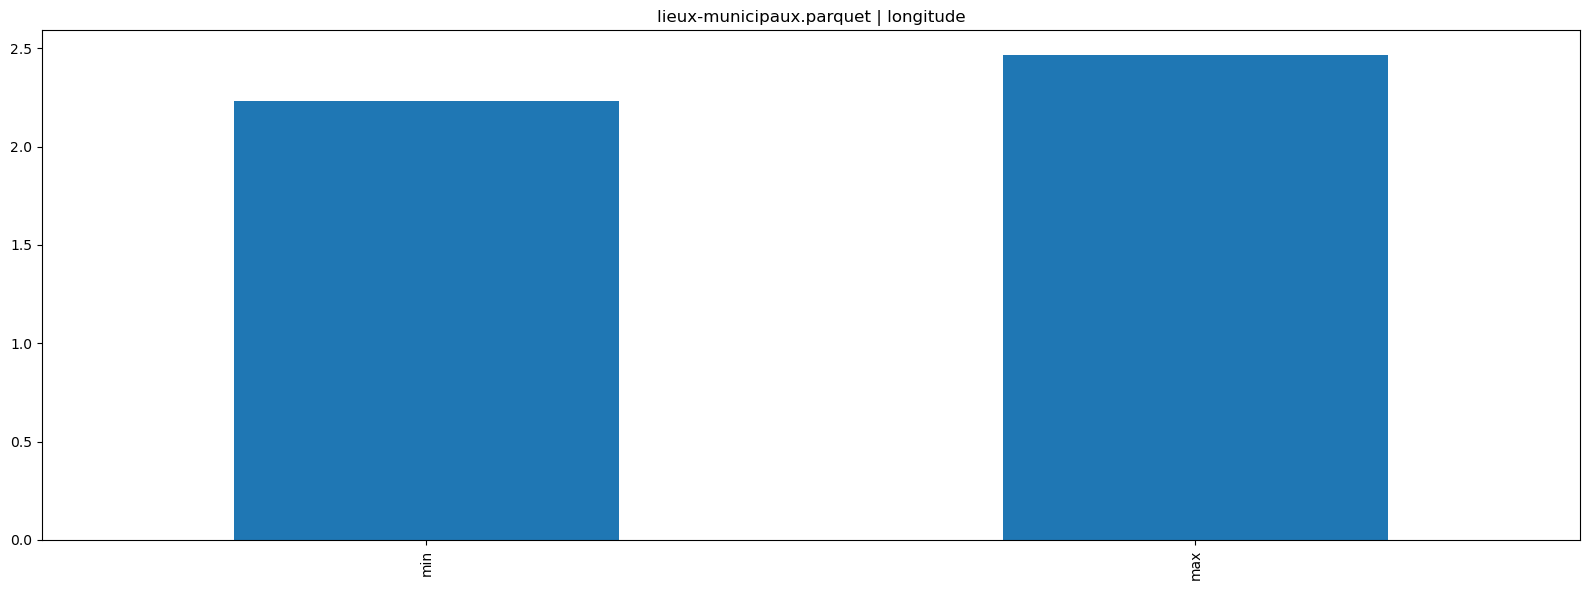

logement-encadrement-des-loyers.geojson : 17,920 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
geometry,0.0,0.4,,,
geo_point_2d,0.0,0.4,,,
annee,0.0,0.0,,,
id_zone,0.0,0.1,,0.0,
id_quartier,0.0,0.4,,0.0,
nom_quartier,0.0,0.4,,,
piece,0.0,0.0,,0.0,
epoque,0.0,0.0,,,
meuble_txt,0.0,0.0,,,
ref,0.0,1.3,,0.0,


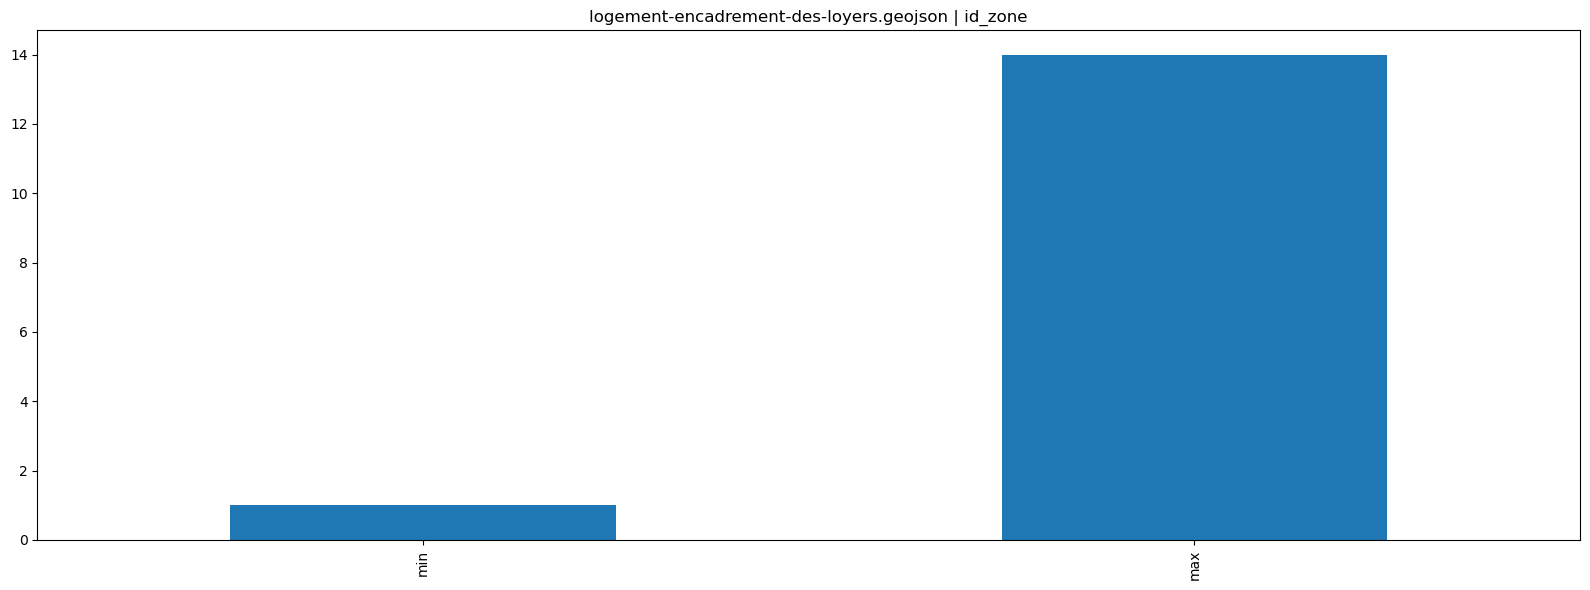

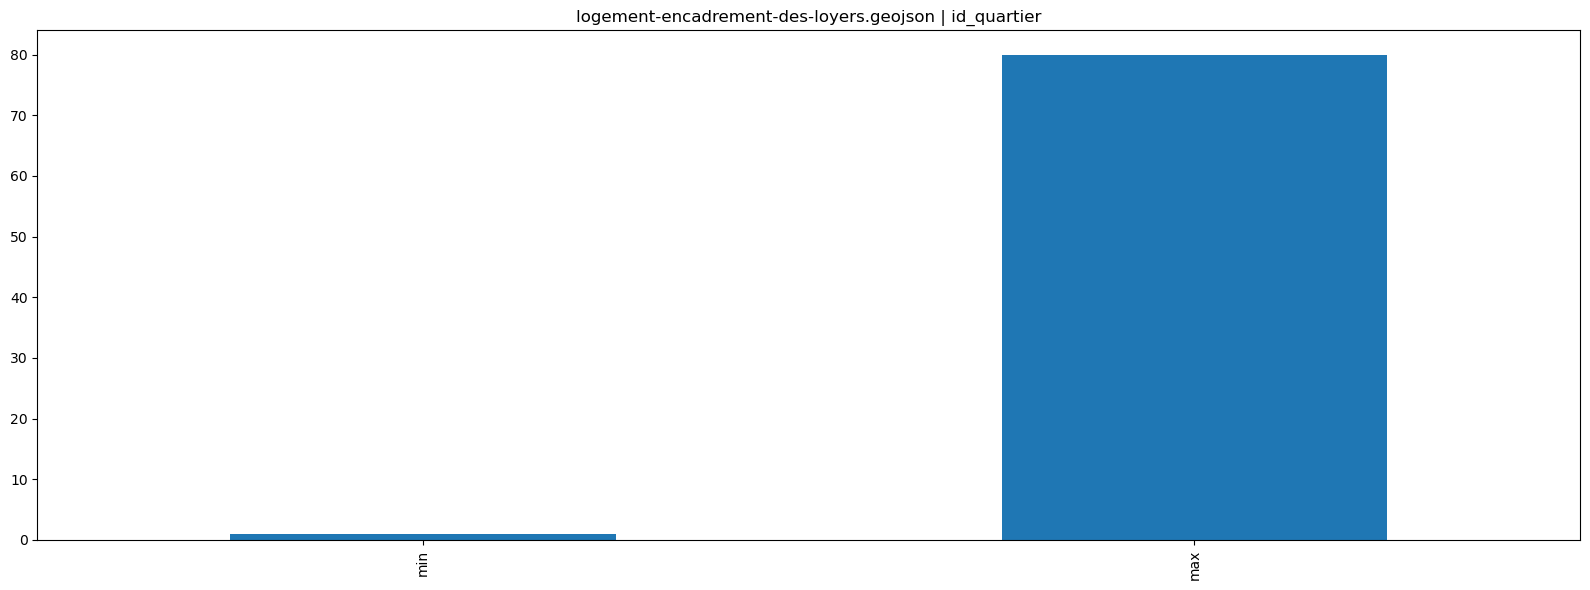

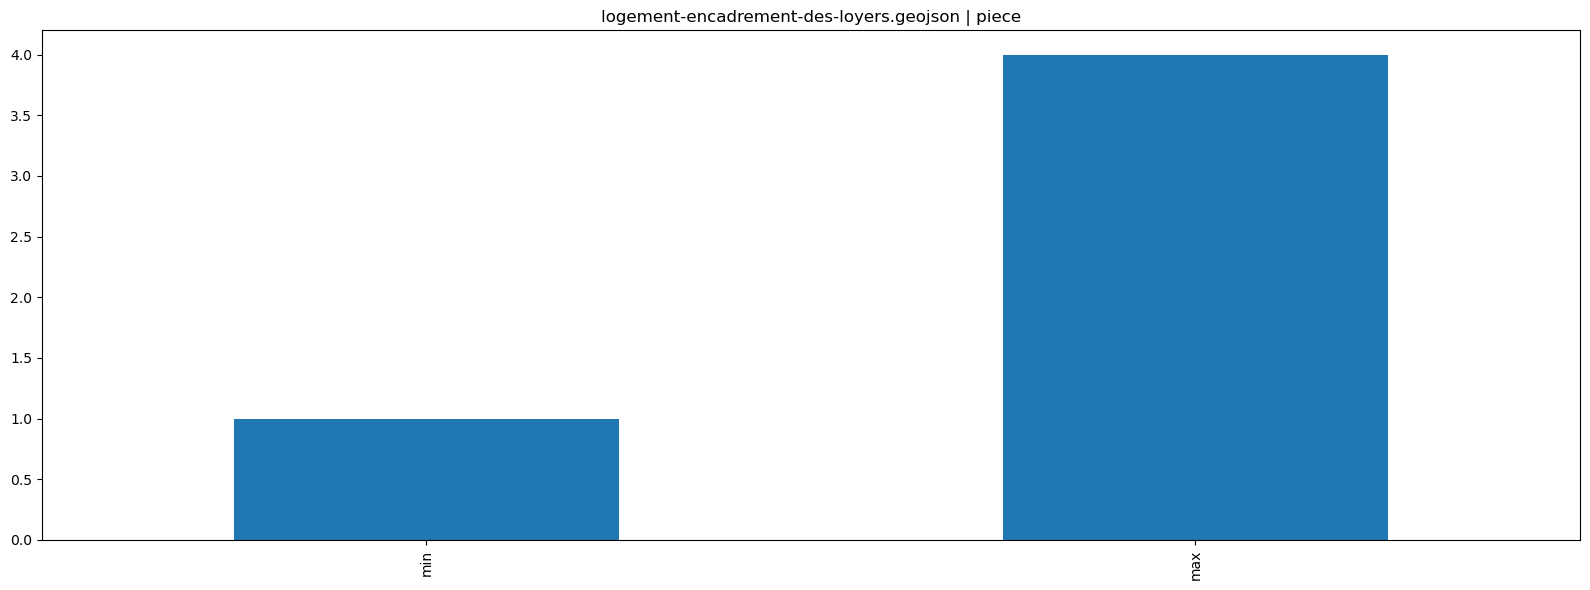

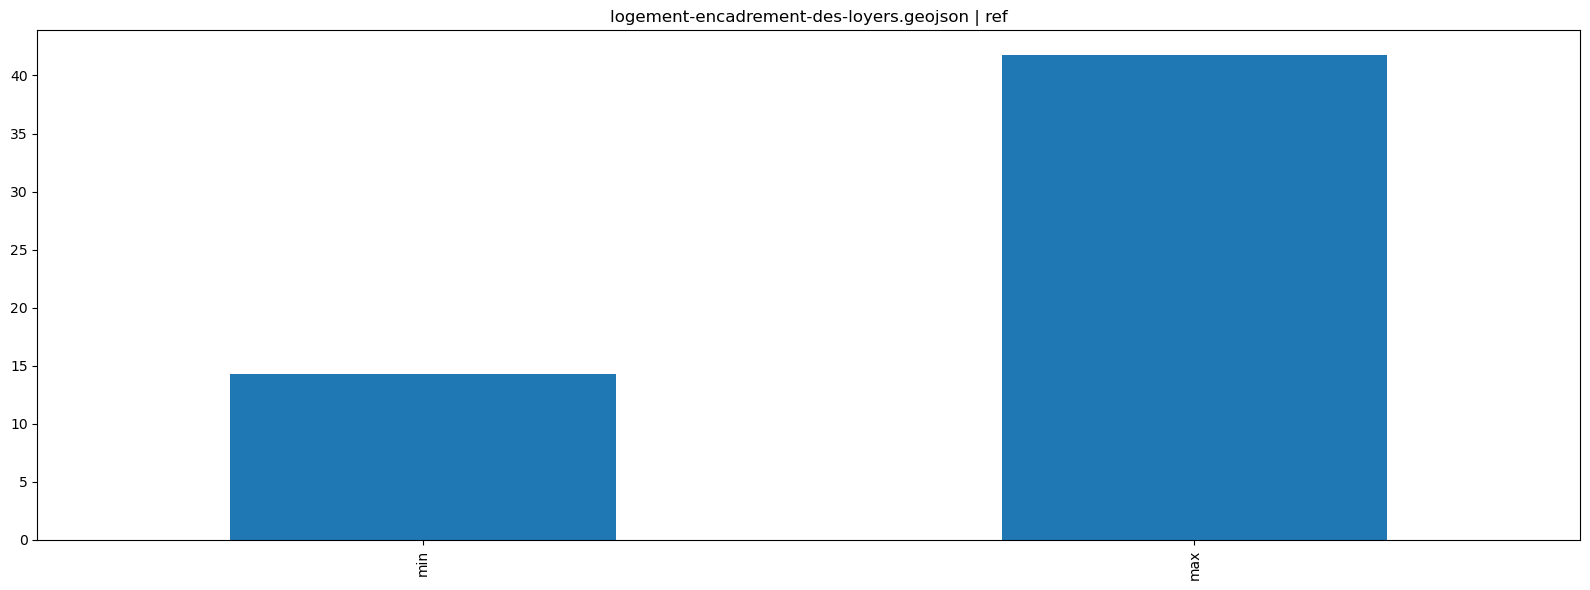

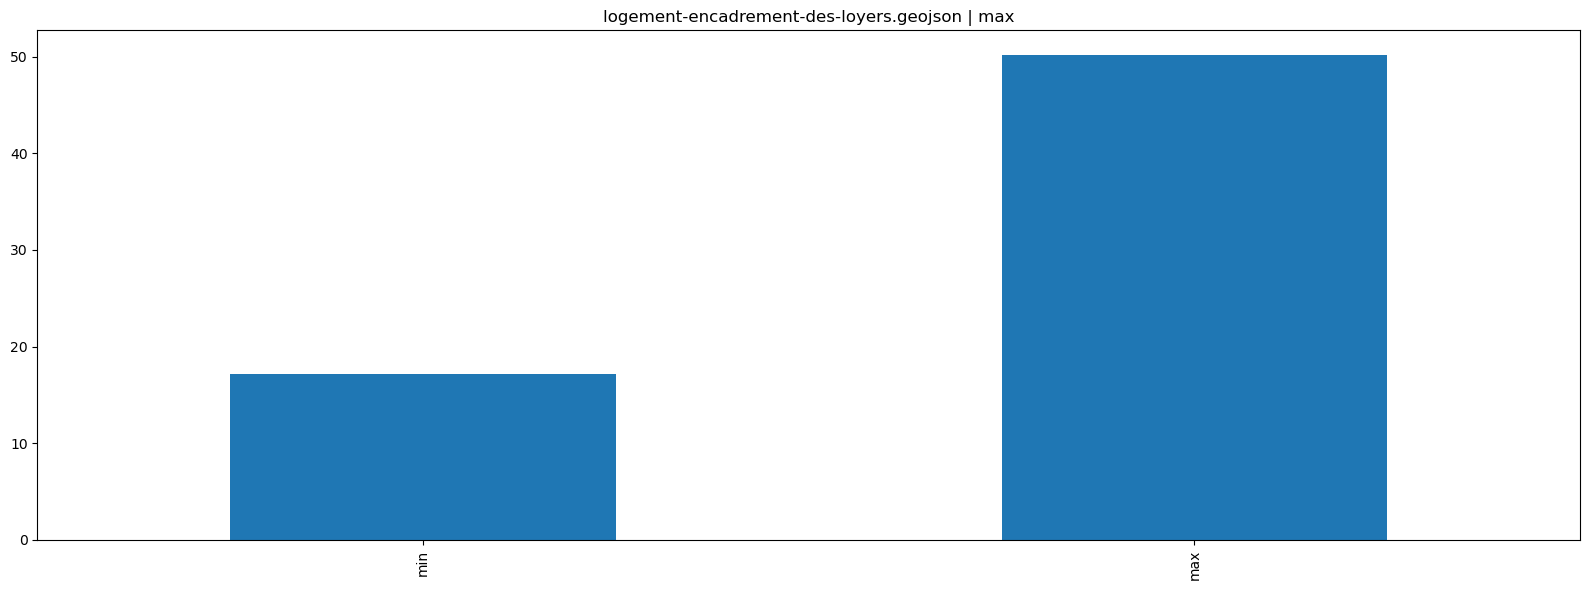

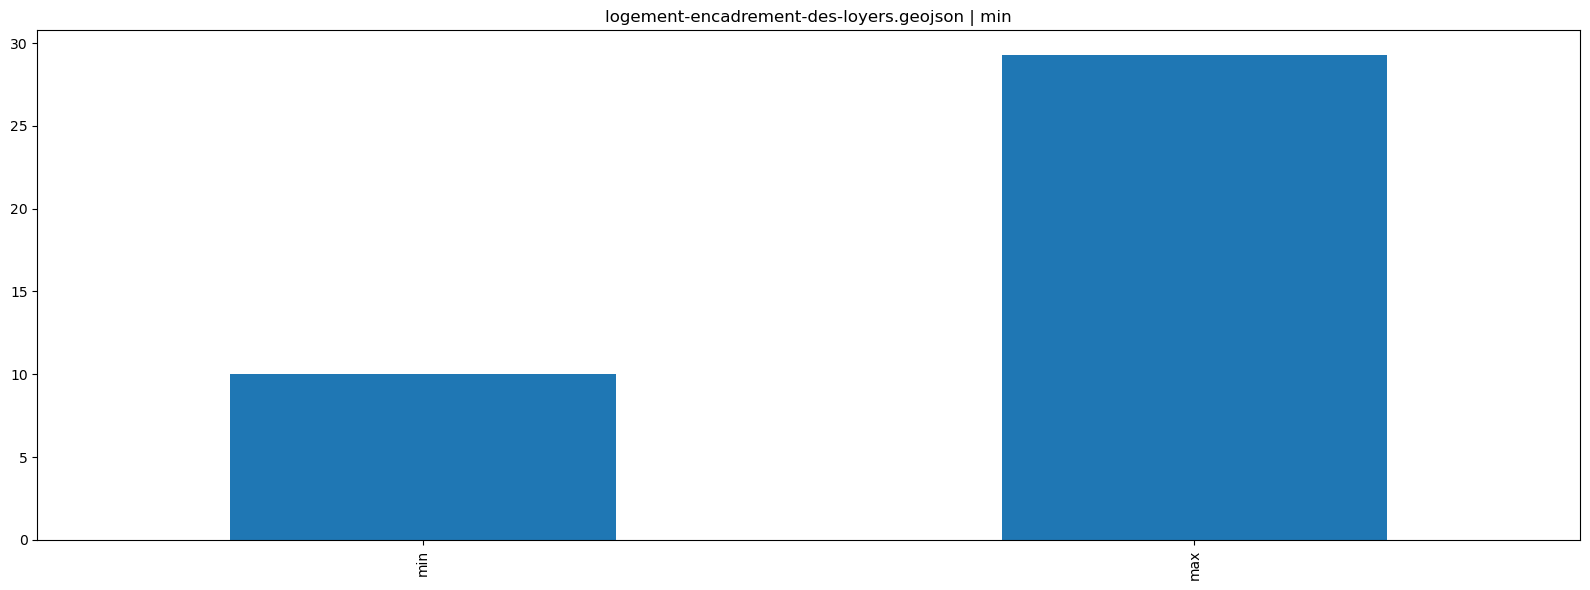

stationnement-sur-voie-publique-secteurs-residentiels.geojson : 162 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
geometry,0.0,100.0,,,
geo_point_2d,0.0,100.0,,,
nom,0.0,100.0,,,
st_area_shape,0.0,100.0,,0.0,
st_perimeter_shape,0.0,100.0,,0.0,


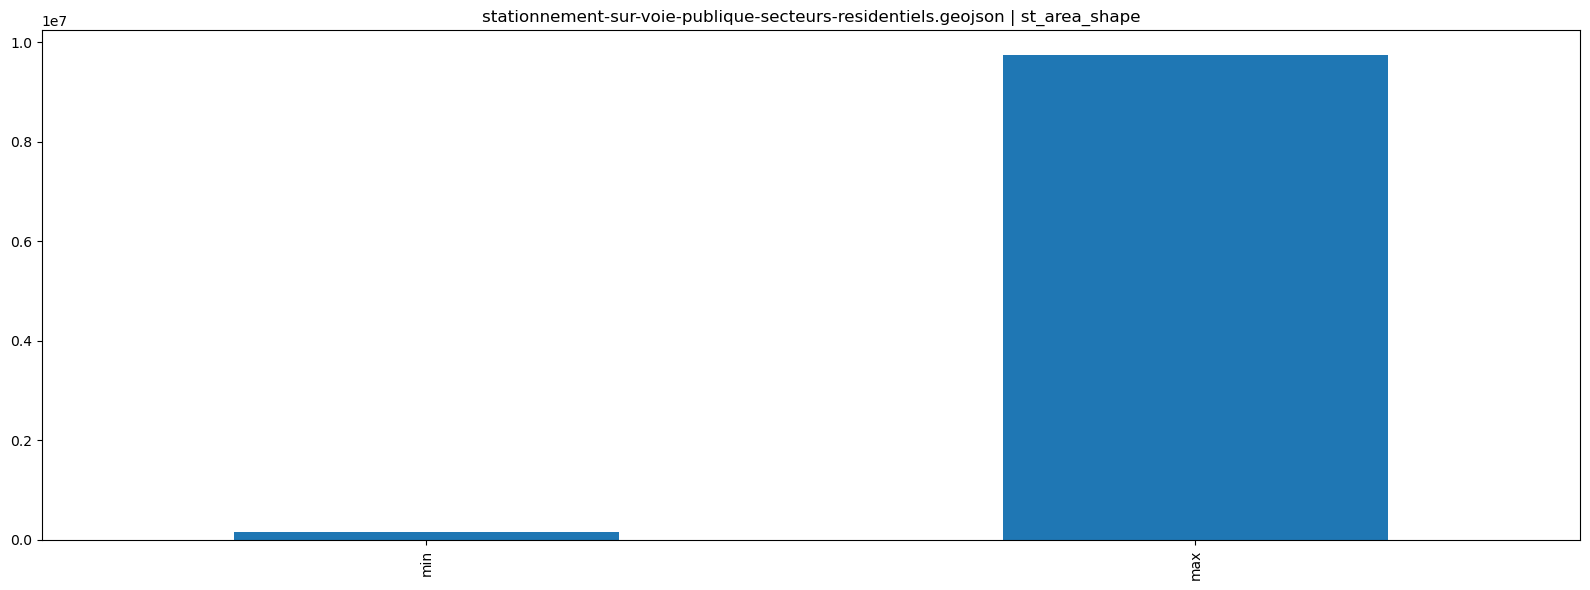

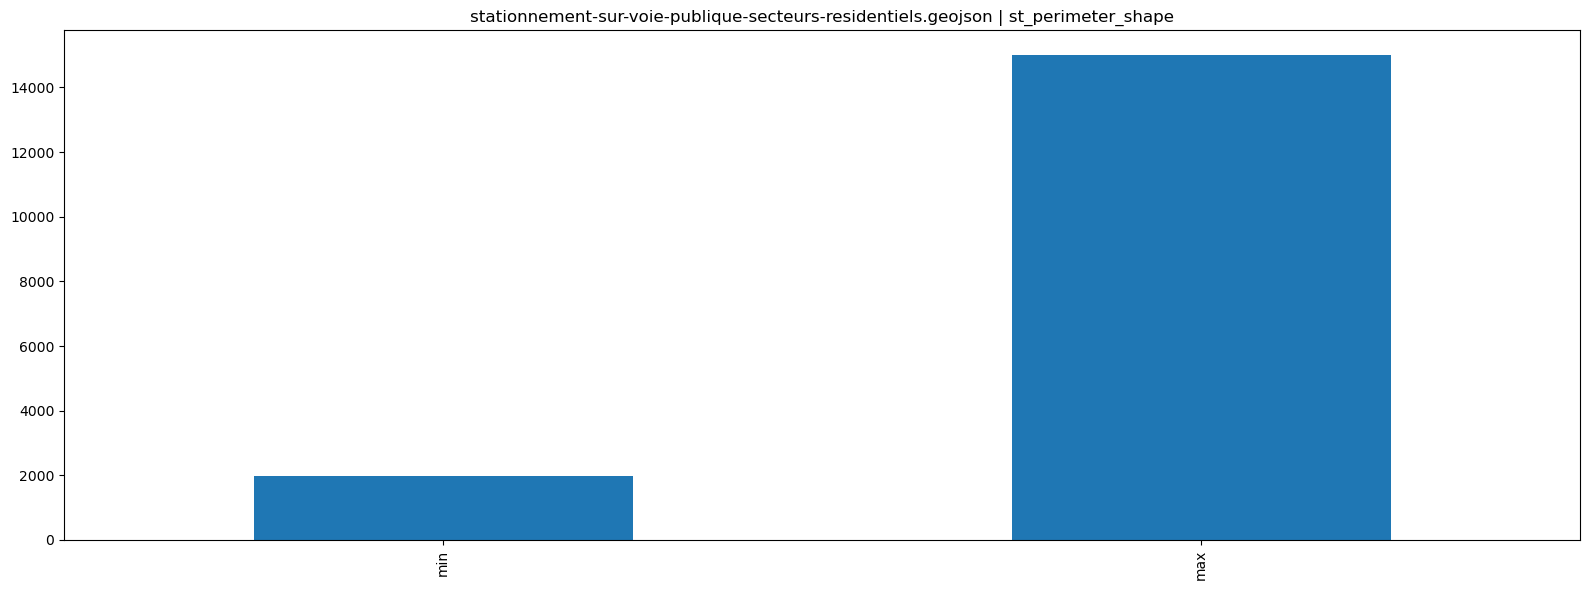

stationnement-voie-publique-emplacements.parquet : 65,805 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
geo_point_2d,0.0,100.0,100.0,,0.0
id,64.4,35.6,,0.0,
regpri,0.0,0.0,0.0,,0.0
typsta,0.0,0.0,0.0,,0.0
plarel,0.0,0.1,,0.1,
arrond,0.0,0.0,,0.0,
zoneres,0.0,0.2,0.2,,0.0
locsta,0.0,0.0,0.0,,0.0
numvoie,34.9,0.6,,0.1,
typevoie,0.0,0.2,0.2,,0.0


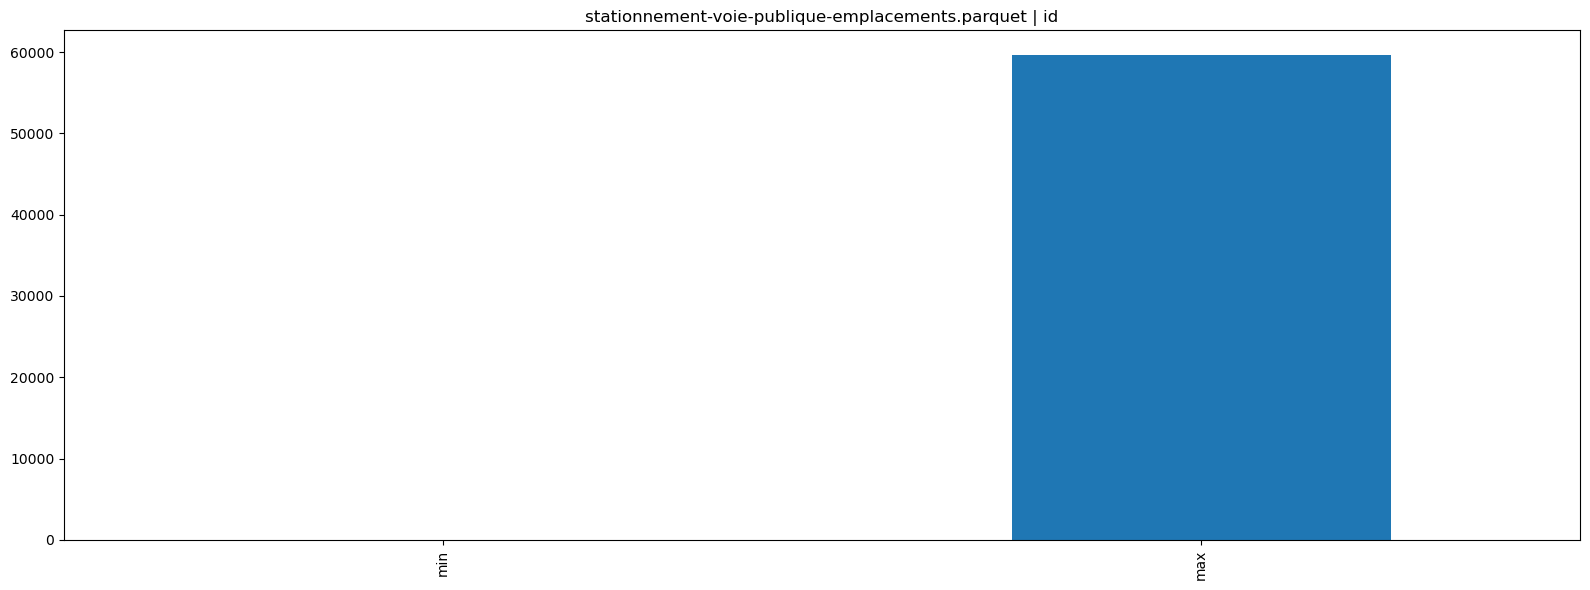

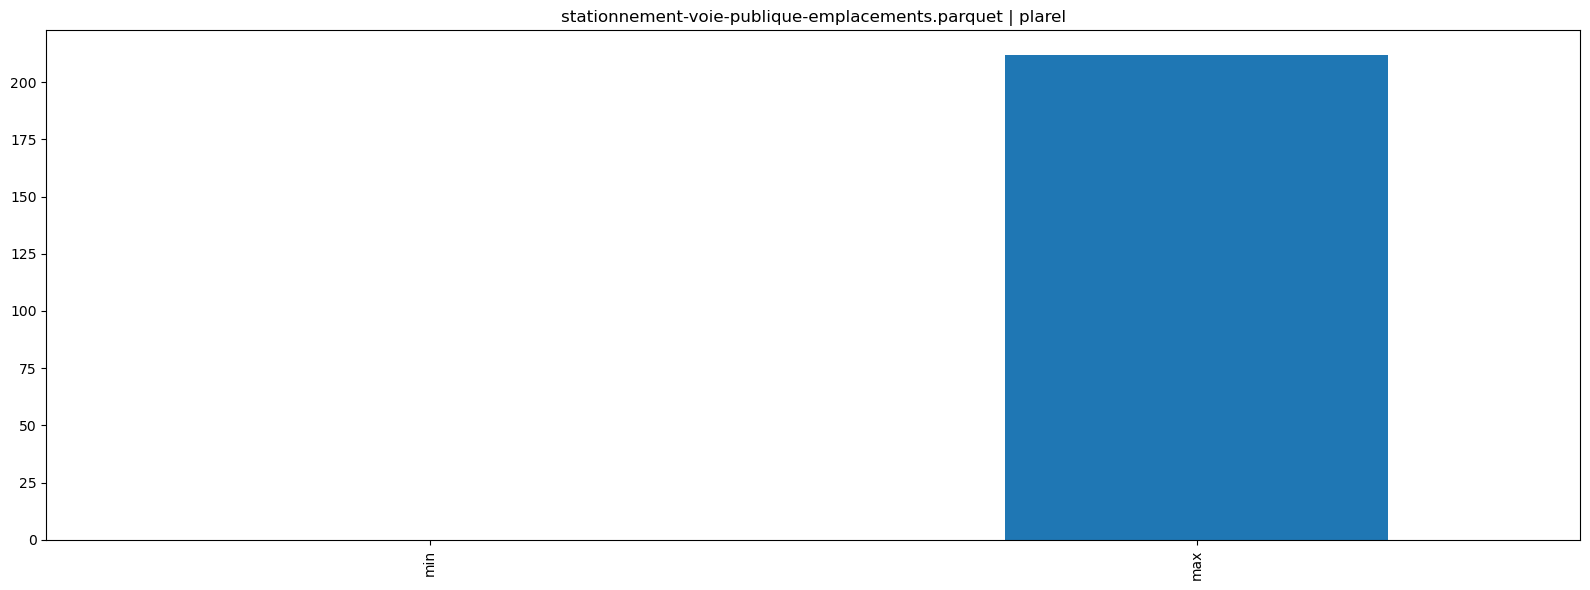

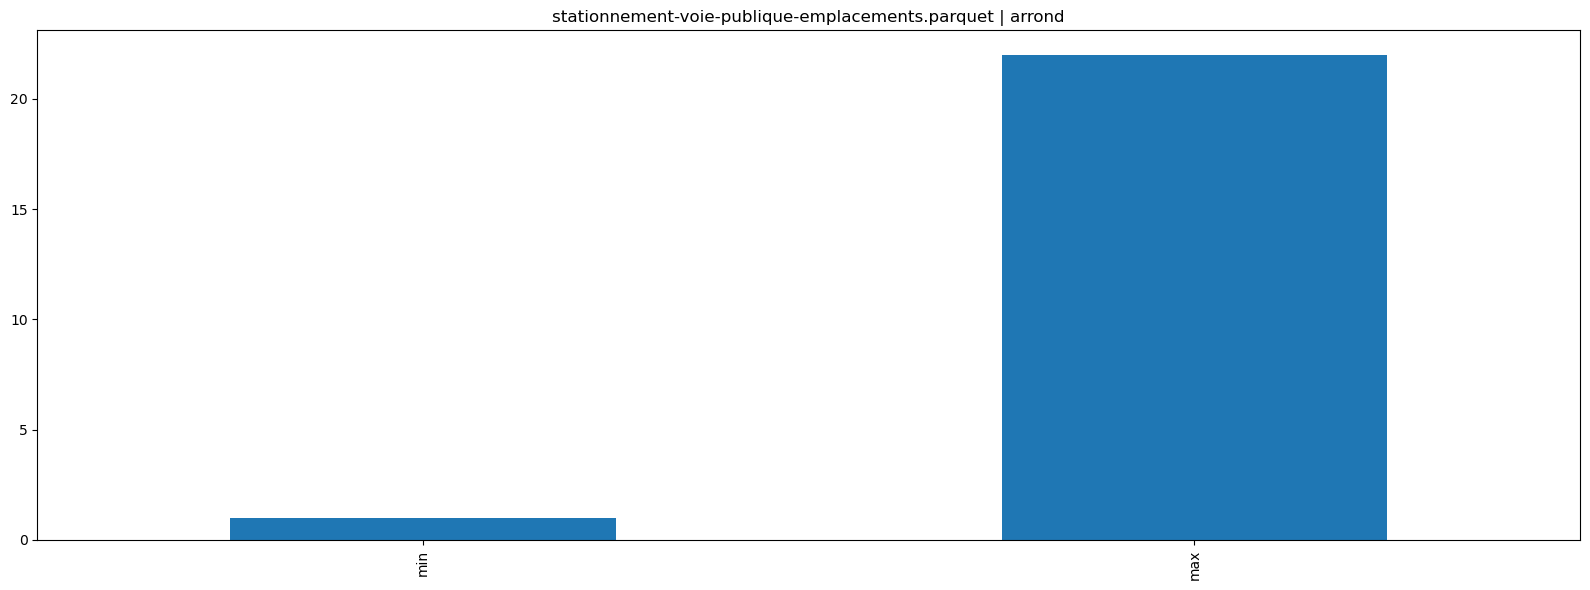

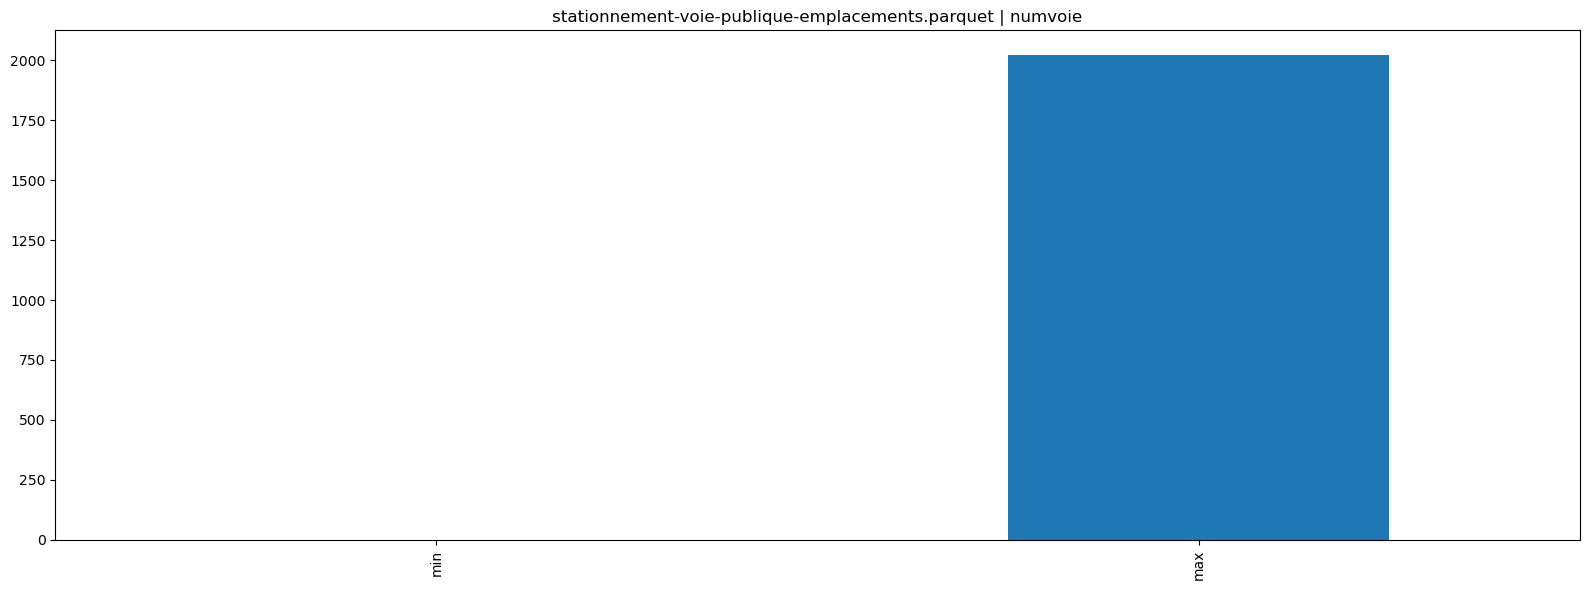

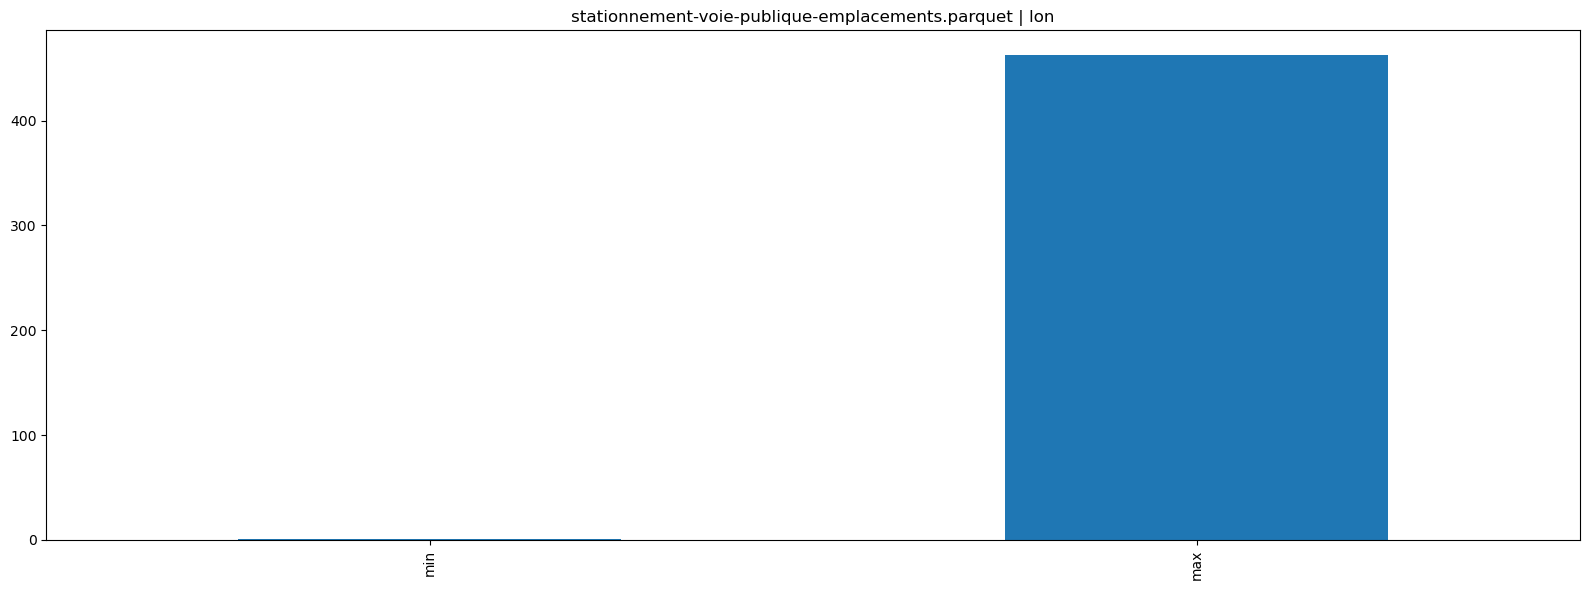

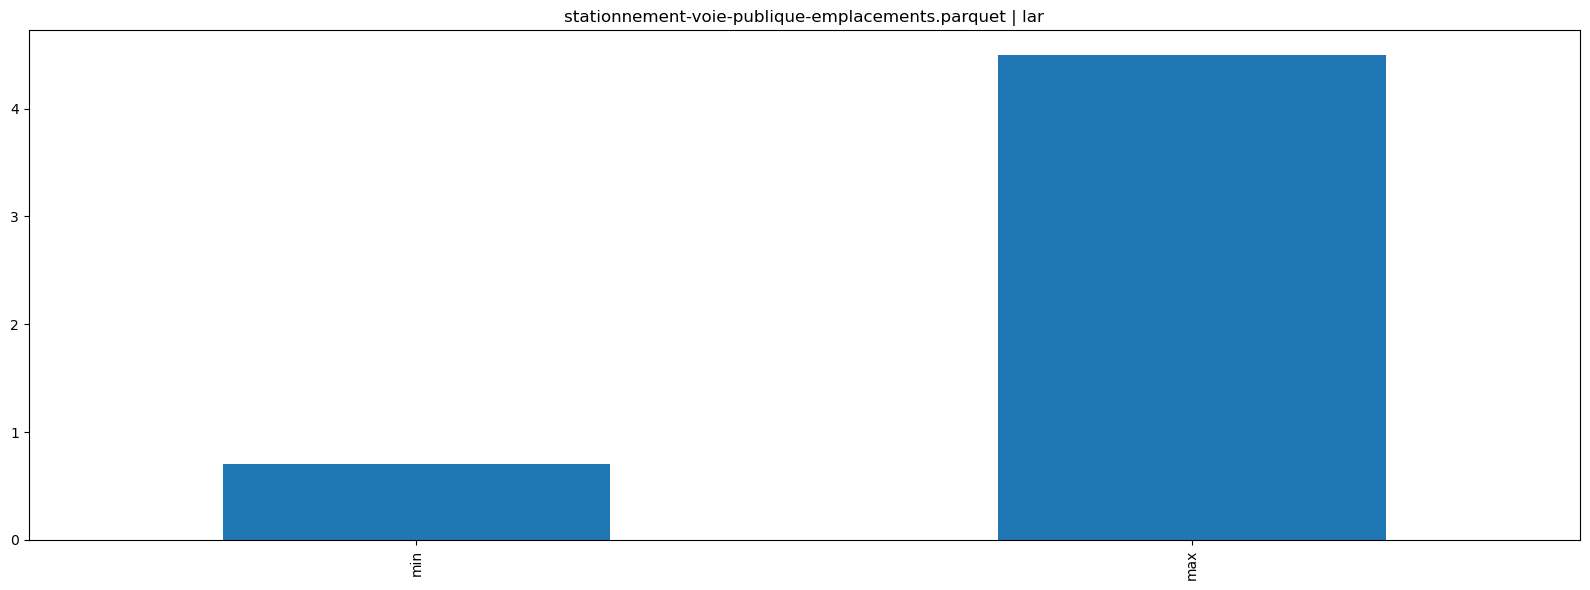

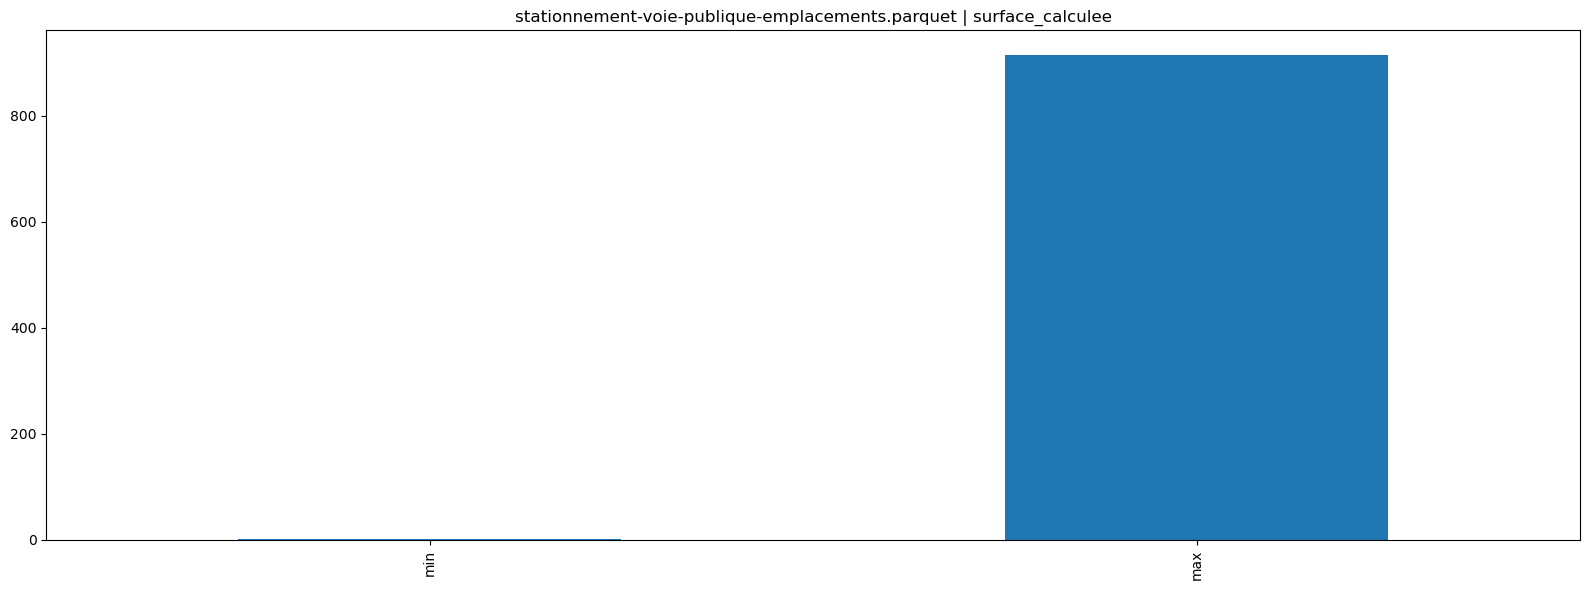

stock-stocketablissement-parquet.parquet : 3,818,082 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
siret,0.0,100.0,100.0,,100.0
codeCommuneEtablissement,0.0,0.0,0.0,,100.0
etatAdministratifEtablissement,0.0,0.0,0.0,,0.0
activitePrincipaleEtablissement,0.0,0.1,0.1,,5.3
enseigne1Etablissement,83.7,3.2,3.2,,0.0
siren,0.0,75.4,75.4,,100.0


stock-stockunitelegale-parquet.parquet : 2,879,209 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
siren,0.0,100.0,100.0,,100.0
categorieEntreprise,57.2,0.0,0.0,,0.0
trancheEffectifsUniteLegale,0.0,0.0,0.0,,7.2
categorieJuridiqueUniteLegale,0.0,0.0,,0.0,
etatAdministratifUniteLegale,0.0,0.0,0.0,,0.0


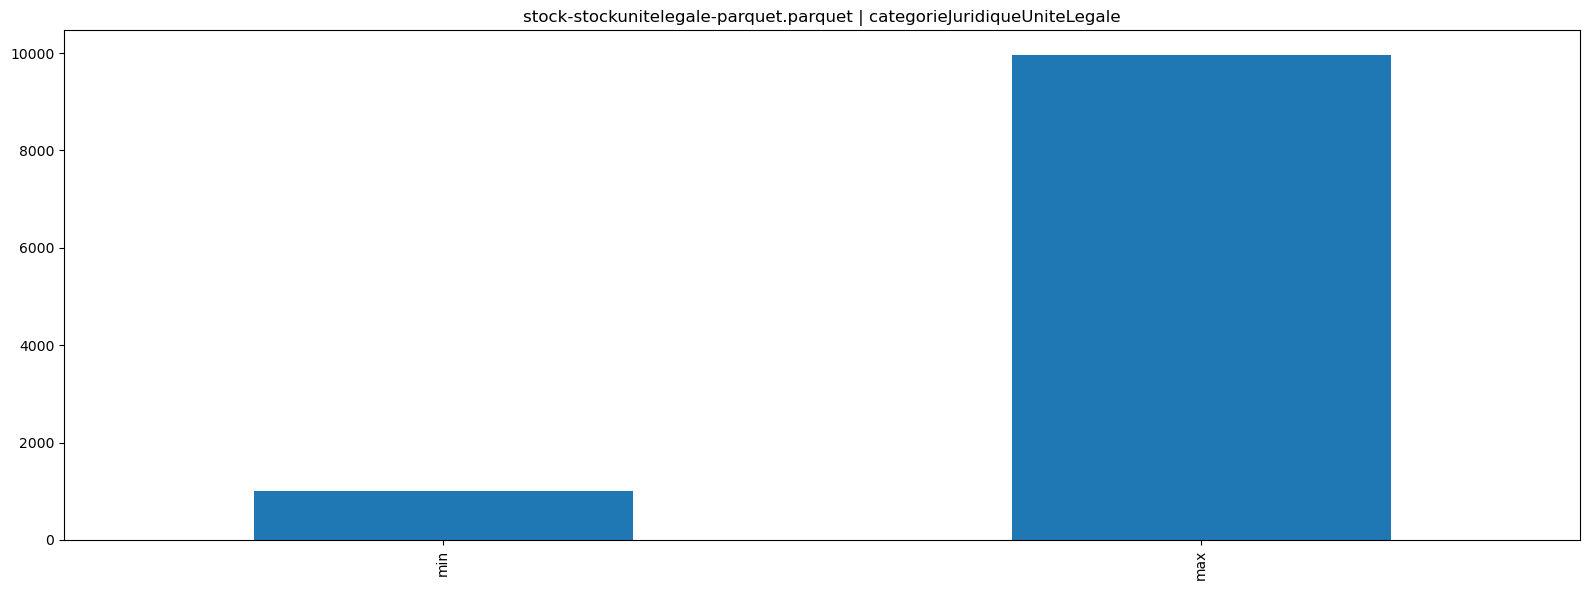

velib-localisation-et-caracteristique-des-stations.geojson : 1,208 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
geometry,0.0,100.0,,,
name,0.0,100.0,,,
stationcode,0.0,100.0,,,
capacity,0.0,5.7,,0.1,


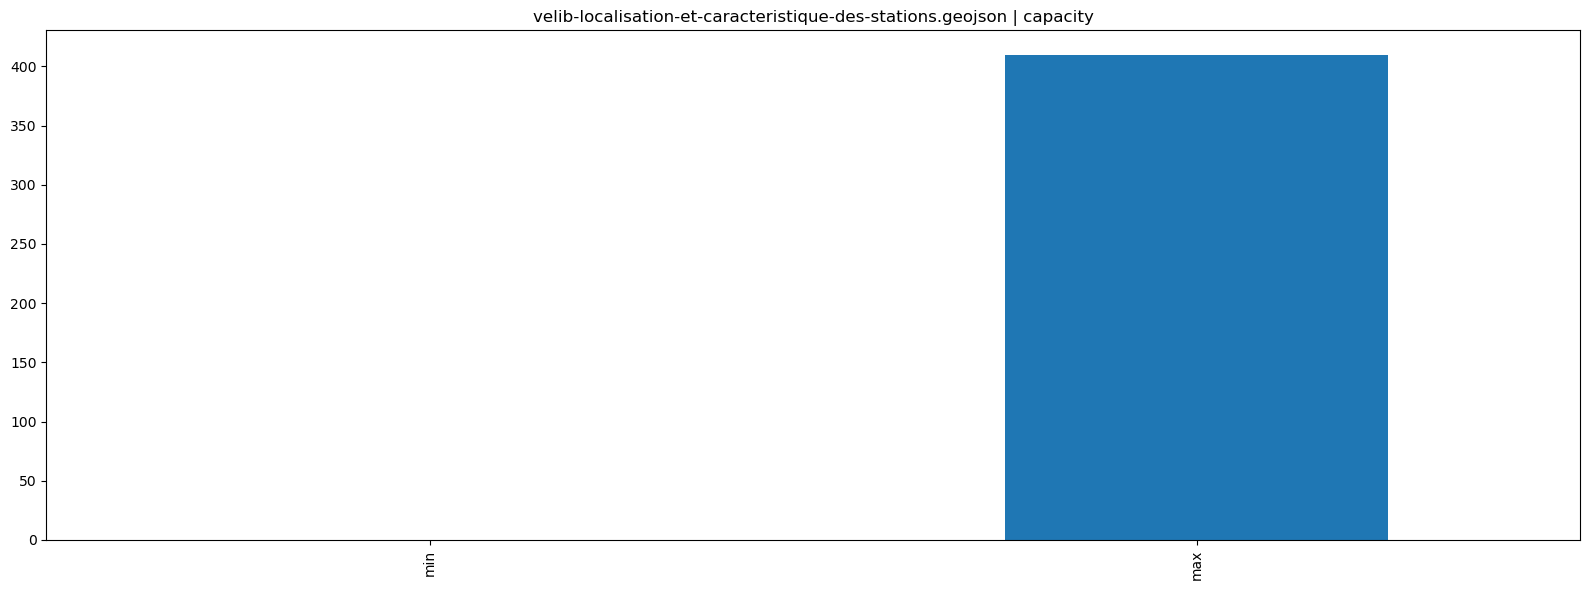

AirBruit_2024.shp : 280,372 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
geometry,0.0,100.0,,,
9,0.0,0.0,,0.0,


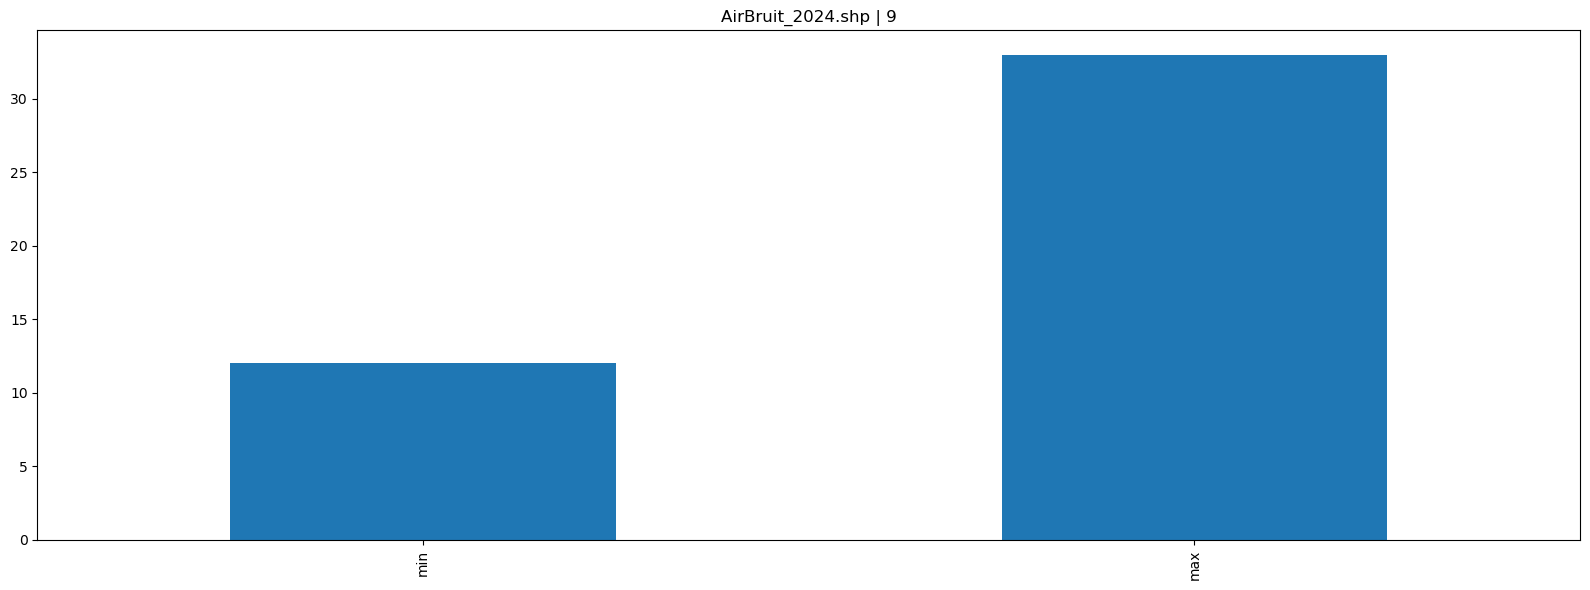

base-ic-activite-residents-2022.CSV : 992 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
IRIS,0.0,100.0,,,
COM,0.0,2.0,,,
P22_POP1564,0.0,95.4,,4.7,
P22_POP1524,0.0,95.0,,5.1,
P22_POP5564,0.0,95.0,,5.1,
P22_ACT1564,0.0,95.3,,4.8,
P22_CHOM1564,0.0,94.3,,5.8,
P22_ETUD1564,0.0,95.0,,5.1,
P22_RETR1564,0.0,92.6,,7.5,
C22_ACT1564,0.0,95.0,,5.1,


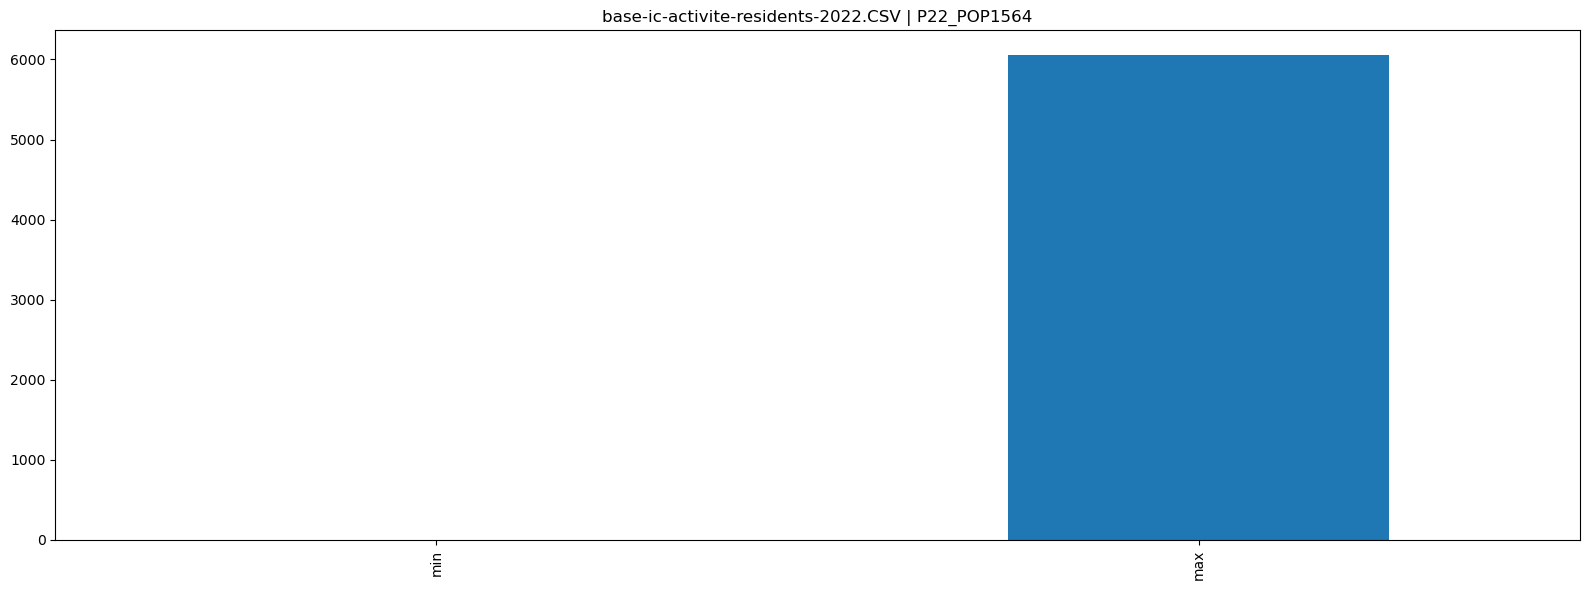

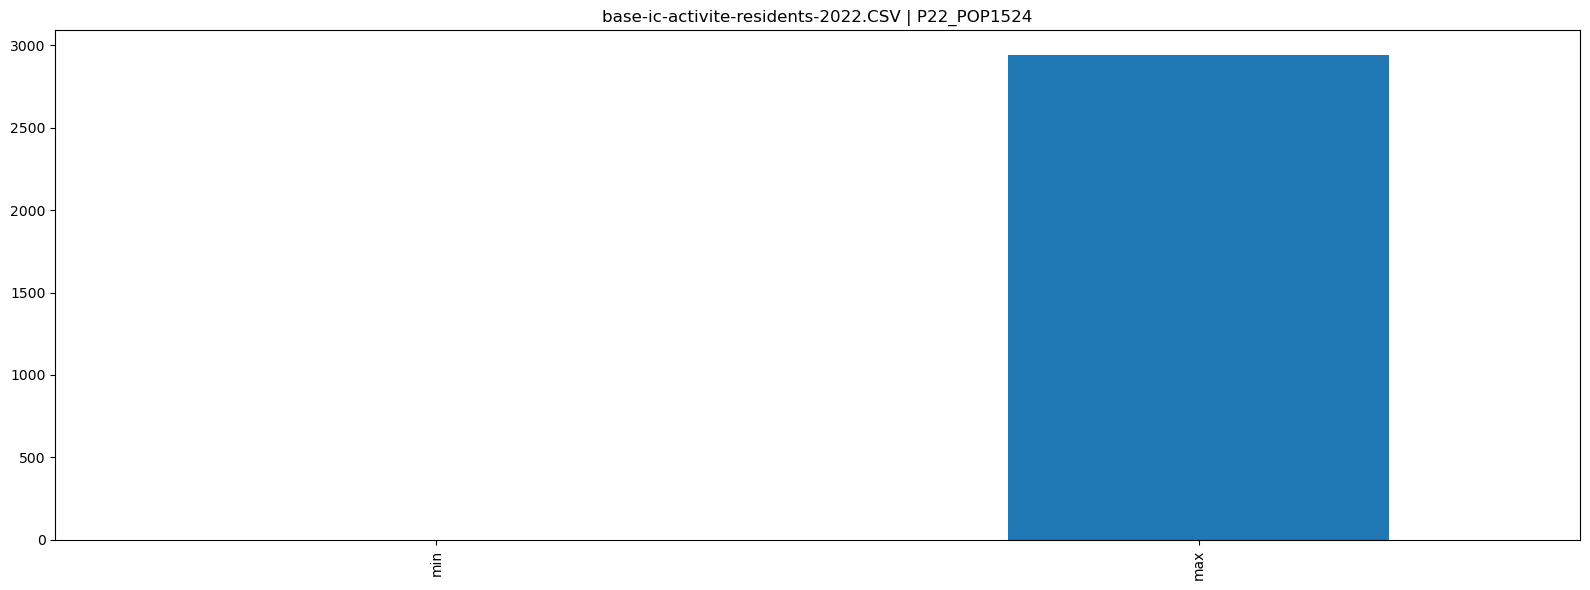

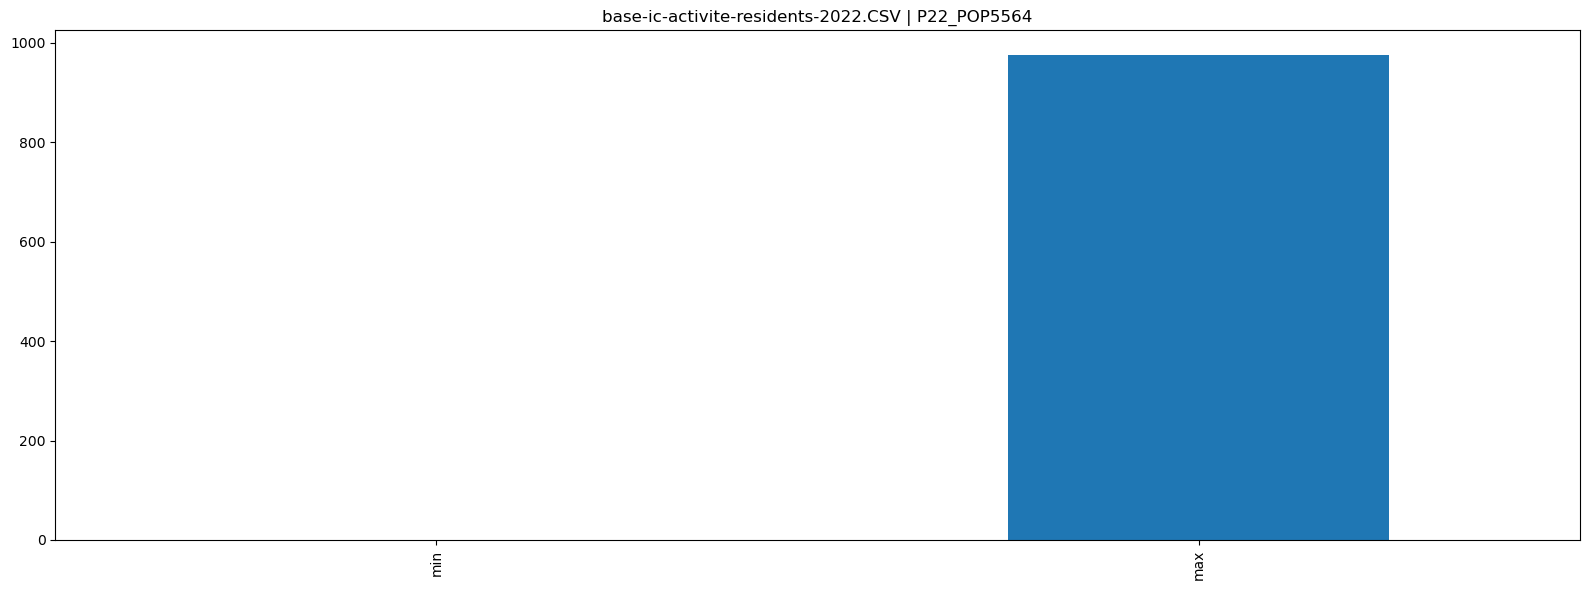

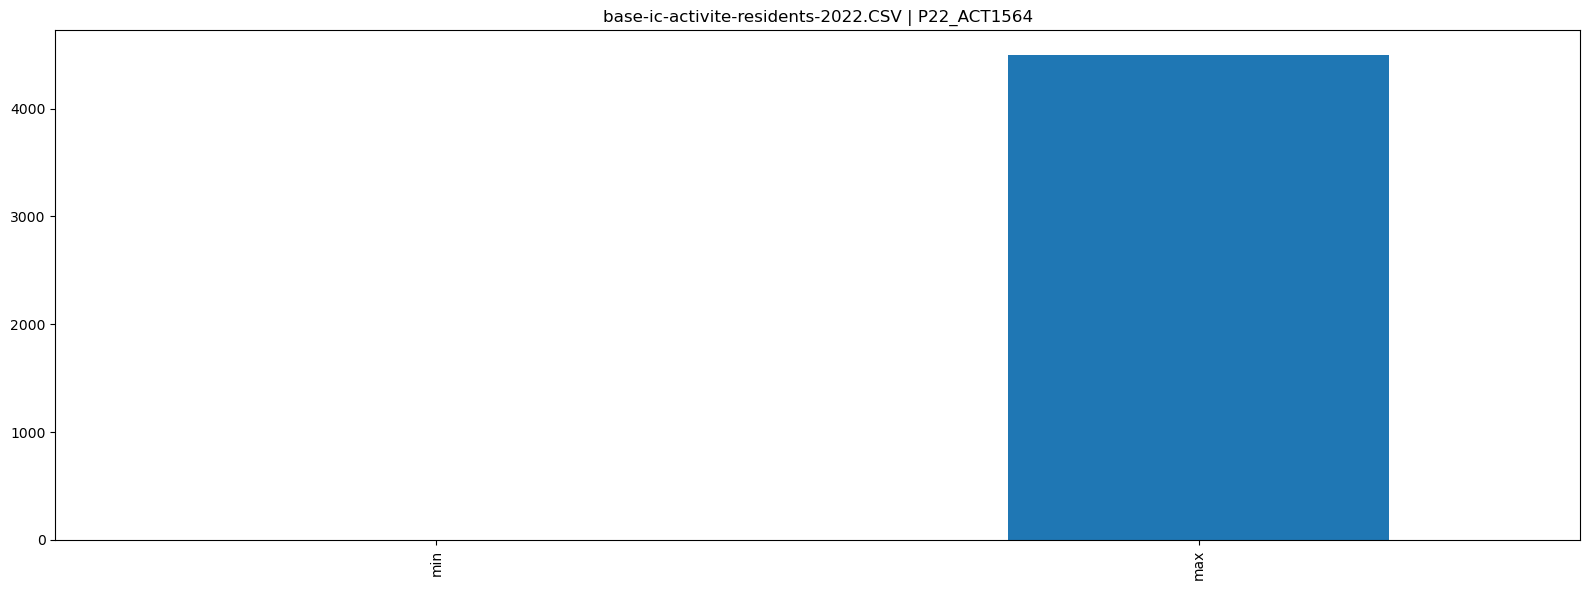

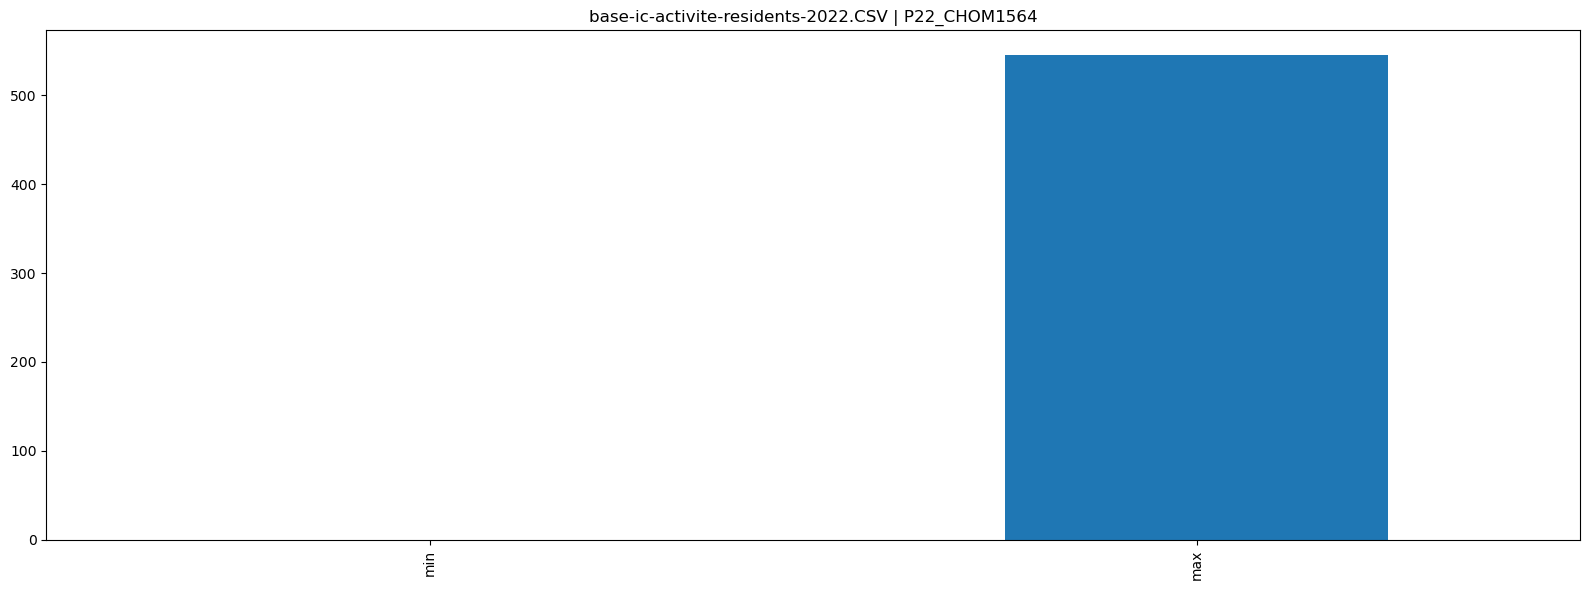

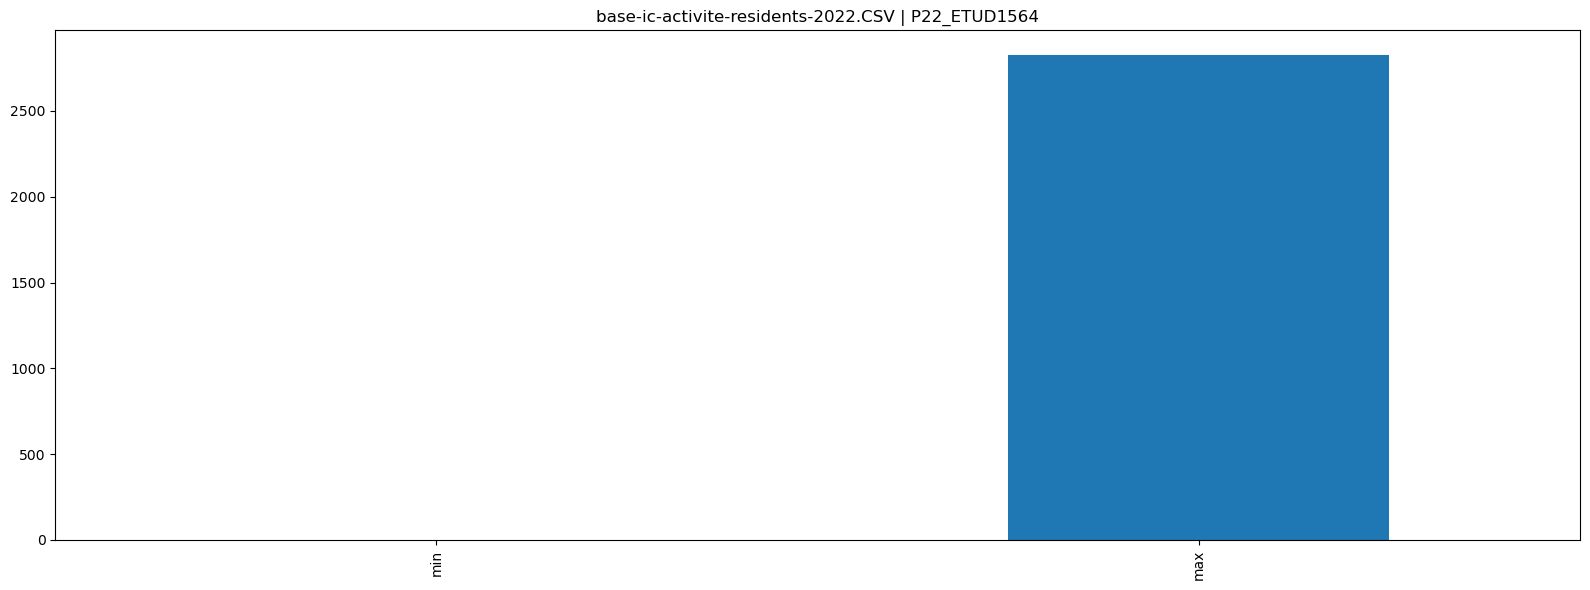

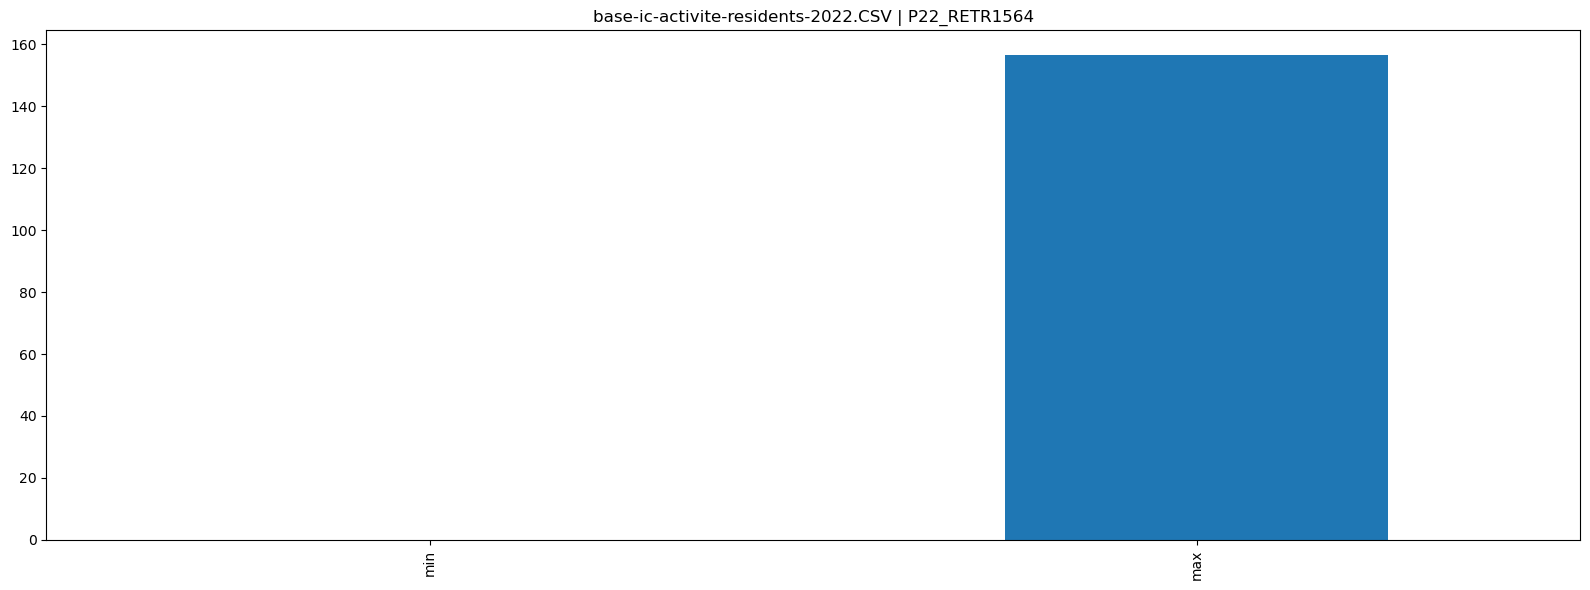

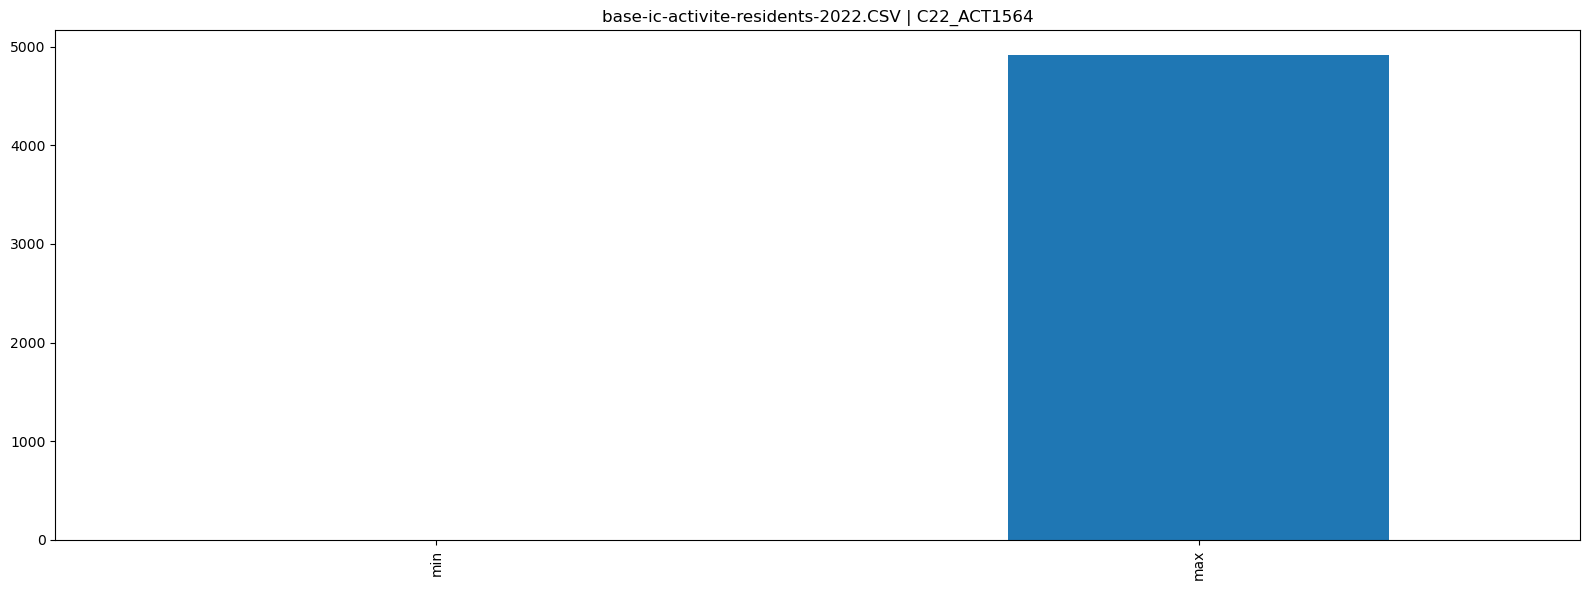

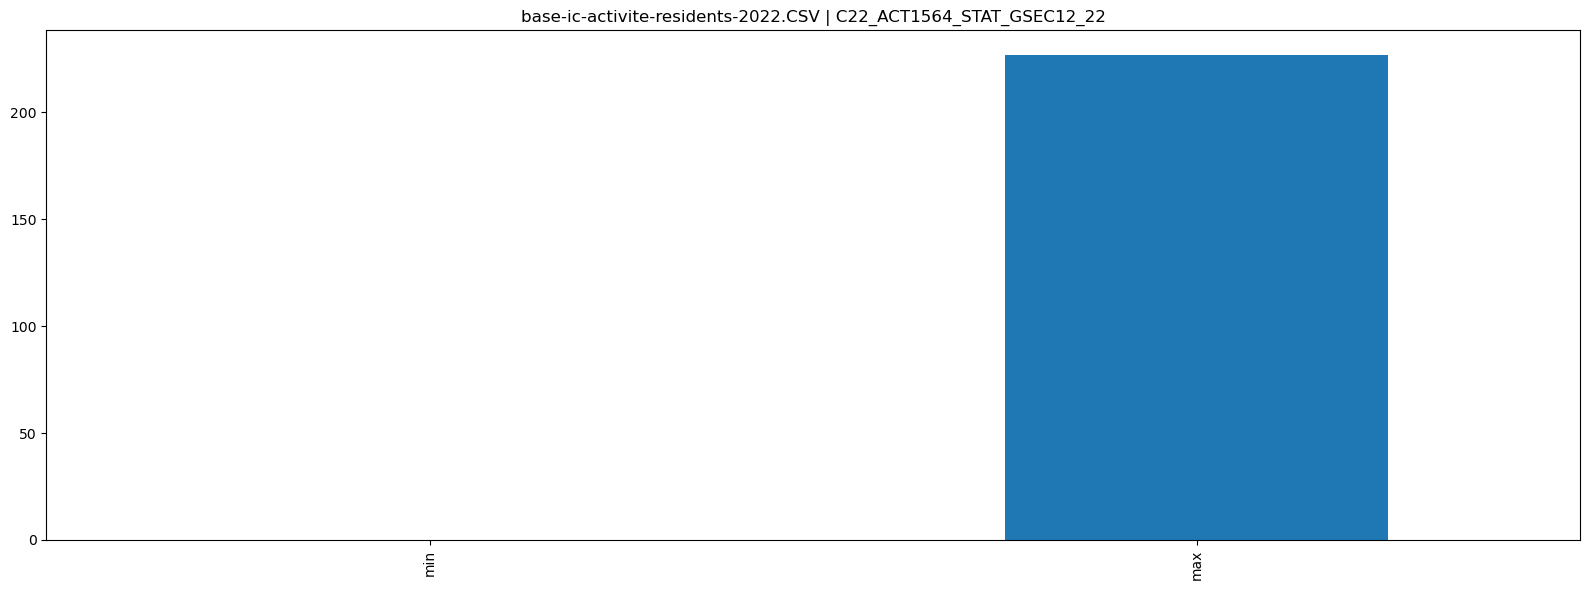

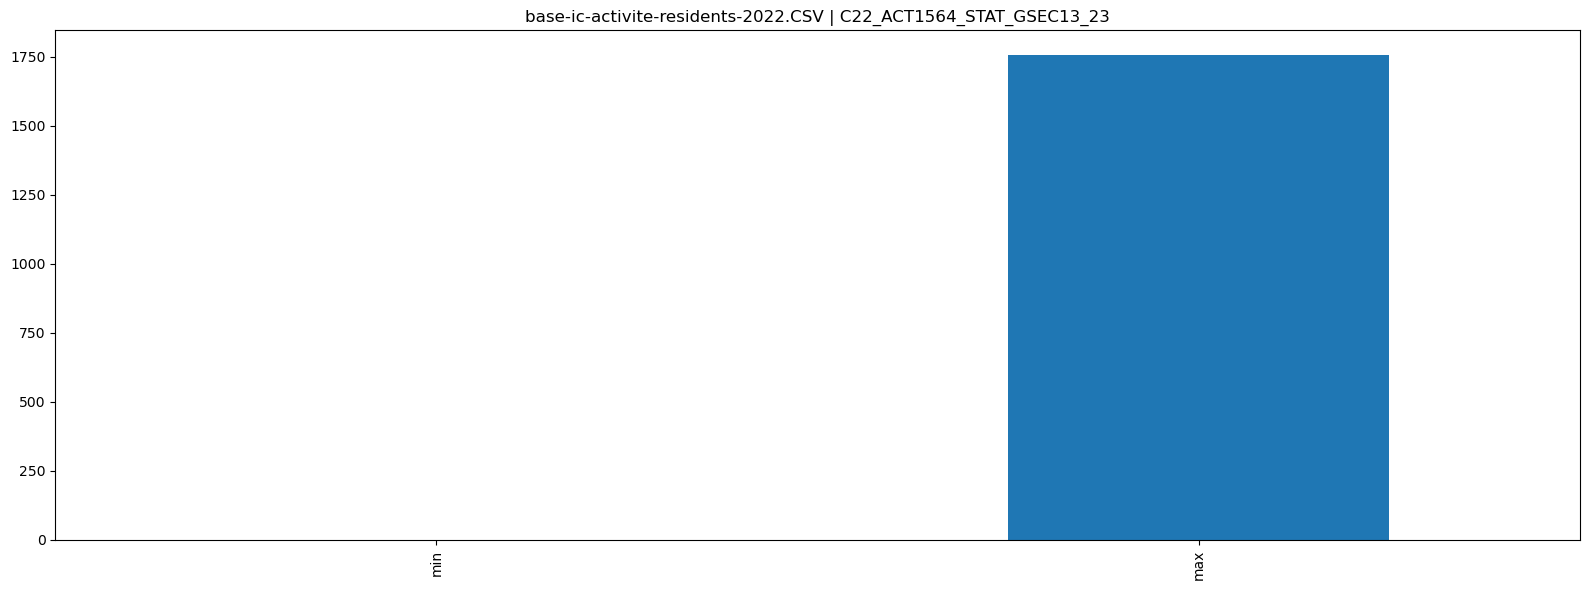

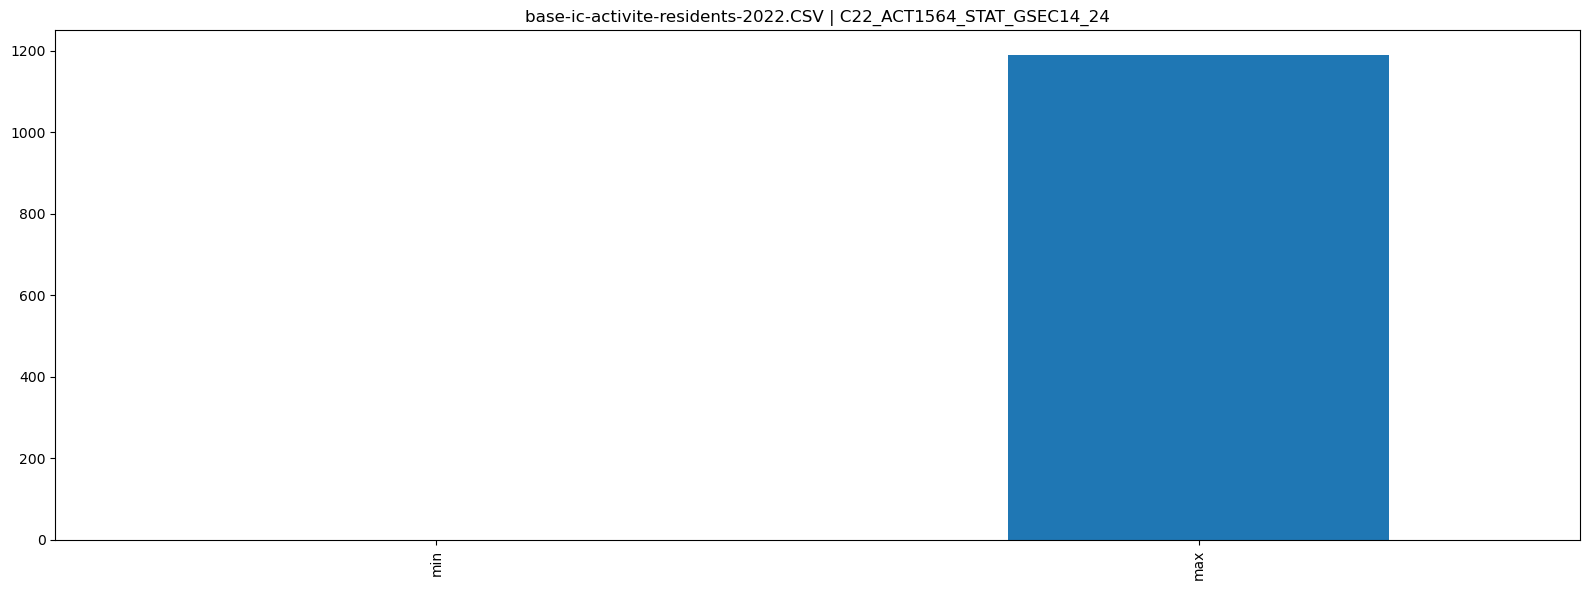

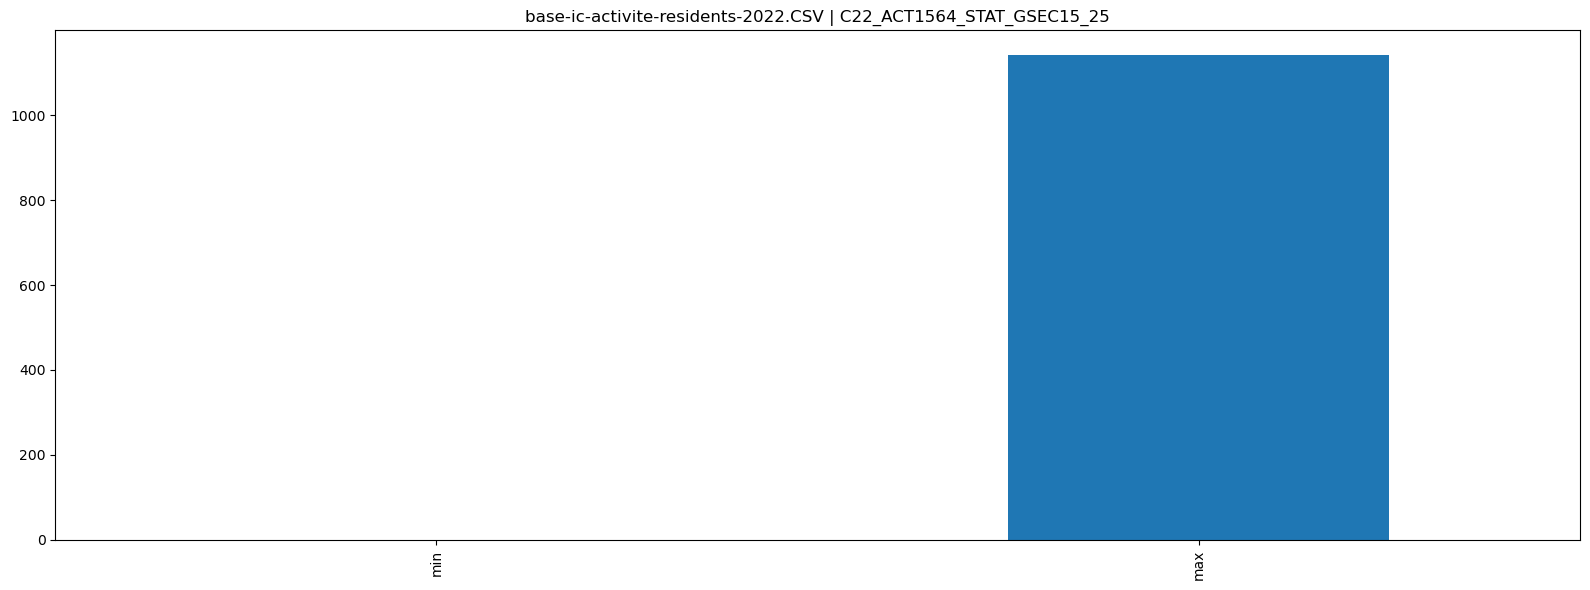

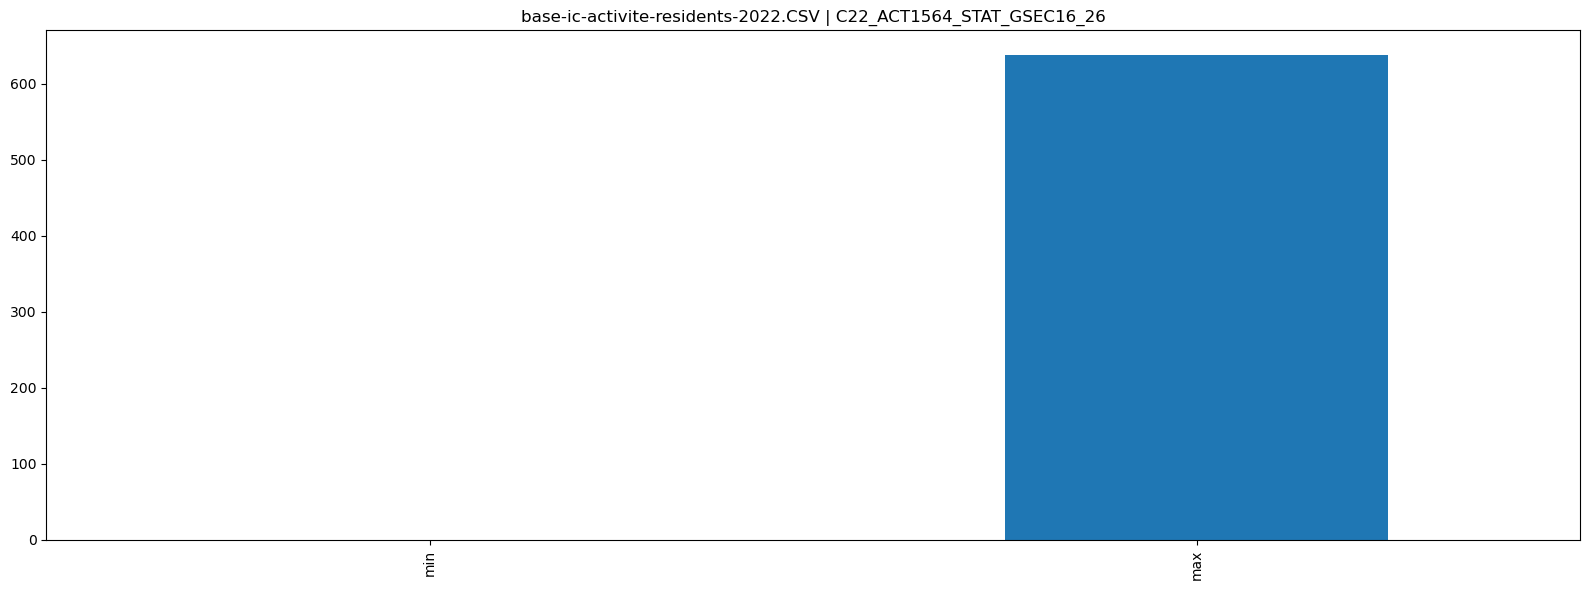

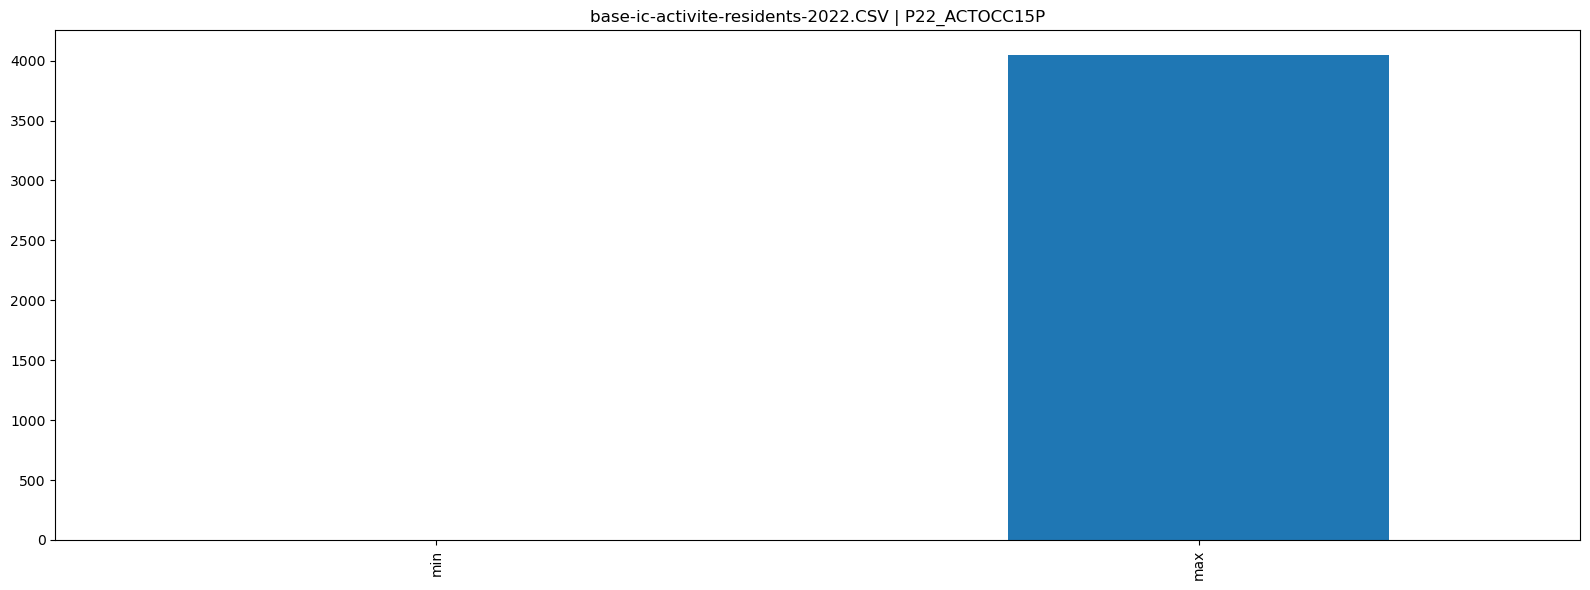

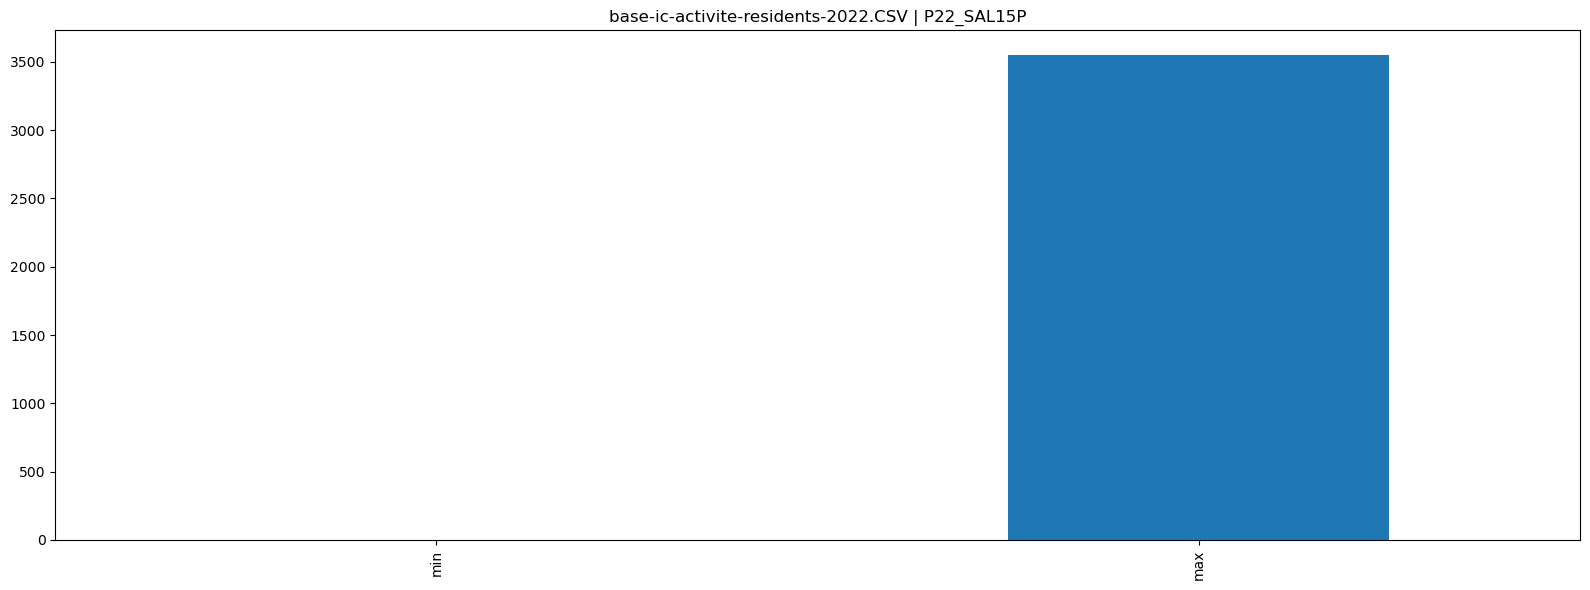

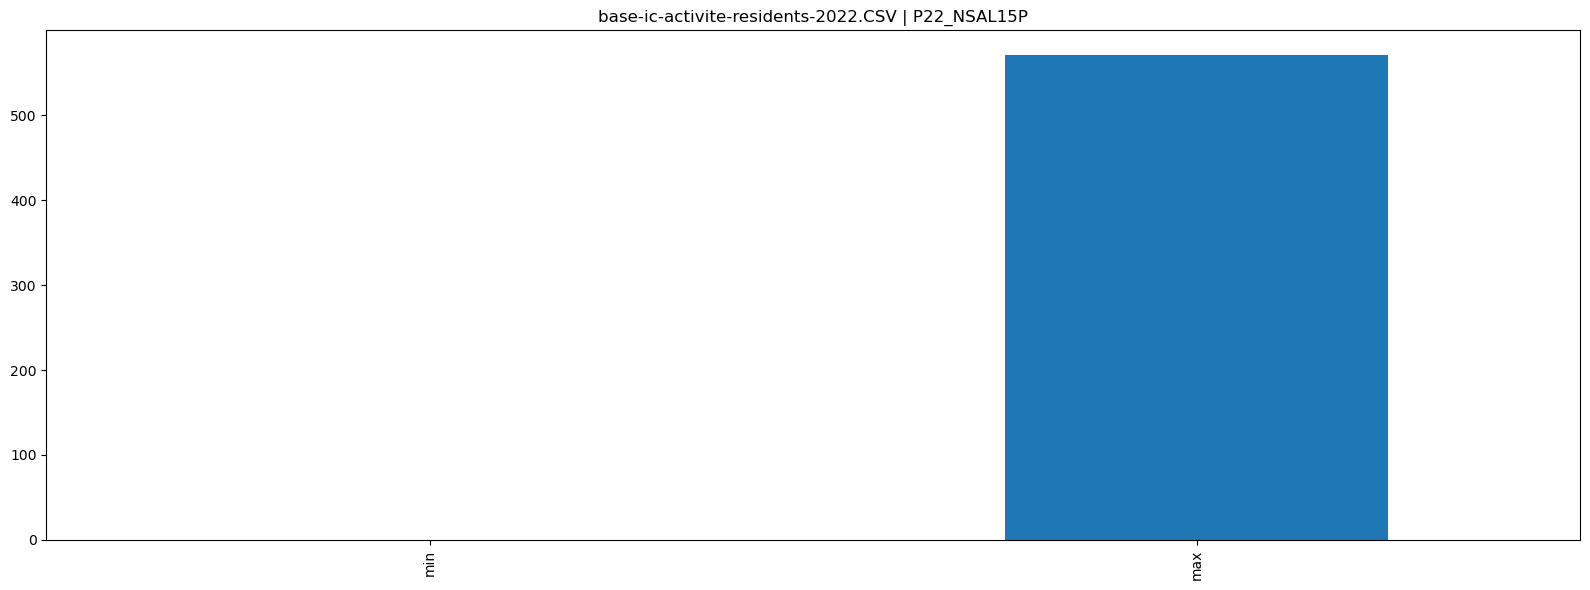

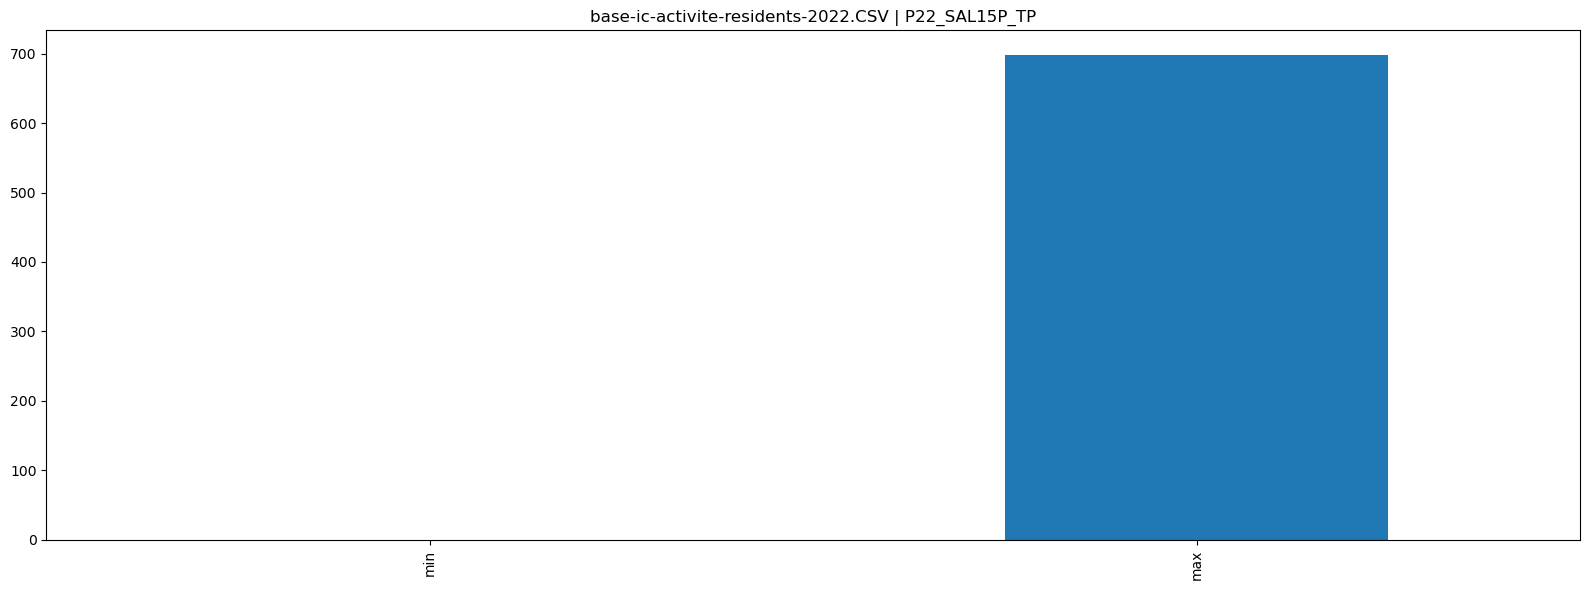

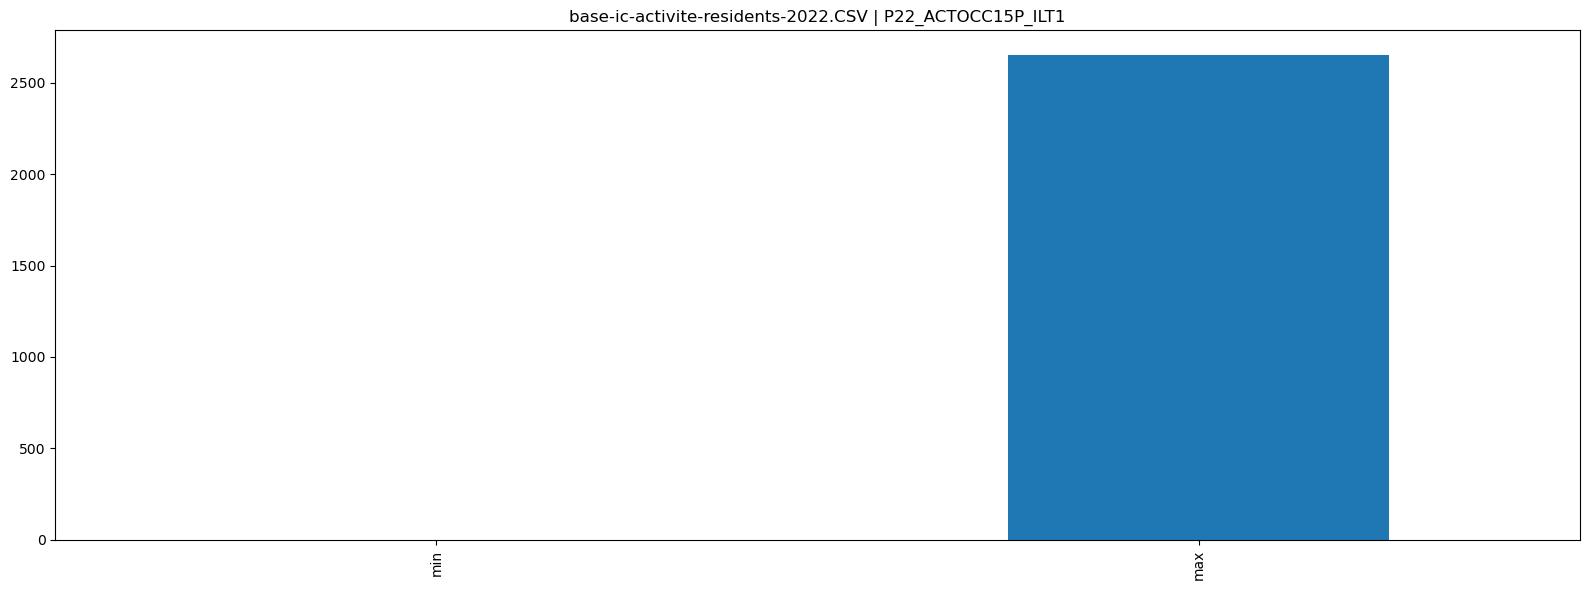

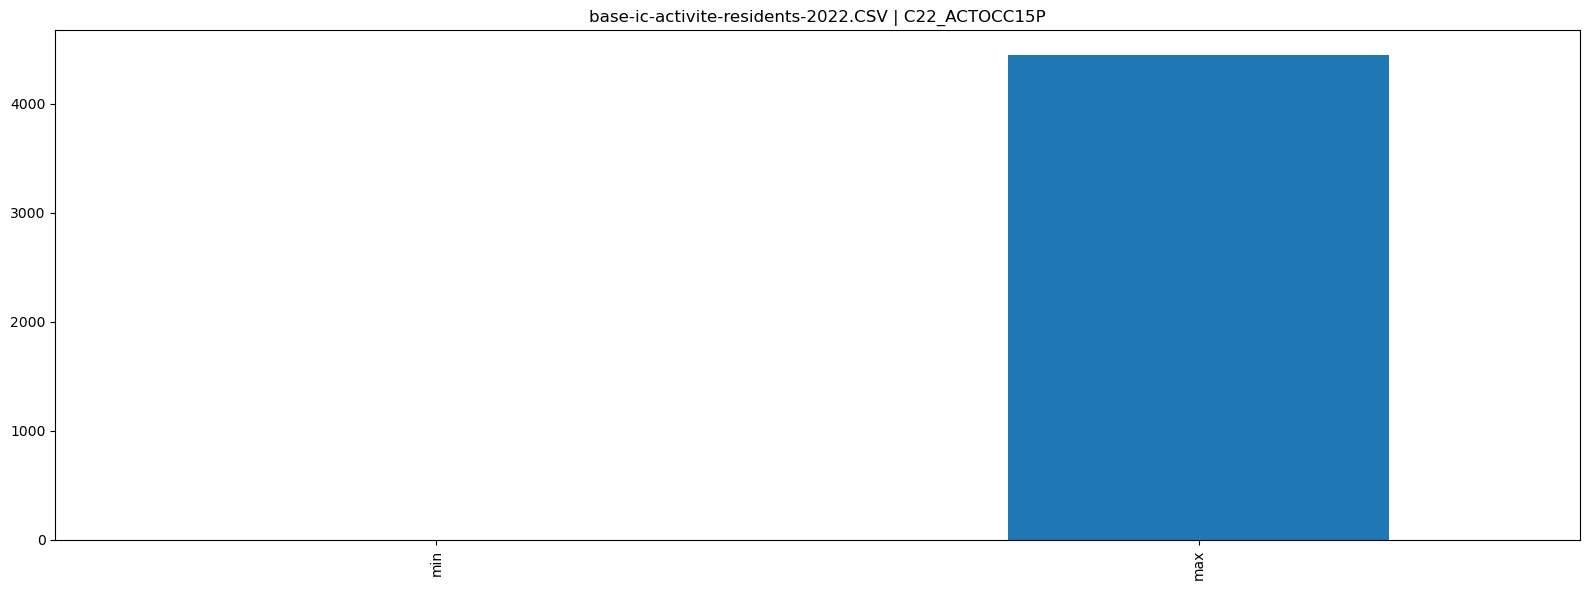

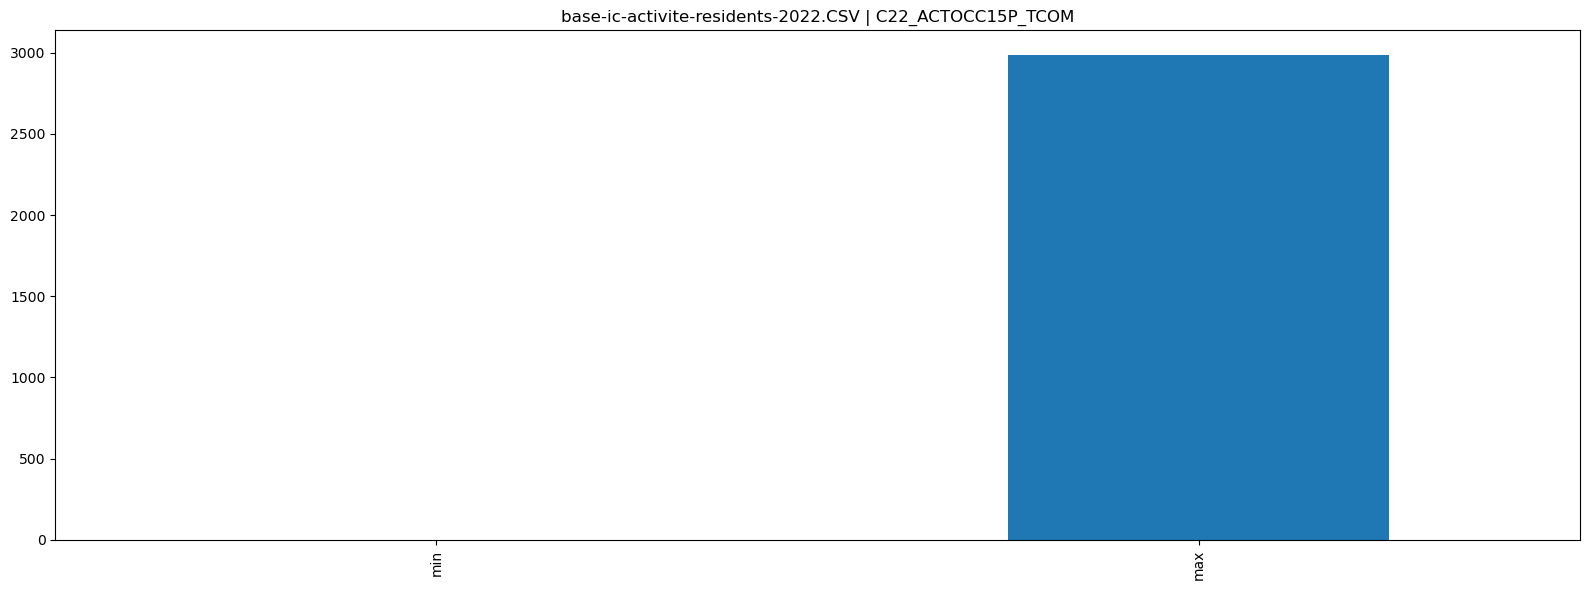

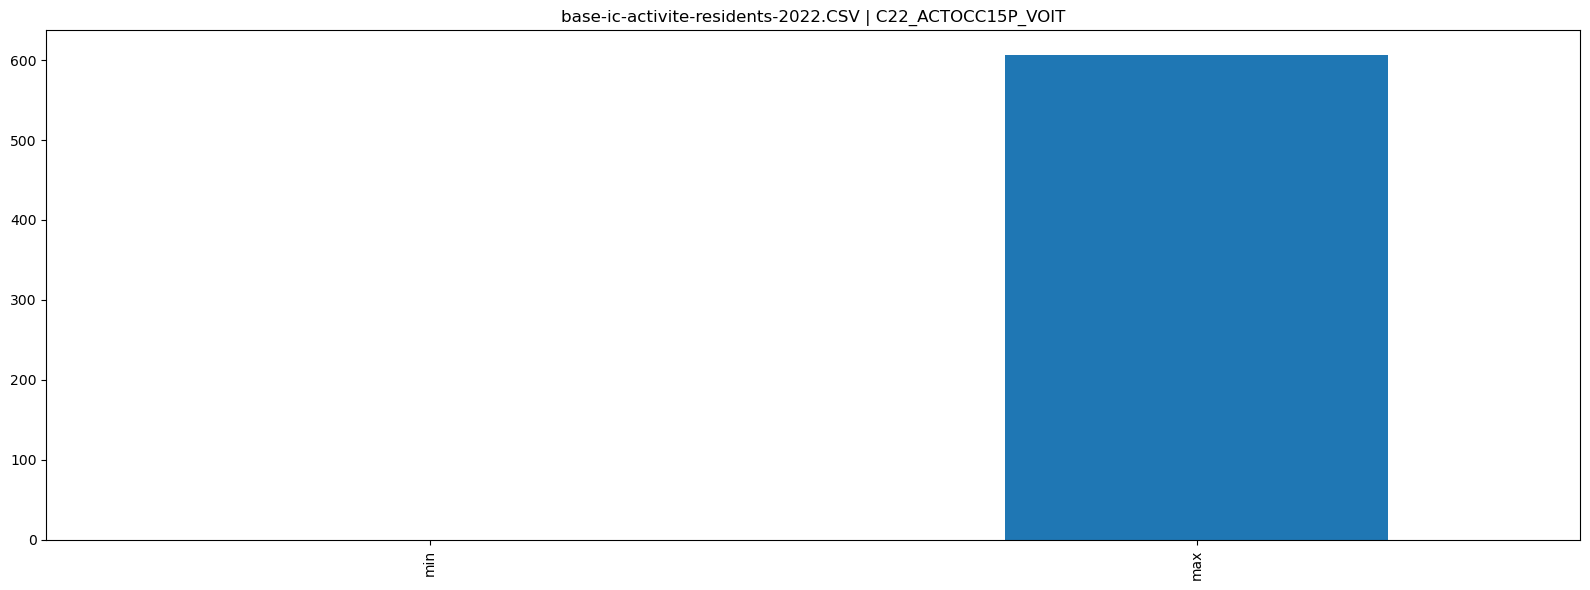

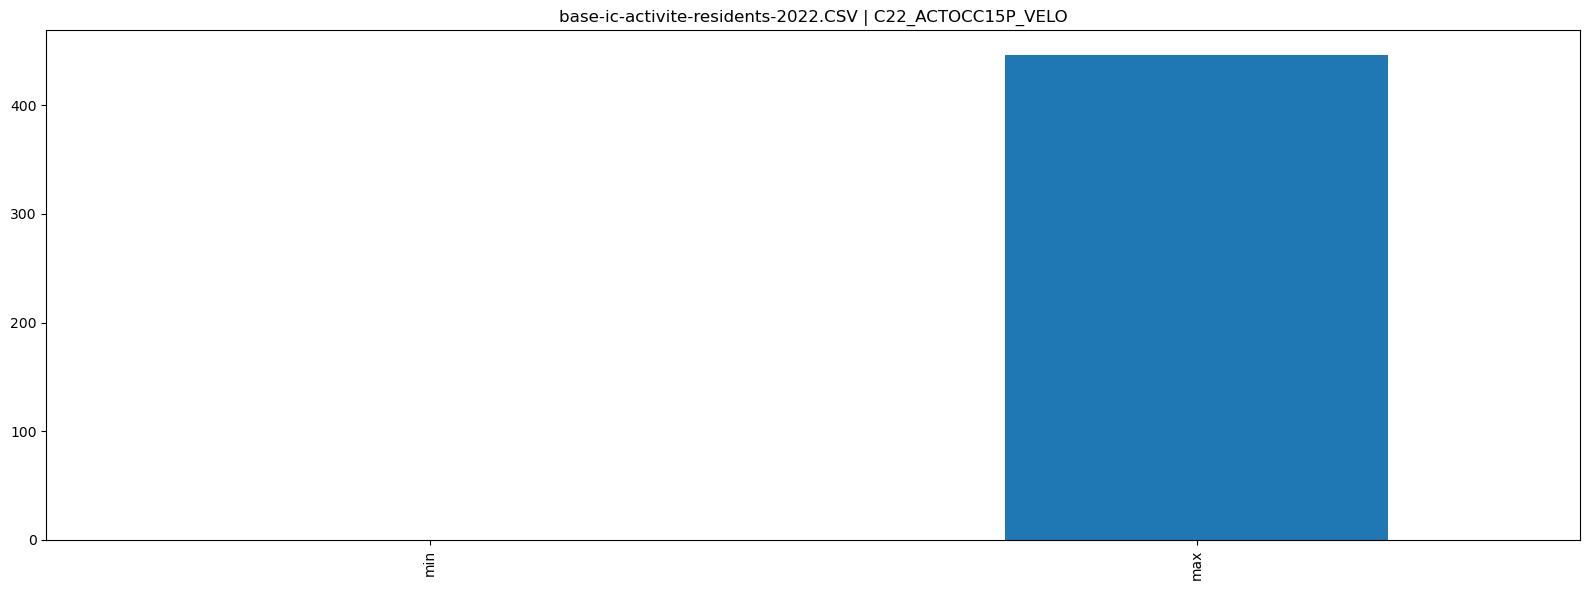

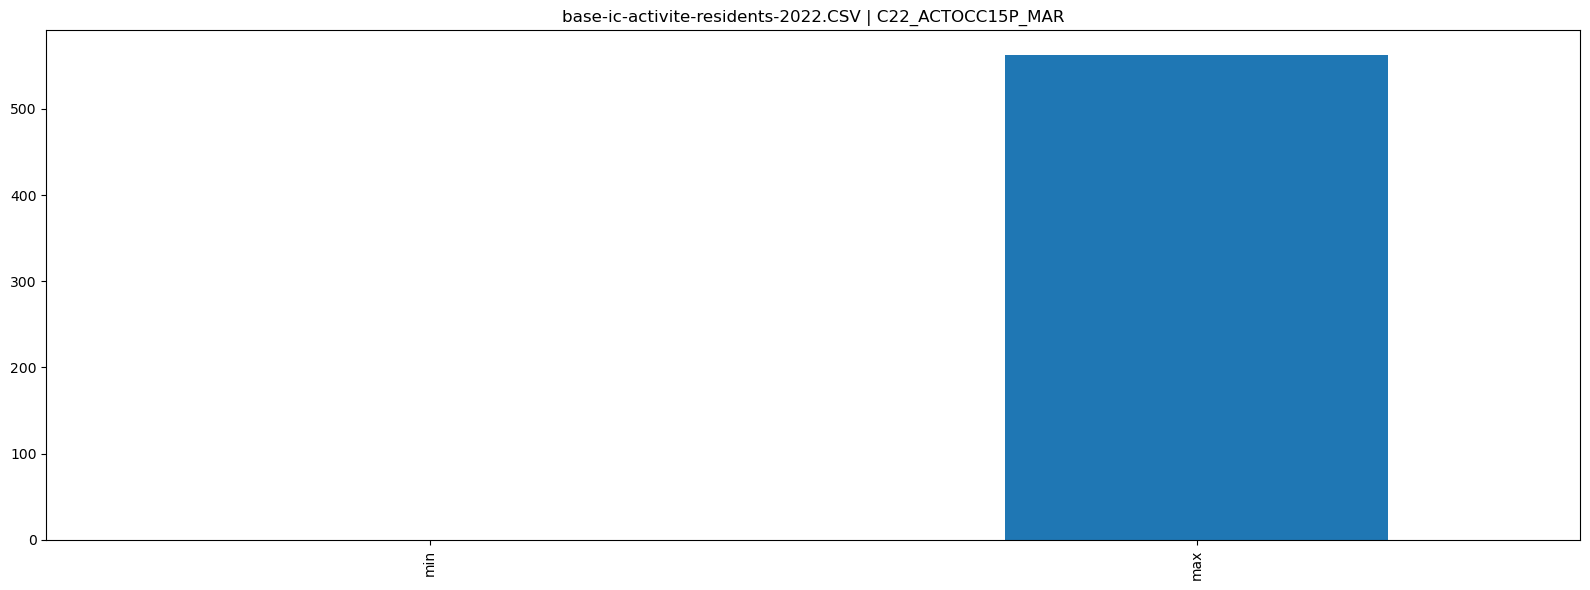

stops.txt : 5,242 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
stop_id,0.0,100.0,,,
stop_name,0.0,38.8,,,
stop_lon,0.0,96.6,,0.0,
stop_lat,0.0,96.6,,0.0,
location_type,0.0,0.1,,65.3,
parent_station,17.2,17.6,,,
wheelchair_boarding,0.0,0.1,,37.0,


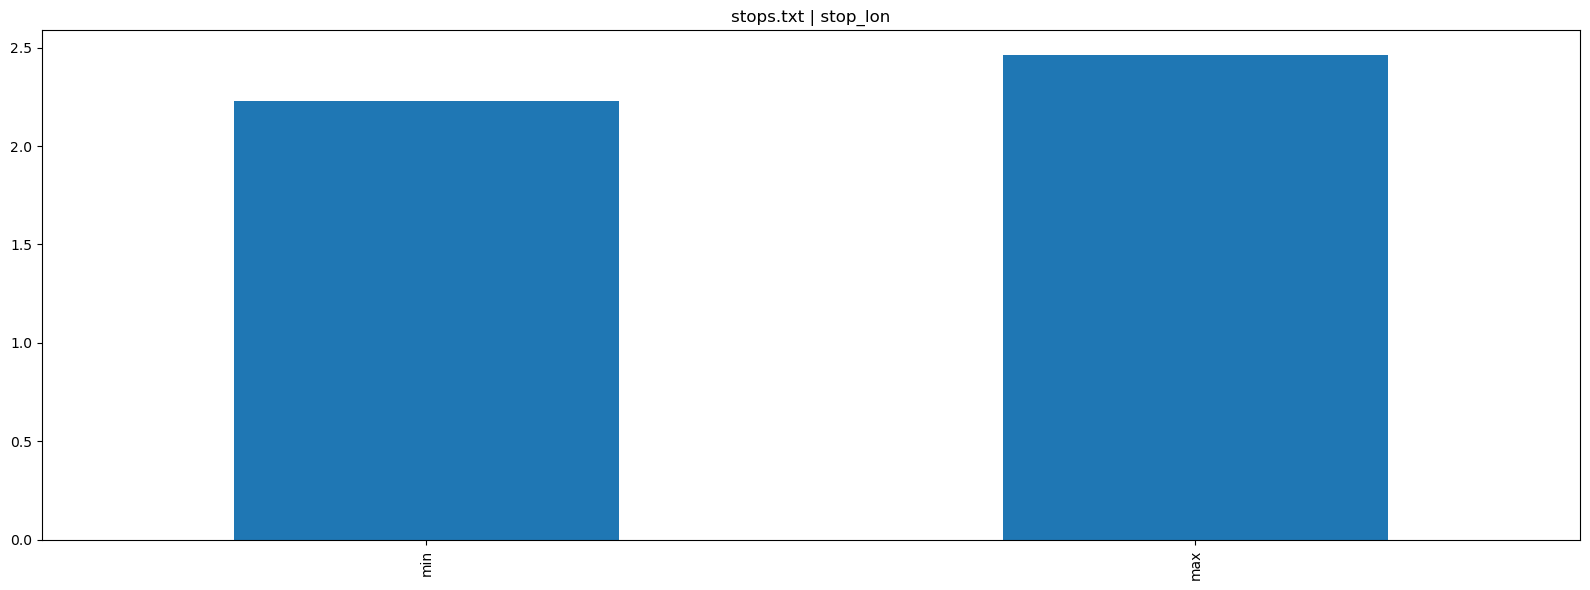

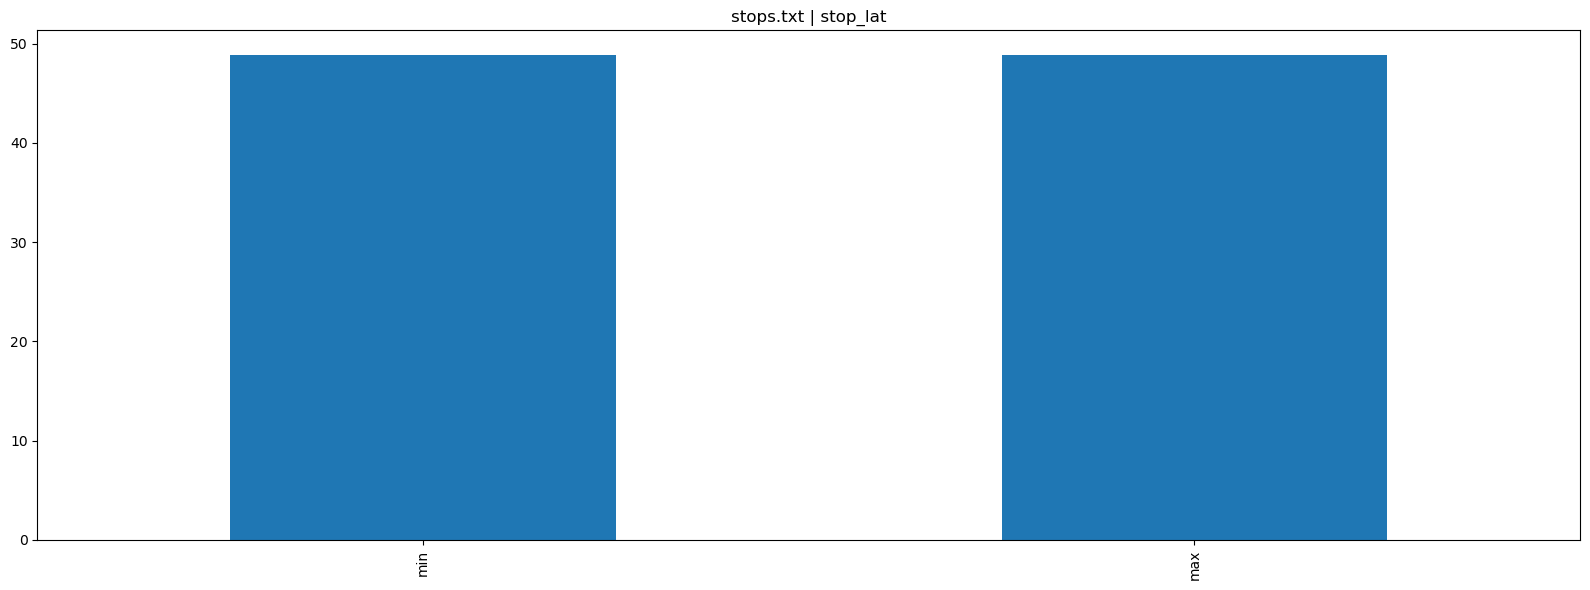

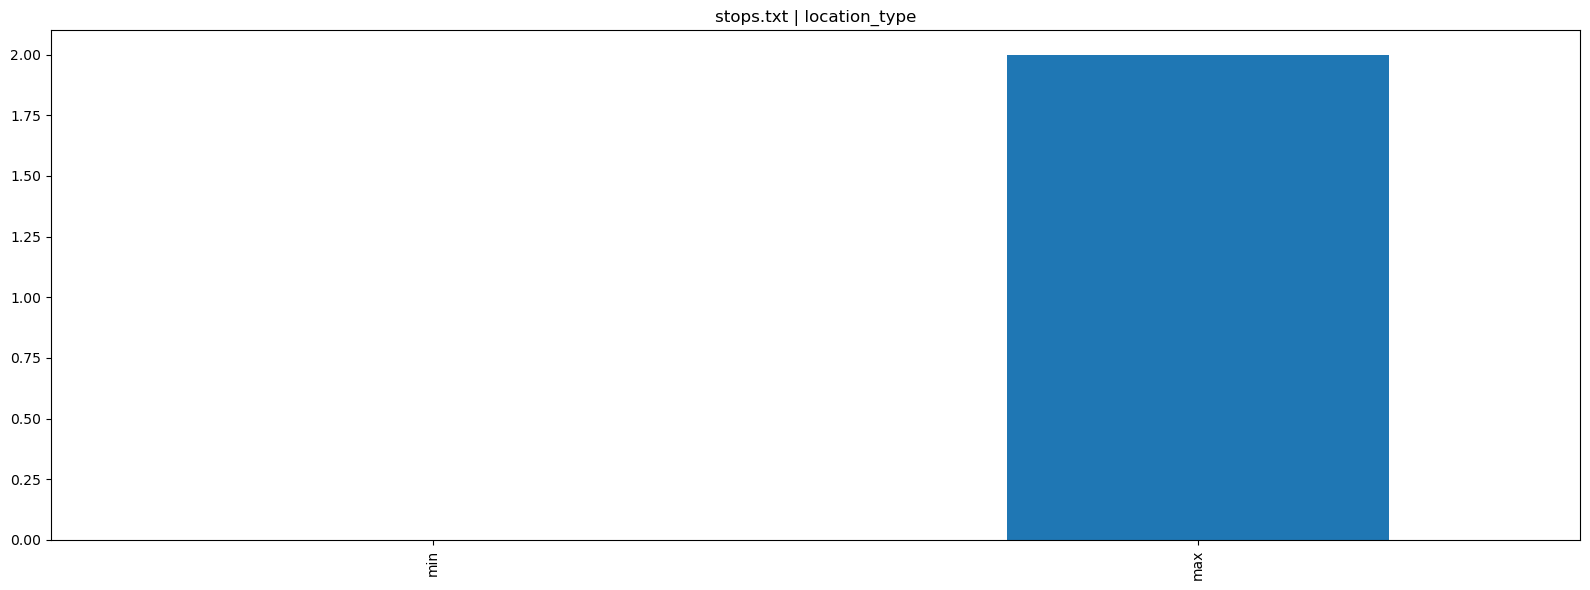

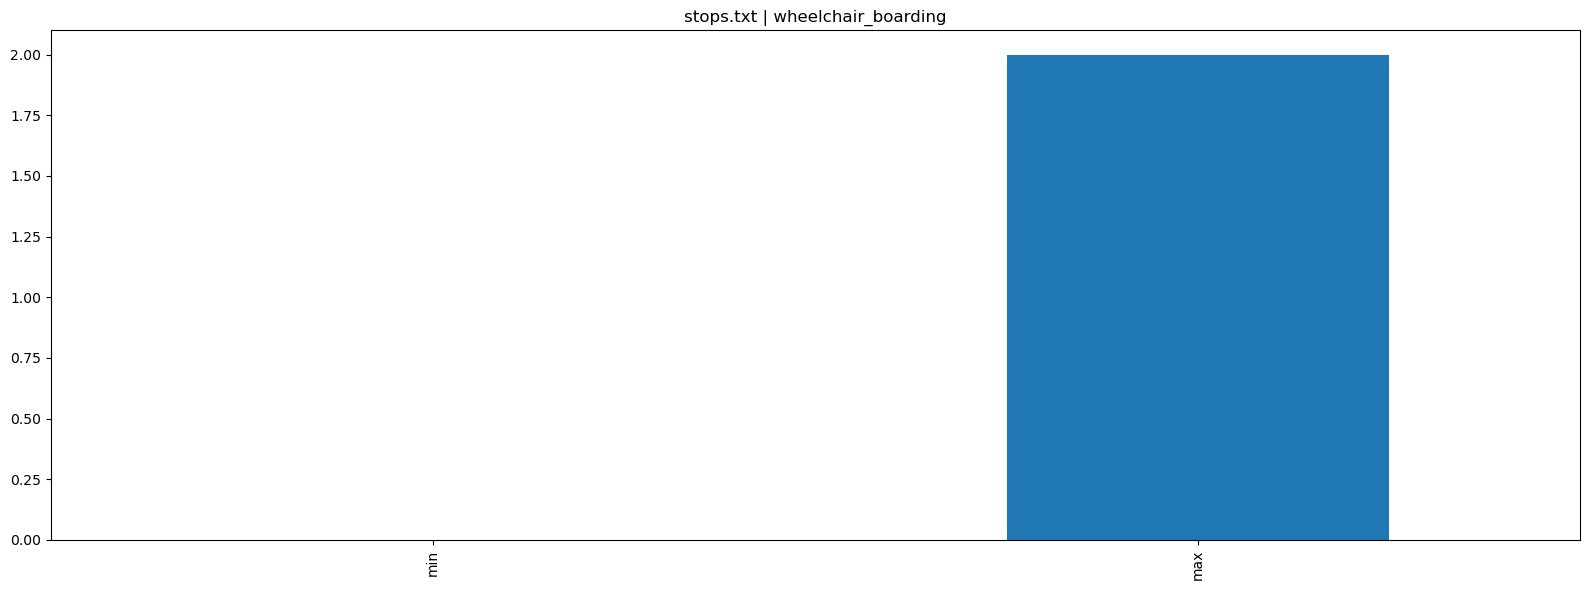

stop_times.txt : 2,065,725 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
stop_id,0.0,0.2,,,
trip_id,0.0,7.5,,,
departure_time,0.0,3.6,,,


trips.txt : 155,377 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
trip_id,0.0,100.0,,,
route_id,0.0,0.2,,,
service_id,0.0,0.4,,,


routes.txt : 253 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
route_id,0.0,100.0,,,
route_short_name,0.0,89.7,,,
route_type,0.0,2.0,,1.6,


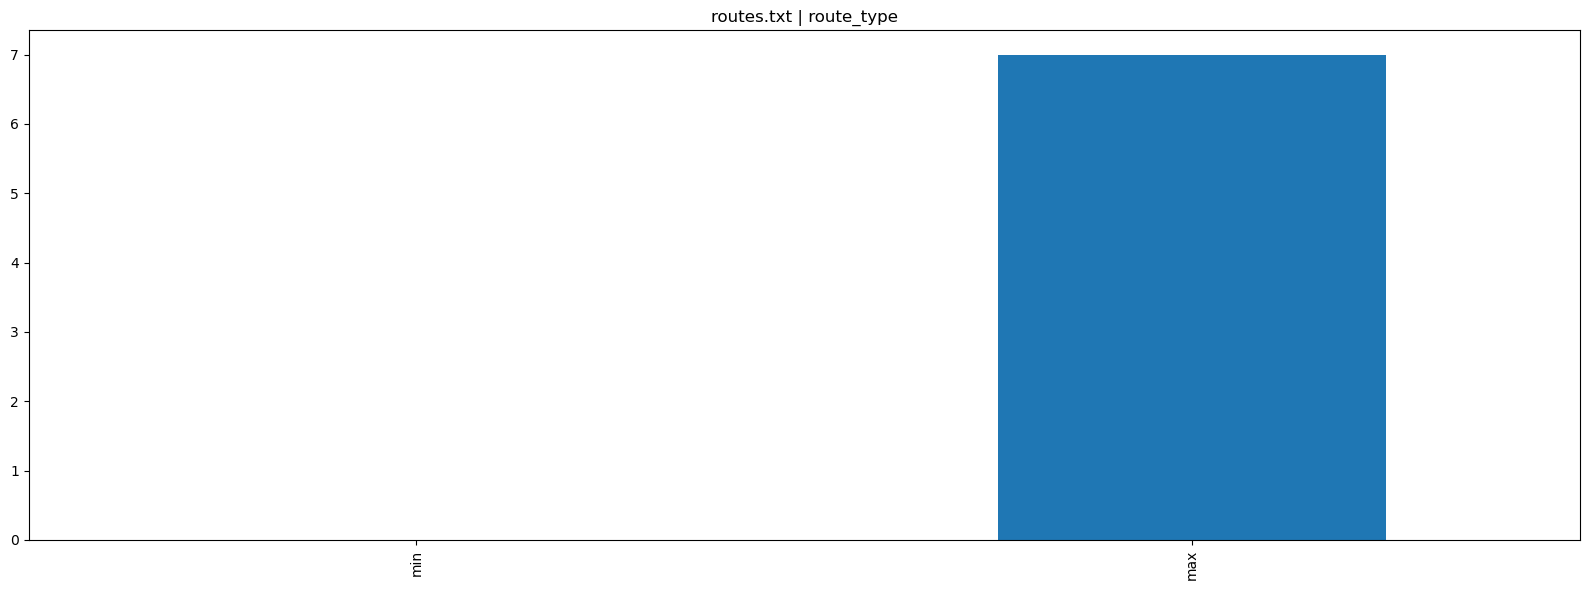

calendar.txt : 613 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
service_id,0.0,100.0,,,
monday,0.0,0.3,,51.5,
tuesday,0.0,0.3,,54.0,
wednesday,0.0,0.3,,57.3,
thursday,0.0,0.3,,53.2,
friday,0.0,0.3,,53.0,
saturday,0.0,0.3,,60.4,
sunday,0.0,0.3,,58.7,
start_date,0.0,5.2,,0.0,
end_date,0.0,5.4,,0.0,


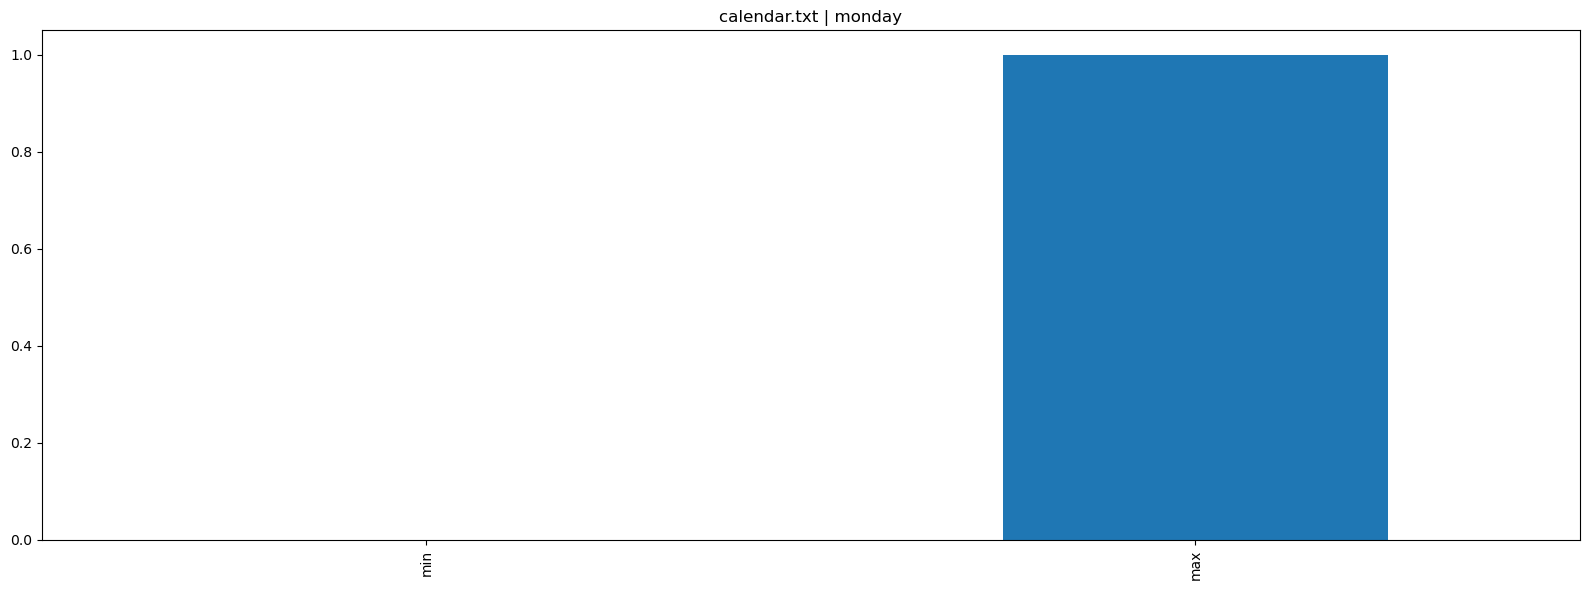

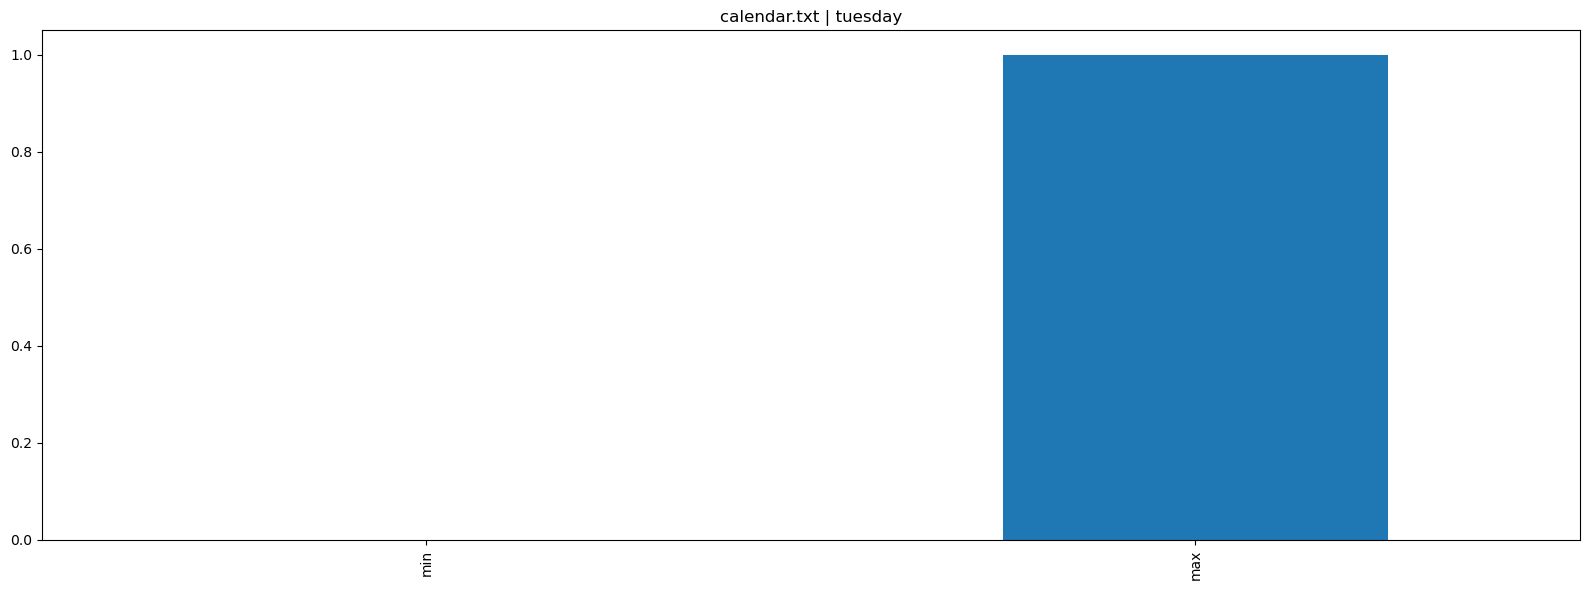

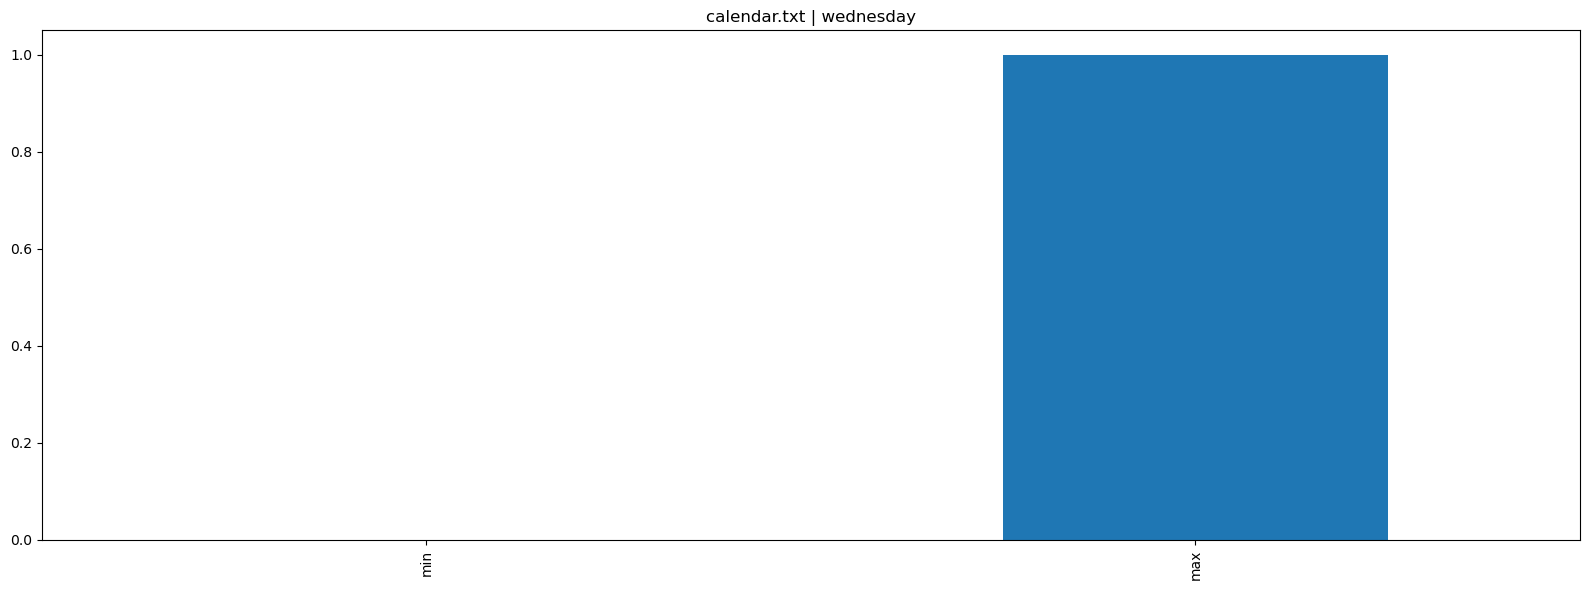

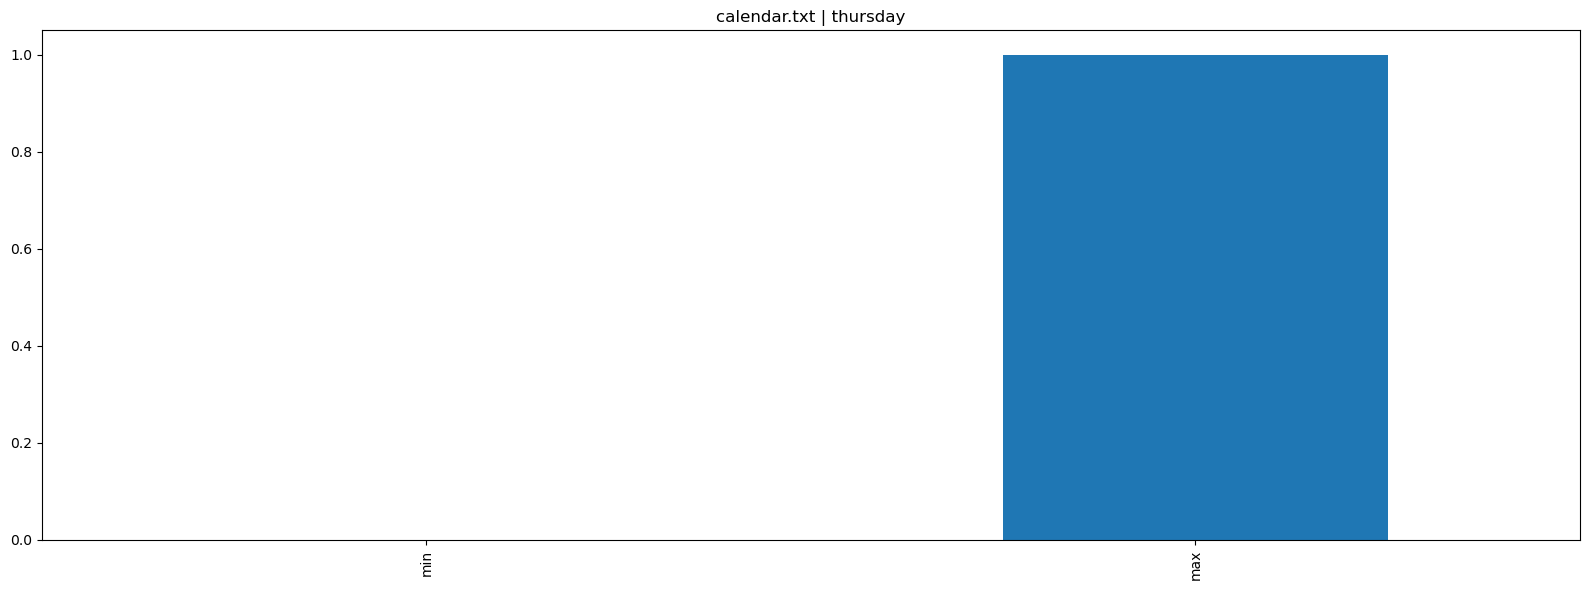

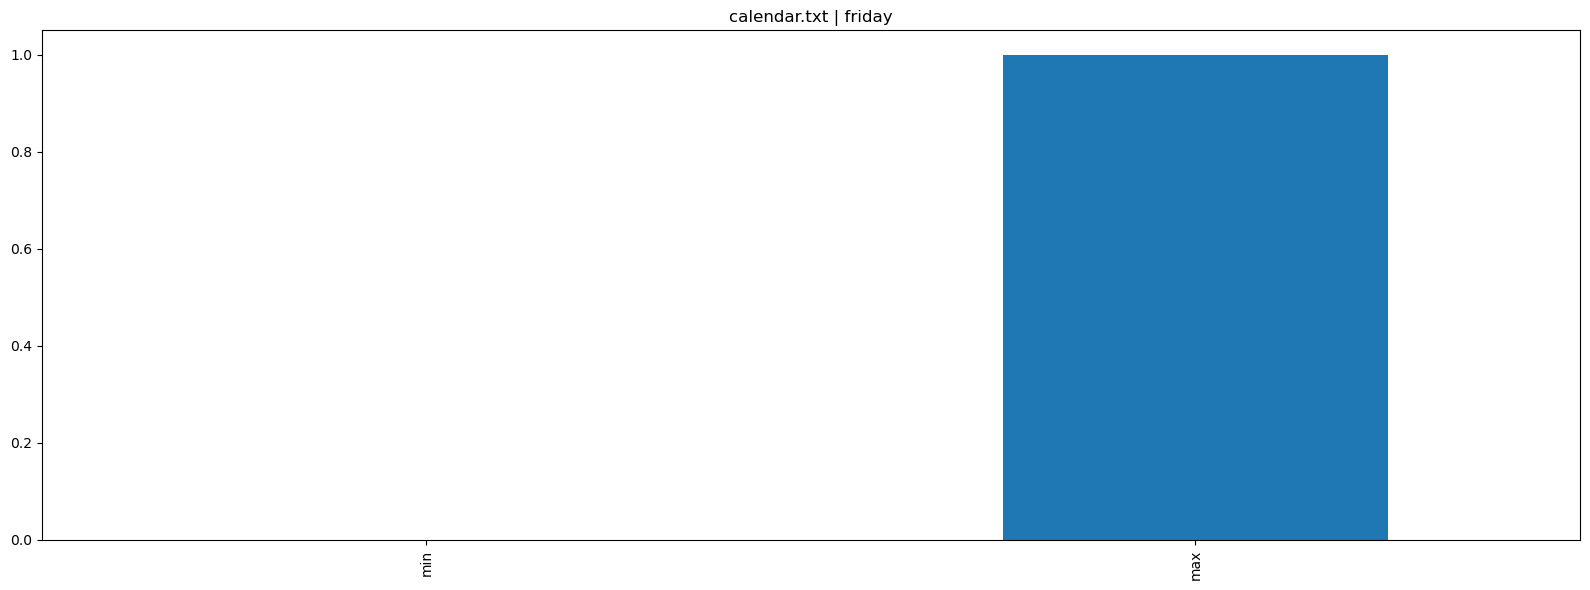

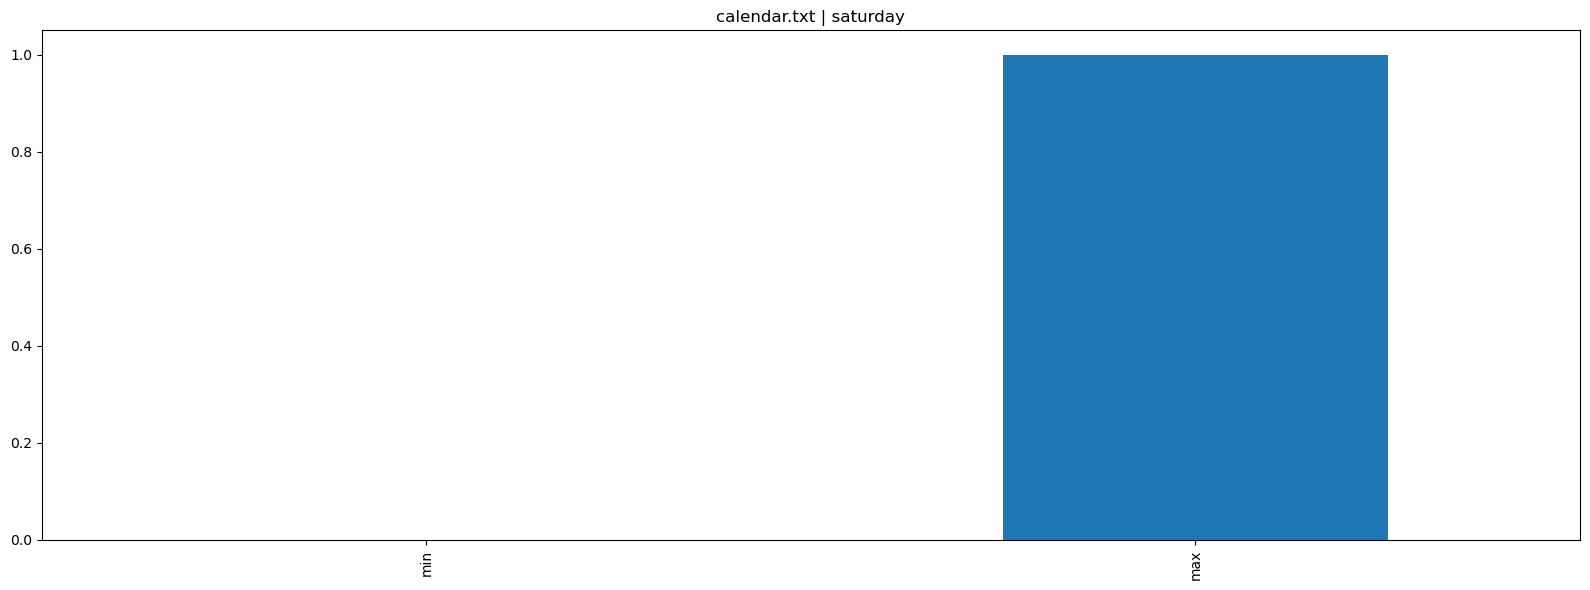

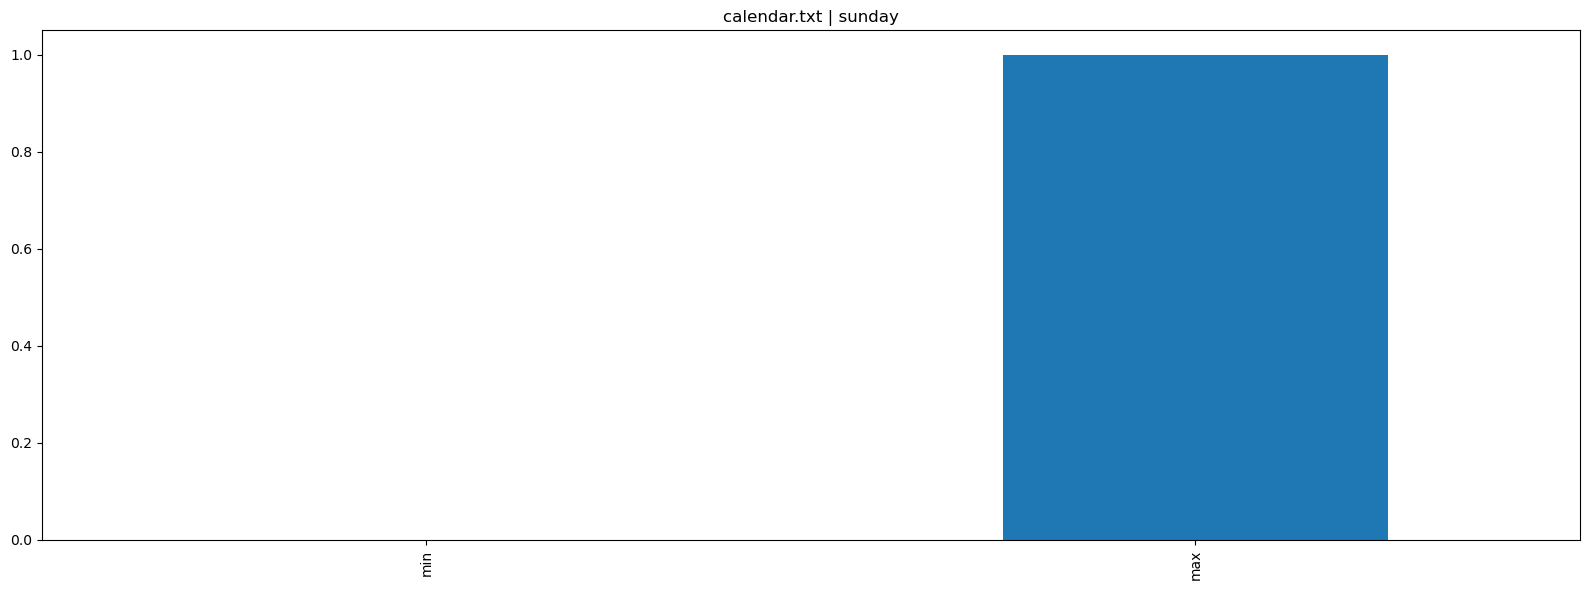

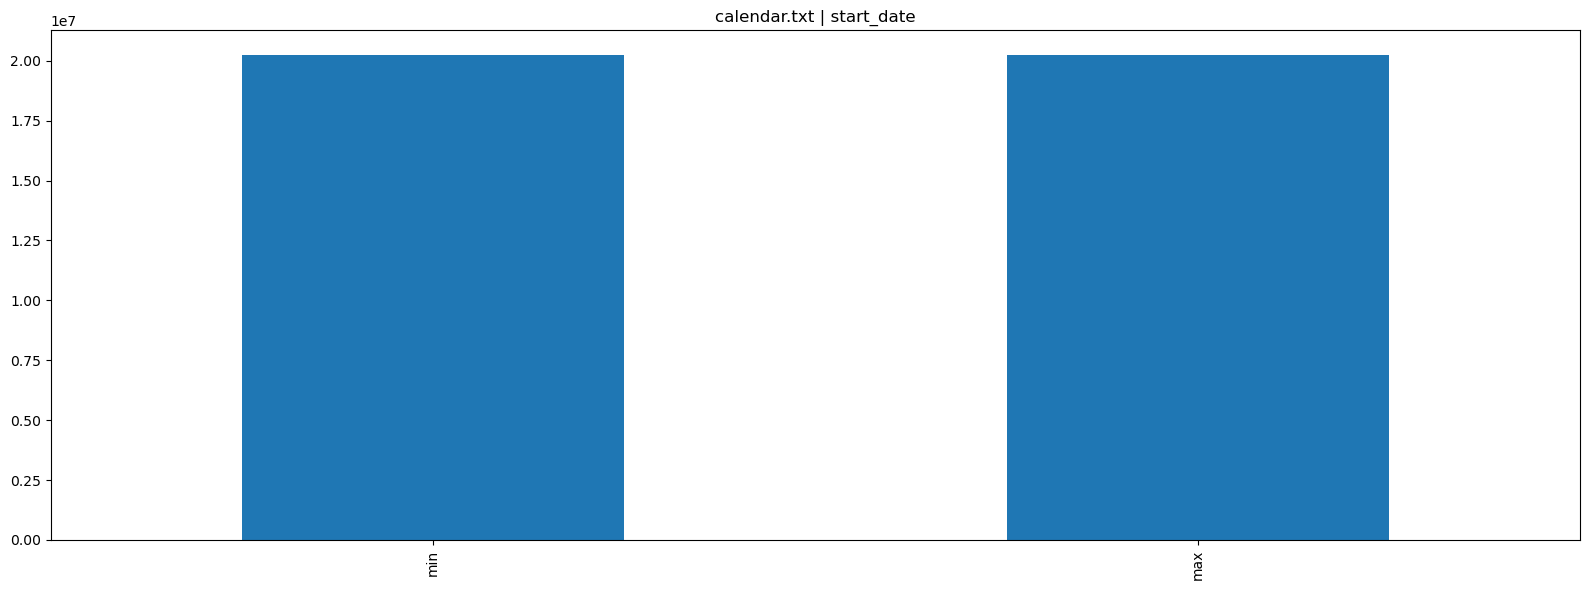

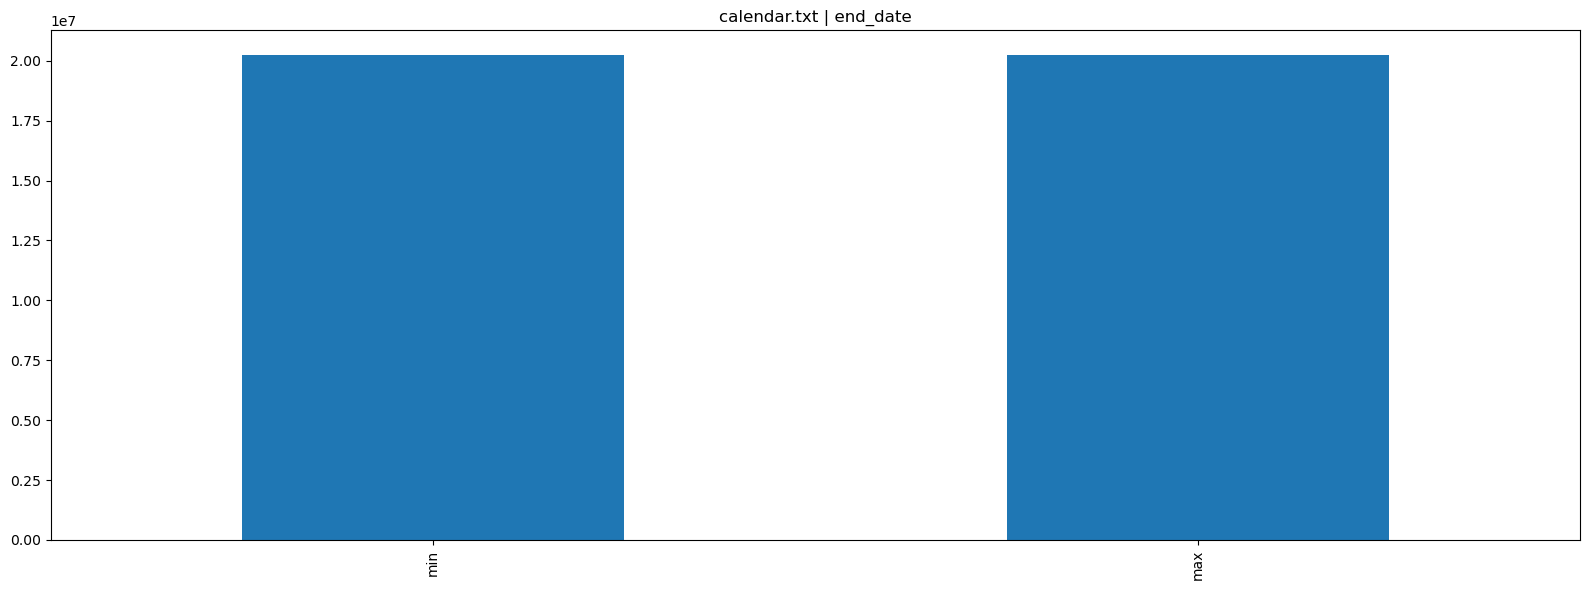

calendar_dates.txt : 1,266 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
service_id,0.0,32.8,,,
date,0.0,2.2,,0.0,
exception_type,0.0,0.2,,0.0,


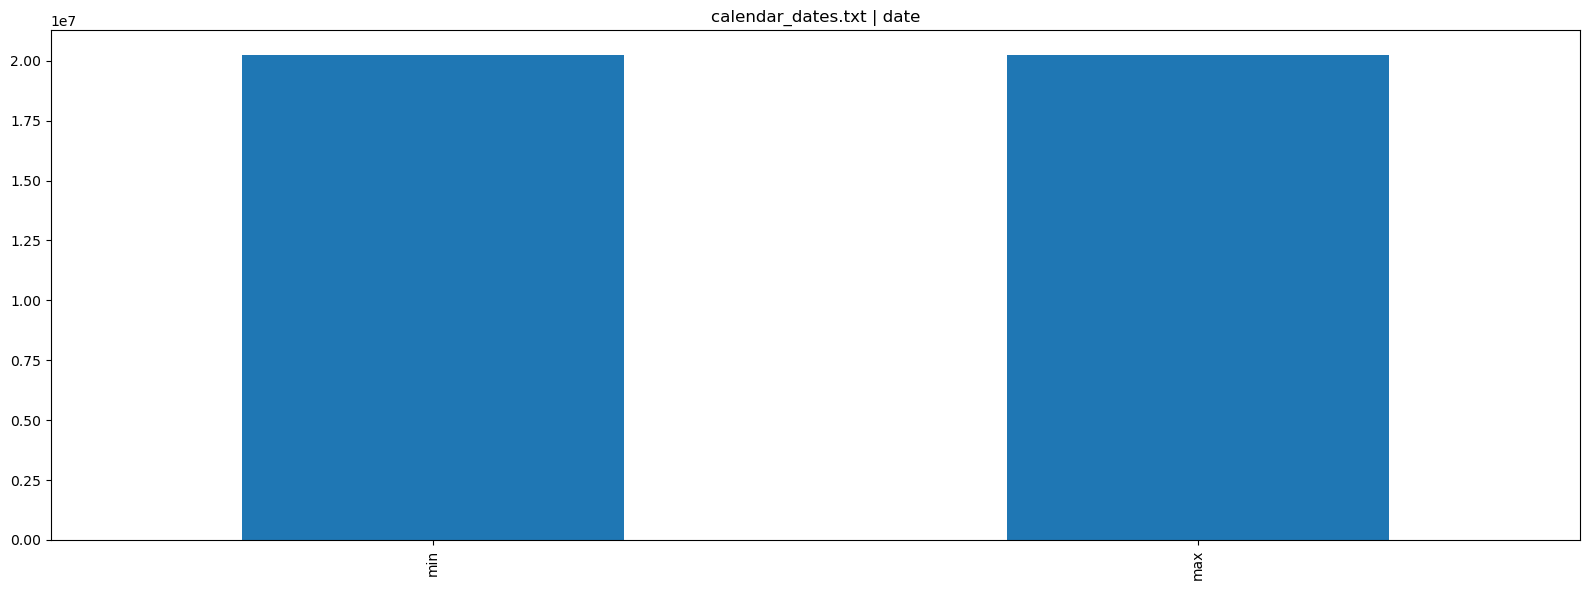

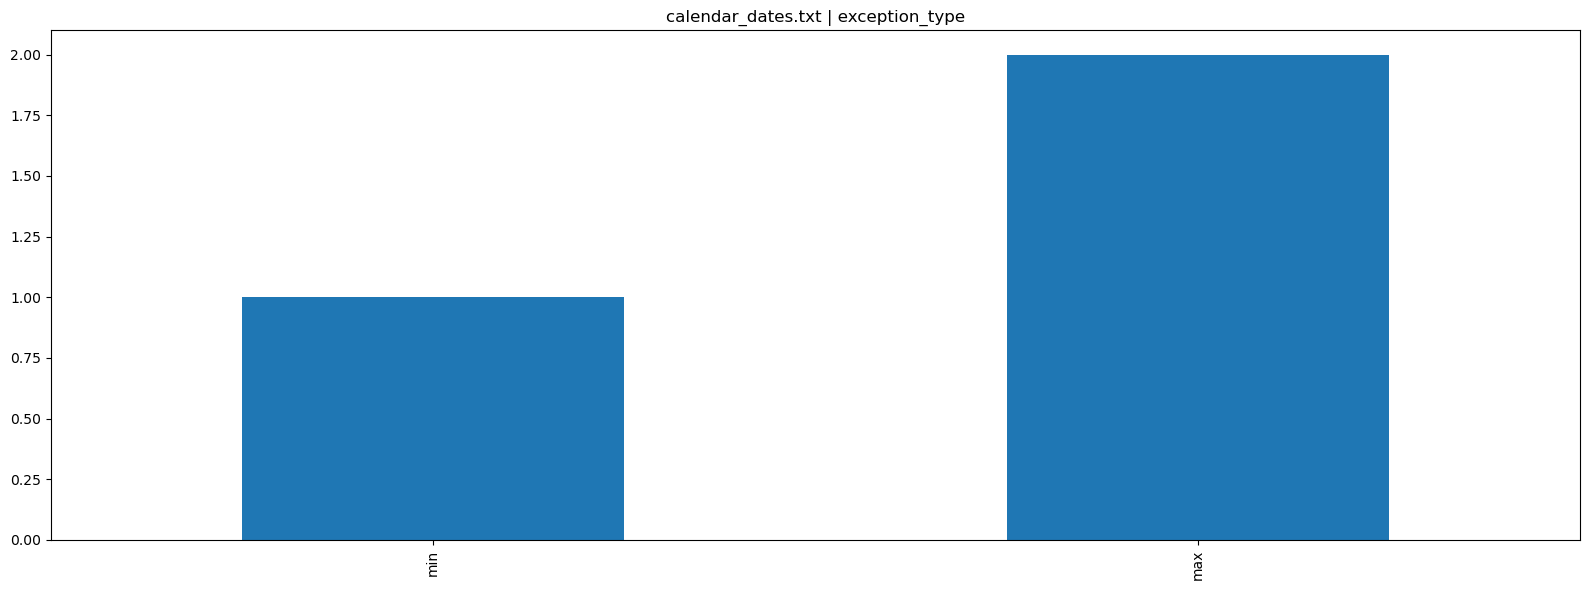

In [8]:
#Graphiques généré par IA pour visualiser les données
PCT_METRICS = ["num_missing", "num_unique", "num_unique_normalized", "num_zeros", "num_convertible_numeric"]
STAT_METRICS = ["min", "max"]

def pct_table(prof, metrics=PCT_METRICS):
    return pd.DataFrame(prof["columns"]).T[metrics].astype(float) / prof["num_rows"] * 100

def plot_quality_heatmap(prof):
    print(f"{prof['name_df']} : {prof['num_rows']:,} lignes, {prof['num_duplicated_rows']:,} dupliquées")
    display(pct_table(prof).style.background_gradient(cmap="Reds", vmin=0, vmax=100).format("{:.1f}", na_rep=""))

def plot_metric_bars(profile_results):
    pct = pd.concat({p["name_df"]: pct_table(p) for p in profile_results if p["num_rows"] > 0})
    pct.index = [f"{name} | {col}" for name, col in pct.index]
    for metric in pct.columns:
        data = pct[metric].dropna()
        if not data.empty:
            data.plot.bar(figsize=(16, 6), title=metric, ylabel=f"% {metric}")
            plt.tight_layout()
            plt.show()

def plot_numeric_stats(prof):
    stats = pd.DataFrame(prof["columns"]).T[STAT_METRICS].apply(pd.to_numeric).dropna(how="all")
    for col, row in stats.iterrows():
        row.plot.bar(figsize=(16, 6), title=f"{prof['name_df']} | {col}")
        plt.tight_layout()
        plt.show()

dup = pd.Series({p["name_df"]: p["num_duplicated_rows"] / p["num_rows"] * 100 for p in profile_results})
dup.sort_values().plot.barh(title="% de lignes dupliquées", figsize=(8, 5))
plt.show()

plot_metric_bars(profile_results)
for prof in profile_results:
    plot_quality_heatmap(prof)
    plot_numeric_stats(prof)

## Nettoyage jeu par jeu

Chaque cellule part de ce qu'on voit dans les heatmaps au-dessus.

In [9]:
list_df_clean = {name: df.copy() for name, df in list_df.items()}

Pour les espaces verts, il y en avait une sans coordonnée, le total idem vide , on normalsie le noms de variables de ouvert_ferme piour en avoir plus que 3.

In [10]:
espaces_verts = list_df_clean["espaces_verts.parquet"].dropna(subset=["geom"])

espaces_verts["categorie"] = espaces_verts["categorie"].replace("jardiniere", "Jardiniere")
espaces_verts["ouvert_ferme"] = espaces_verts["ouvert_ferme"].str.upper().str[0].map({"O": "Oui", "N": "Non", "F": "Non"}).fillna("Inconnu")

espaces_verts["categorie"] = espaces_verts["categorie"].fillna(espaces_verts["nom_ev"].str.split().str[0].map({"JARDINIERES": "Jardiniere", "PROMENADE": "Promenade"}))
aire = gpd.GeoSeries.from_wkb(espaces_verts["geom"], index=espaces_verts.index, crs=4326).to_crs(L93).area
espaces_verts["surface_totale_reelle"] = espaces_verts["surface_totale_reelle"].fillna(aire.where(aire > 0))
espaces_verts["surface_totale_reelle"] = espaces_verts["surface_totale_reelle"].fillna(espaces_verts.groupby("categorie")["surface_totale_reelle"].transform("median"))
espaces_verts["adresse_libellevoie"] = espaces_verts["adresse_libellevoie"].fillna("Inconnue")

list_df_clean["espaces_verts.parquet"] = espaces_verts

**Arbres** : Il y avait bcp de hauteur et de circonferes a 0, donc pas mesuré . donc on les enleve, on ne peut pas les deviner.

In [11]:
arbres = list_df_clean["les-arbres.parquet"].drop_duplicates()

arbres["domanialite"] = arbres["domanialite"].fillna(arbres["domanialite"].mode()[0])

nom_par_genre = arbres.dropna(subset=["libellefrancais"]).groupby("genre")["libellefrancais"].agg(lambda s: s.mode()[0])
arbres["libellefrancais"] = arbres["libellefrancais"].fillna(arbres["genre"].map(nom_par_genre))

arbres = arbres.fillna({"genre": "Inconnu", "libellefrancais": "Inconnu", "espece": "sp.", "remarquable": "NON", "stadedeveloppement": "Inconnu"})

#on eneleve les valeurs absurdes
arbres["circonferenceencm"] = arbres["circonferenceencm"].where(arbres["circonferenceencm"] > 0)  
arbres["hauteurenm"] = arbres["hauteurenm"].where(arbres["hauteurenm"].between(1, 50)) 

#on remplace les valeurs manquantes par la médiane du genre, ou la médiane globale si le genre est inconnu
for col in ["circonferenceencm", "hauteurenm"]:
    arbres[col] = arbres[col].fillna(arbres.groupby("genre")[col].transform("median")).fillna(arbres[col].median())

list_df_clean["les-arbres.parquet"] = arbres

In [12]:
lieux_municipaux = list_df_clean["lieux-municipaux.parquet"]

lieux_municipaux["address_city"] = "Paris"

lieux_municipaux["address_street"] = lieux_municipaux["address_street"].fillna("Inconnue")

On garde que les établissement avec une localisation

In [13]:
list_df_clean["geoloc-geolocalisationetablissement-sirene-pour-etudes-statistiques-parquet.parquet"] = list_df_clean["geoloc-geolocalisationetablissement-sirene-pour-etudes-statistiques-parquet.parquet"].dropna(subset=["plg_iris"])

In [14]:
annuaire = list_df_clean["fr-en-annuaire-education.geojson"].dropna(subset=["latitude", "longitude"])
annuaire["appartenance_education_prioritaire"] = annuaire["appartenance_education_prioritaire"].fillna("Hors REP")
list_df_clean["fr-en-annuaire-education.geojson"] = annuaire

In [15]:
va_colleges = list_df_clean["fr-en-indicateurs-valeur-ajoutee-colleges.csv"]
list_df_clean["fr-en-indicateurs-valeur-ajoutee-colleges.csv"] = va_colleges[va_colleges["Session"] == va_colleges["Session"].max()]

In [16]:
list_df_clean["AirBruit_2024.shp"] = list_df_clean["AirBruit_2024.shp"].rename(columns={"9": "classe"})

On garde les ventes classiques et neuves. Les lots sont enelevés pour avoir qu'un prix pour le lot. 
On enleve les lots illégaux moins de 9 metre carré. et les prix absurdes pour les cas de paris. ( les prix bas sont du au viagé)

In [17]:
dvf = list_df_clean["full-2025.csv"]

dvf = dvf[dvf["nature_mutation"].isin(["Vente", "Vente en l'état futur d'achèvement"])]

nb_logements = dvf["type_local"].isin(["Appartement", "Maison"]).groupby(dvf["id_mutation"]).sum()

nb_locaux = dvf["type_local"].eq("Local industriel. commercial ou assimilé").groupby(dvf["id_mutation"]).sum()
dvf = dvf[dvf["id_mutation"].isin(nb_logements.index[(nb_logements == 1) & (nb_locaux == 0)]) & dvf["type_local"].isin(["Appartement", "Maison"])]

dvf = dvf[dvf["surface_reelle_bati"] >= 9]
dvf["prix_m2"] = dvf["valeur_fonciere"] / dvf["surface_reelle_bati"]
dvf = dvf[dvf["prix_m2"].between(3000, 30000)]
print(f"{len(dvf):,} ventes gardées")

list_df_clean["full-2025.csv"] = dvf

28,865 ventes gardées


In [18]:
ips_ecoles = list_df_clean["fr-en-ips-ecoles-ap2022.csv"]

ips_ecoles = ips_ecoles[ips_ecoles["Rentrée scolaire"] == ips_ecoles["Rentrée scolaire"].max()]
ips_ecoles["IPS"] = pd.to_numeric(ips_ecoles["IPS"], errors="coerce")
list_df_clean["fr-en-ips-ecoles-ap2022.csv"] = ips_ecoles.dropna(subset=["IPS"])

ips_lycees = list_df_clean["fr-en-ips-lycees-ap2023.csv"]
ips_lycees = ips_lycees[ips_lycees["Rentrée scolaire"] == ips_lycees["Rentrée scolaire"].max()]

list_df_clean["fr-en-ips-lycees-ap2023.csv"] = ips_lycees.dropna(subset=["IPS de l'établissement"])

Les établissements ouverts sont gardés

In [19]:
stock = list_df_clean["stock-stocketablissement-parquet.parquet"]
list_df_clean["stock-stocketablissement-parquet.parquet"] = stock[stock["etatAdministratifEtablissement"] == "A"]

le location_type est égale a 0 car on garde que les quaies, on enleve les gares pour ne pas avoir de doublons.

In [20]:
stops = list_df_clean["stops.txt"]
list_df_clean["stops.txt"] = stops[stops["location_type"] == 0]

In [21]:
stationnement = list_df_clean["stationnement-voie-publique-emplacements.parquet"].drop(columns="id")

stationnement["numvoie"] = stationnement["numvoie"].replace(0, np.nan).astype("Int64")
stationnement["parite"] = stationnement["parite"].str.capitalize().fillna("Inconnu")

list_df_clean["stationnement-voie-publique-emplacements.parquet"] = stationnement

## Filtre plus précis

Au final meme avec 75, il y a des données de la couronne parisiennes, ainsi il y a un filtre plus petit et précis.

In [22]:
for name, df in list_df_clean.items():
    if "code_iris" in df.columns:
        list_df_clean[name] = df[df["code_iris"].isin(paris["code_iris"])]
        continue
    if isinstance(df, gpd.GeoDataFrame):
        geom = df.geometry
    elif {"longitude", "latitude"} <= set(df.columns):
        geom = gpd.GeoSeries(gpd.points_from_xy(df["longitude"], df["latitude"]), index=df.index, crs=4326)
    elif {"x", "y"} <= set(df.columns):
        geom = gpd.GeoSeries(gpd.points_from_xy(df["x"], df["y"]), index=df.index, crs=L93)
    elif any(c in df.columns for c in ["geom", "geo", "geo_point_2d"]):
        col = next(c for c in ["geom", "geo", "geo_point_2d"] if c in df.columns)
        geom = gpd.GeoSeries.from_wkb(df[col], index=df.index, crs=4326)
    else:
        continue
    list_df_clean[name] = df[geom.to_crs(L93).representative_point().within(contour_paris)]

## Avant / après

In [23]:
display(pd.DataFrame({"lignes_avant": {n: len(d) for n, d in list_df.items()},
                      "lignes_apres": {n: len(d) for n, d in list_df_clean.items()},
                      "manquants_avant": {n: d.isna().sum().sum() for n, d in list_df.items()},
                      "manquants_apres": {n: d.isna().sum().sum() for n, d in list_df_clean.items()}}))

for prof in global_profile(list_df_clean.items()):
    plot_quality_heatmap(prof)

,lignes_avant,lignes_apres,manquants_avant,manquants_apres
base-ic-logement-2022.CSV,992,992,0,0
espaces_verts.parquet,2535,2517,3173,650
fr-en-annuaire-education.geojson,1459,1459,1320,100
fr-en-indicateurs-valeur-ajoutee-colleges.csv,672,171,55,17
fr-en-ips-ecoles-ap2022.csv,1367,447,0,0
fr-en-ips-lycees-ap2023.csv,474,157,1,0
full-2025.csv,86190,28865,2898,0
geoloc-geolocalisationetablissement-sirene-pour-etudes-statistiques-parquet.parquet,3319807,3317410,2211,0
iris.geojson,992,992,0,0
iris_paris_dataset.csv,992,992,0,0


base-ic-logement-2022.CSV : 992 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
IRIS,0.0,100.0,,,
COM,0.0,2.0,,,
P22_LOG,0.0,94.9,,5.2,
P22_RP,0.0,94.8,,5.3,
P22_MAISON,0.0,75.1,,24.8,
P22_APPART,0.0,94.9,,5.2,
P22_RP_PROP,0.0,92.7,,7.4,
P22_RP_LOC,0.0,94.5,,5.6,
P22_RP_LOCHLMV,0.0,82.7,,17.3,
P22_LOGVAC,0.0,93.8,,6.4,


espaces_verts.parquet : 2,517 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
nom_ev,0.0,99.6,99.6,,0.0
type_ev,0.0,0.4,0.4,,0.0
categorie,0.0,1.0,1.0,,0.0
adresse_libellevoie,0.0,55.1,55.1,,0.0
adresse_codepostal,0.1,0.8,0.8,,99.9
surface_totale_reelle,0.0,62.7,,0.0,
surface_horticole,25.7,35.4,,0.2,
ouvert_ferme,0.0,0.1,,,
geom,0.0,100.0,100.0,,0.0


fr-en-annuaire-education.geojson : 1,459 lignes, 1 dupliquées


... (45 outputs left out)

calendar.txt : 613 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
service_id,0.0,100.0,,,
monday,0.0,0.3,,51.5,
tuesday,0.0,0.3,,54.0,
wednesday,0.0,0.3,,57.3,
thursday,0.0,0.3,,53.2,
friday,0.0,0.3,,53.0,
saturday,0.0,0.3,,60.4,
sunday,0.0,0.3,,58.7,
start_date,0.0,5.2,,0.0,
end_date,0.0,5.4,,0.0,


calendar_dates.txt : 1,266 lignes, 0 dupliquées


,num_missing,num_unique,num_unique_normalized,num_zeros,num_convertible_numeric
service_id,0.0,32.8,,,
date,0.0,2.2,,0.0,
exception_type,0.0,0.2,,0.0,


## Sauvegarde

Les données géographiques sont enregistrées en Geojson et le reste en parquet

In [24]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

for name, df in list_df_clean.items():
    name_path, _ = os.path.splitext(name)
    if isinstance(df, gpd.GeoDataFrame):
        path = os.path.join(OUTPUT_DIR, name_path + ".geojson")
        df.to_crs(4326).to_file(path, driver="GeoJSON")
    else:
        path = os.path.join(OUTPUT_DIR, name_path + ".parquet")
        pd.DataFrame(df).to_parquet(path, index=False)